# Trabajo Fin de Máster Mantenimiento Predictivo

# Notebook 06 - Extensión del sistema a FD002

## Objetivo

El objetivo de este notebook es estudiar el subconjunto FD002 como extensión del escenario base desarrollado sobre FD001.

FD002 mantiene un único modo de degradación asociado al HPC, pero incorpora seis condiciones operativas diferentes. Esto permite analizar cómo afecta la variabilidad operacional al comportamiento de los sensores y determinar si el pipeline desarrollado para FD001 puede reutilizarse directamente o necesita adaptaciones específicas.

Antes de entrenar nuevos modelos se realizará una comparación estructural entre FD001 y FD002, prestando especial atención a:

- Las variables operativas.
- La variabilidad de los 21 sensores.
- Los sensores constantes o casi constantes.
- La identificación de los diferentes regímenes de funcionamiento.
- La influencia de dichos regímenes sobre las mediciones.
- La relación entre la única condición de FD001 y los seis regímenes de FD002.
- La necesidad de mantener pipelines predictivos independientes o construir una representación común.

En esta primera fase se utilizarán únicamente los conjuntos de entrenamiento. El conjunto oficial de test FD002 se reservará para la evaluación posterior de los modelos definitivos.

## 0. Importación de librerías necesarias en el notebook

Se importan las librerías necesarias para el desarrollo del notebook, incluyendo la manipulación y análisis de datos, el entrenamiento de modelos predictivos, su evaluación y la visualización de resultados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os
import pickle
import json

from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Carga de los datos originales

Se utilizan los conjuntos originales de entrenamiento de FD001 y FD002 con el objetivo de comparar su estructura, las variables operativas y el comportamiento de los 21 sensores antes de aplicar cualquier decisión de preprocesamiento.

Aunque FD001 ya fue preprocesado en el Notebook 03, en este análisis se parte nuevamente de los datos originales para evitar trasladar automáticamente a FD002 decisiones específicas del escenario FD001, como la eliminación de variables constantes o la selección de los 14 sensores utilizados posteriormente por los modelos.

Durante esta primera fase exploratoria se utilizan únicamente los conjuntos de entrenamiento. El conjunto oficial de test FD002 se mantendrá fuera del análisis y se reservará para la evaluación posterior de los modelos que finalmente se desarrollen.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = "/content/drive/MyDrive/TFM"
RAW_DATA_PATH = f"{PROJECT_PATH}/data/raw"
PROCESSED_DATA_PATH = f"{PROJECT_PATH}/data/processed"

column_names = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_fd001 = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=column_names
)

train_fd002 = pd.read_csv(
    f"{RAW_DATA_PATH}/train_FD002.txt",
    sep=r"\s+",
    header=None,
    names=column_names
)

print("FD001 - TRAIN")
print("Dimensiones:", train_fd001.shape)
print("Motores:", train_fd001["unit"].nunique())

print("\nFD002 - TRAIN")
print("Dimensiones:", train_fd002.shape)
print("Motores:", train_fd002["unit"].nunique())

print("\nColumnas FD001:")
print(train_fd001.columns.tolist())

print("\nColumnas FD002:")
print(train_fd002.columns.tolist())

Mounted at /content/drive
FD001 - TRAIN
Dimensiones: (20631, 26)
Motores: 100

FD002 - TRAIN
Dimensiones: (53759, 26)
Motores: 260

Columnas FD001:
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']

Columnas FD002:
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


## 2. Comparación estructural entre FD001 y FD002

Antes de analizar las condiciones operativas y los sensores, se realiza una comparación general de los dos conjuntos de entrenamiento.

Aunque ambos subconjuntos presentan la misma estructura de 26 variables, FD002 contiene un mayor número de motores y observaciones. En esta etapa se comprobarán las dimensiones de las trayectorias, la presencia de valores nulos o registros duplicados y los tipos de datos.

Este análisis permite verificar la integridad de los conjuntos y conocer si existen diferencias generales en la duración de las series temporales antes de estudiar el comportamiento de las variables.

In [3]:
def resumen_estructural(df, nombre):
    ciclos_por_motor = df.groupby("unit")["cycle"].max()

    return {
        "Dataset": nombre,
        "Observaciones": len(df),
        "Motores": df["unit"].nunique(),
        "Ciclos medios": ciclos_por_motor.mean(),
        "Ciclos std": ciclos_por_motor.std(),
        "Ciclos mínimos": ciclos_por_motor.min(),
        "Ciclos mediana": ciclos_por_motor.median(),
        "Ciclos máximos": ciclos_por_motor.max(),
        "Valores nulos": df.isnull().sum().sum(),
        "Duplicados unit-cycle": df.duplicated(subset=["unit", "cycle"]).sum()
    }

resumen = pd.DataFrame([
    resumen_estructural(train_fd001, "FD001"),
    resumen_estructural(train_fd002, "FD002")
])

resumen

,Dataset,Observaciones,Motores,Ciclos medios,Ciclos std,Ciclos mínimos,Ciclos mediana,Ciclos máximos,Valores nulos,Duplicados unit-cycle
0,FD001,20631,100,206.310000,46.342749,128,199.0,362,0,0
1,FD002,53759,260,206.765385,46.782198,128,199.0,378,0,0


In [4]:
print("Tipos de datos FD001:")
print(train_fd001.dtypes.value_counts())

print("\nTipos de datos FD002:")
print(train_fd002.dtypes.value_counts())

Tipos de datos FD001:
float64    22
int64       4
Name: count, dtype: int64

Tipos de datos FD002:
float64    22
int64       4
Name: count, dtype: int64


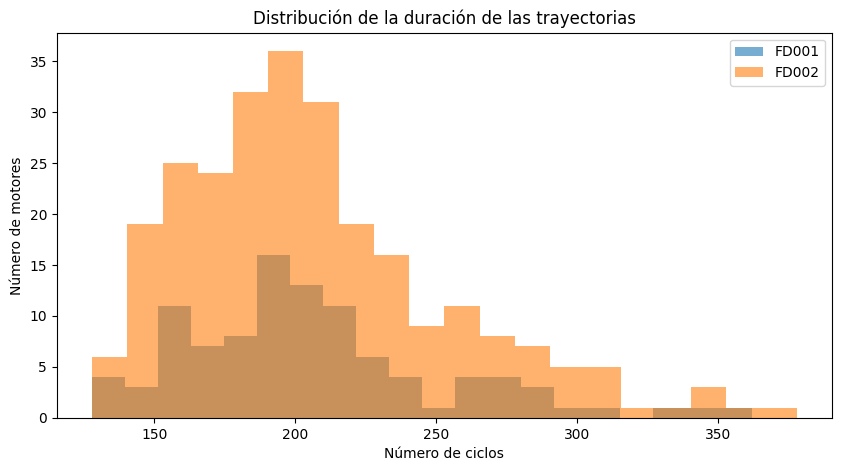

In [5]:
ciclos_fd001 = train_fd001.groupby("unit")["cycle"].max()
ciclos_fd002 = train_fd002.groupby("unit")["cycle"].max()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(ciclos_fd001, bins=20, alpha=0.6, label="FD001")
ax.hist(ciclos_fd002, bins=20, alpha=0.6, label="FD002")

ax.set_title("Distribución de la duración de las trayectorias")
ax.set_xlabel("Número de ciclos")
ax.set_ylabel("Número de motores")
ax.legend()

plt.show()

FD001 contiene 20.631 observaciones correspondientes a 100 motores, mientras que FD002 contiene 53.759 observaciones de 260 motores.

A pesar de esta diferencia en el tamaño total de los conjuntos, la duración de las trayectorias es muy similar en ambos escenarios. FD001 presenta una duración media de 206,31 ciclos y una mediana de 199 ciclos, mientras que en FD002 estos valores son de 206,77 y 199 ciclos, respectivamente.

La dispersión también es prácticamente equivalente, con desviaciones estándar de 46,34 ciclos en FD001 y 46,78 ciclos en FD002. En ambos conjuntos la trayectoria más corta contiene 128 ciclos, mientras que los máximos son de 362 ciclos para FD001 y 378 para FD002.

La representación de las distribuciones confirma que las longitudes de vida de los motores presentan un comportamiento muy parecido en ambos subconjuntos. Por tanto, las diferencias que se analicen posteriormente no pueden atribuirse inicialmente a una modificación importante en la duración de las trayectorias.

Además, no se detectaron valores nulos ni registros duplicados para ninguna combinación `unit-cycle`, y ambos conjuntos presentan la misma distribución de tipos de datos: 22 variables de tipo `float64` y 4 de tipo `int64`.

En conjunto, estos resultados muestran que FD001 y FD002 presentan una estructura temporal comparable. La principal diferencia entre ambos escenarios deberá buscarse, por tanto, en el comportamiento de las condiciones operativas y en su influencia sobre las mediciones de los sensores.

## 3. Comparación inicial de las variables

Una vez comprobada la similitud estructural entre ambos conjuntos, se analiza la variabilidad de las tres variables operativas y los 21 sensores.

El objetivo de esta comparación es determinar si las decisiones de selección de variables realizadas anteriormente sobre FD001 continúan siendo válidas en FD002.

En particular, resulta relevante comprobar si las variables que eran constantes o prácticamente constantes en FD001 mantienen este comportamiento cuando existen múltiples condiciones operativas.

In [6]:
variables_analisis = (
    [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

comparacion_variables = []

for variable in variables_analisis:
    comparacion_variables.append({
        "Variable": variable,

        "Únicos FD001": train_fd001[variable].nunique(),
        "Únicos FD002": train_fd002[variable].nunique(),

        "Media FD001": train_fd001[variable].mean(),
        "Media FD002": train_fd002[variable].mean(),

        "Std FD001": train_fd001[variable].std(),
        "Std FD002": train_fd002[variable].std(),

        "Mín FD001": train_fd001[variable].min(),
        "Máx FD001": train_fd001[variable].max(),

        "Mín FD002": train_fd002[variable].min(),
        "Máx FD002": train_fd002[variable].max(),
    })

comparacion_variables = pd.DataFrame(comparacion_variables)

comparacion_variables

,Variable,Únicos FD001,Únicos FD002,Media FD001,Media FD002,Std FD001,Std FD002,Mín FD001,Máx FD001,Mín FD002,Máx FD002
0,op_setting_1,158,536,-0.000009,23.998407,2.187313e-03,14.747376,-0.0087,0.0087,0.0000,42.0080
1,op_setting_2,13,105,0.000002,0.572056,2.930621e-04,0.310016,-0.0006,0.0006,0.0000,0.8420
2,op_setting_3,1,2,100.000000,94.046020,0.000000e+00,14.237735,100.0000,100.0000,60.0000,100.0000
3,sensor_1,1,6,518.670000,472.910207,6.537152e-11,26.389707,518.6700,518.6700,445.0000,518.6700
4,sensor_2,310,1590,642.680934,579.672399,5.000533e-01,37.289399,641.2100,644.5300,535.5300,644.5200
5,sensor_3,3012,12305,1590.523119,1419.971013,6.131150e+00,105.946341,1571.0400,1616.9100,1243.7300,1612.8800
6,sensor_4,4051,15411,1408.933782,1205.442024,9.000605e+00,119.123428,1382.2500,1441.4900,1023.7700,1439.2300
7,sensor_5,1,6,14.620000,8.031986,3.394700e-12,3.613839,14.6200,14.6200,3.9100,14.6200
8,sensor_6,2,14,21.609803,11.600746,1.388985e-03,5.431802,21.6000,21.6100,5.7100,21.6100
9,sensor_7,513,2067,553.367711,282.606787,8.850923e-01,146.005306,549.8500,556.0600,136.8000,555.8200


In [7]:
constantes_fd001 = comparacion_variables[
    comparacion_variables["Únicos FD001"] == 1
][["Variable", "Únicos FD001", "Únicos FD002", "Std FD001", "Std FD002"]]

print("Variables constantes en FD001 y comportamiento en FD002:")
display(constantes_fd001)

Variables constantes en FD001 y comportamiento en FD002:


,Variable,Únicos FD001,Únicos FD002,Std FD001,Std FD002
2,op_setting_3,1,2,0.000000e+00,14.237735
3,sensor_1,1,6,6.537152e-11,26.389707
7,sensor_5,1,6,3.394700e-12,3.613839
12,sensor_10,1,9,4.660829e-13,0.127469
18,sensor_16,1,2,1.556432e-14,0.004711
20,sensor_18,1,6,0.000000e+00,145.327980
21,sensor_19,1,2,0.000000e+00,5.364067


In [8]:
constantes_fd002 = comparacion_variables[
    comparacion_variables["Únicos FD002"] == 1
][["Variable", "Únicos FD001", "Únicos FD002", "Std FD001", "Std FD002"]]

print("Variables constantes en FD002:")
display(constantes_fd002)

Variables constantes en FD002:


,Variable,Únicos FD001,Únicos FD002,Std FD001,Std FD002


La comparación muestra que las decisiones de selección de variables realizadas sobre FD001 no pueden trasladarse directamente a FD002.

En FD001, `op_setting_3` y los sensores `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19` habían sido considerados constantes y, por tanto, se eliminaron durante el preprocesamiento. Sin embargo, ninguna de estas variables permanece constante en FD002.

También resulta relevante el comportamiento de `sensor_6`. Aunque no era estrictamente constante en FD001, presentaba una variabilidad muy reducida y fue descartado durante el preprocesamiento de dicho subconjunto. En FD002, sin embargo, presenta 14 valores diferentes y una desviación estándar considerablemente superior. Este resultado refuerza la necesidad de revisar nuevamente su utilidad antes de decidir si debe excluirse del modelado.

Las diferencias son especialmente claras en `sensor_1`, `sensor_5` y `sensor_18`, que pasan de presentar un único valor en FD001 a seis valores diferentes en FD002. `op_setting_3`, `sensor_16` y `sensor_19` presentan dos valores, mientras que `sensor_10` alcanza nueve valores diferentes.

Además, los sensores utilizados posteriormente en los modelos de FD001 también presentan una variabilidad considerablemente superior en FD002. Por ejemplo, `sensor_2`, `sensor_3`, `sensor_4`, `sensor_7`, `sensor_8`, `sensor_11` y `sensor_12` muestran desviaciones estándar muy superiores a las observadas en FD001.

No obstante, este incremento de variabilidad no implica necesariamente que estas variables contengan más información sobre la degradación. Una parte importante de las diferencias puede estar provocada por la existencia de múltiples condiciones operativas.

De hecho, el número de valores diferentes observado en algunas variables sugiere una posible relación con los distintos regímenes de funcionamiento. En particular, `sensor_1`, `sensor_5` y `sensor_18` presentan exactamente seis valores diferentes, coincidiendo con el número de condiciones operativas conocidas de FD002. Esta correspondencia se estudiará posteriormente al analizar las variables dentro de cada régimen.

Por tanto, antes de decidir qué sensores deben utilizarse para el modelado, será necesario estudiar el comportamiento de las variables dentro de cada régimen operativo. Una variable que presenta una elevada variabilidad global podría mostrar una variabilidad muy reducida dentro de cada condición y estar reflejando principalmente cambios de funcionamiento en lugar de degradación.

En consecuencia, no se realizará todavía ninguna selección de sensores para FD002.

## 4. Análisis de las variables operativas

FD002 incorpora seis condiciones operativas diferentes, por lo que antes de analizar en detalle los sensores es necesario estudiar cómo se representan estas condiciones mediante `op_setting_1`, `op_setting_2` y `op_setting_3`.

A diferencia de FD001, donde las variables operativas presentan una variación muy reducida alrededor de una única condición de funcionamiento, FD002 muestra una dispersión considerablemente mayor.

El objetivo de este apartado es identificar la estructura de los regímenes operativos presentes en FD002 y determinar posteriormente cómo afectan a las mediciones de los sensores.

In [9]:
op_settings = ["op_setting_1", "op_setting_2", "op_setting_3"]

for variable in op_settings:
    print(f"\n{variable}")
    print("-" * 40)

    print("FD001")
    print(train_fd001[variable].describe())

    print("\nFD002")
    print(train_fd002[variable].describe())


op_setting_1
----------------------------------------
FD001
count    20631.000000
mean        -0.000009
std          0.002187
min         -0.008700
25%         -0.001500
50%          0.000000
75%          0.001500
max          0.008700
Name: op_setting_1, dtype: float64

FD002
count    53759.000000
mean        23.998407
std         14.747376
min          0.000000
25%         10.004600
50%         25.001300
75%         41.998000
max         42.008000
Name: op_setting_1, dtype: float64

op_setting_2
----------------------------------------
FD001
count    20631.000000
mean         0.000002
std          0.000293
min         -0.000600
25%         -0.000200
50%          0.000000
75%          0.000300
max          0.000600
Name: op_setting_2, dtype: float64

FD002
count    53759.000000
mean         0.572056
std          0.310016
min          0.000000
25%          0.250700
50%          0.700000
75%          0.840000
max          0.842000
Name: op_setting_2, dtype: float64

op_setting_3
------

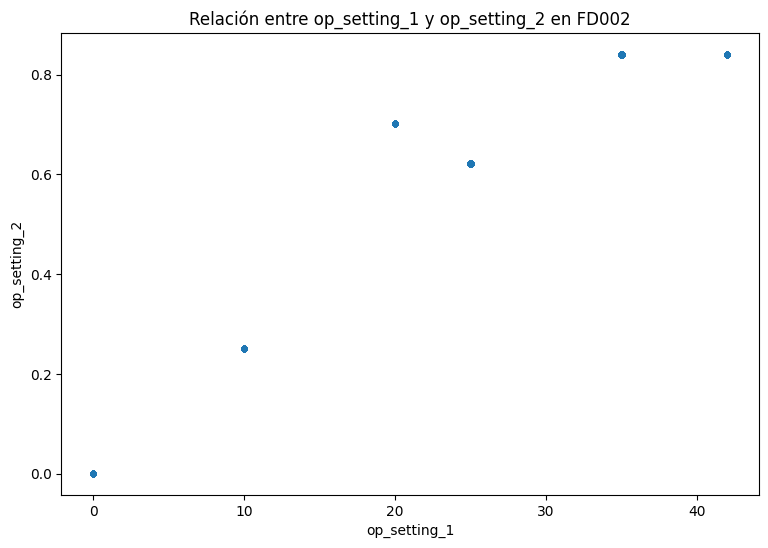

In [10]:
plt.figure(figsize=(9, 6))

plt.scatter(
    train_fd002["op_setting_1"],
    train_fd002["op_setting_2"],
    s=8,
    alpha=0.3
)

plt.xlabel("op_setting_1")
plt.ylabel("op_setting_2")
plt.title("Relación entre op_setting_1 y op_setting_2 en FD002")

plt.show()

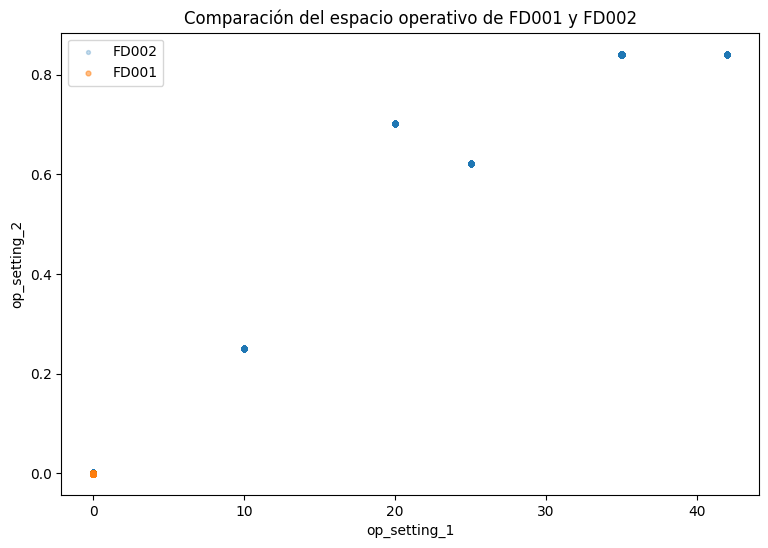

In [11]:
plt.figure(figsize=(9, 6))

plt.scatter(
    train_fd002["op_setting_1"],
    train_fd002["op_setting_2"],
    s=8,
    alpha=0.25,
    label="FD002"
)

plt.scatter(
    train_fd001["op_setting_1"],
    train_fd001["op_setting_2"],
    s=12,
    alpha=0.5,
    label="FD001"
)

plt.xlabel("op_setting_1")
plt.ylabel("op_setting_2")
plt.title("Comparación del espacio operativo de FD001 y FD002")
plt.legend()

plt.show()

Las variables operativas presentan comportamientos claramente diferentes entre FD001 y FD002.

En FD001, `op_setting_1` y `op_setting_2` presentan únicamente pequeñas variaciones alrededor de cero, mientras que `op_setting_3` permanece constante en 100. Este comportamiento es coherente con la existencia de una única condición operativa.

En FD002, por el contrario, la representación conjunta de `op_setting_1` y `op_setting_2` muestra seis grupos claramente separados. Las observaciones no se distribuyen de forma continua entre estos valores, sino que se concentran alrededor de seis combinaciones diferentes, confirmando visualmente la existencia de los seis regímenes operativos descritos para este subconjunto.

Al superponer FD001 sobre el espacio operativo de FD002 se observa que su única condición se sitúa aproximadamente sobre uno de los grupos de FD002, concretamente el localizado alrededor de `op_setting_1 = 0` y `op_setting_2 = 0`.

Este resultado sugiere que la condición operativa de FD001 podría estar incluida dentro del espacio operacional representado por FD002. No obstante, antes de establecer esta correspondencia será necesario considerar también `op_setting_3` e identificar formalmente las seis condiciones presentes en FD002.

Por tanto, el siguiente paso consiste en caracterizar cada régimen operativo y comprobar si la condición de FD001 coincide efectivamente con uno de ellos.

### 4.1. Caracterización de los seis regímenes operativos

La representación anterior permite distinguir visualmente seis grupos, pero es necesario caracterizar sus valores para comprobar qué combinación de las tres variables operativas corresponde a cada condición.

Las variables presentan pequeñas variaciones alrededor de determinados valores nominales. Por este motivo, se realiza inicialmente una aproximación mediante redondeo con el único objetivo de identificar las combinaciones operativas presentes en FD002.

Este procedimiento se utiliza en esta etapa como herramienta exploratoria y no constituye todavía el método definitivo para asignar nuevos datos a un régimen operativo.

In [12]:
operaciones_fd002 = train_fd002[
    ["unit", "op_setting_1", "op_setting_2", "op_setting_3"]
].copy()

operaciones_fd002["op_setting_1_nominal"] = (
    operaciones_fd002["op_setting_1"].round(0)
)

operaciones_fd002["op_setting_2_nominal"] = (
    operaciones_fd002["op_setting_2"].round(2)
)

operaciones_fd002["op_setting_3_nominal"] = (
    operaciones_fd002["op_setting_3"].round(0)
)

regimenes_fd002 = (
    operaciones_fd002
    .groupby([
        "op_setting_1_nominal",
        "op_setting_2_nominal",
        "op_setting_3_nominal"
    ])
    .agg(
        Observaciones=("unit", "size"),
        Motores=("unit", "nunique"),
        op_setting_1_medio=("op_setting_1", "mean"),
        op_setting_2_medio=("op_setting_2", "mean"),
        op_setting_3_medio=("op_setting_3", "mean")
    )
    .reset_index()
    .sort_values("op_setting_1_medio")
)

print("Número de combinaciones operativas identificadas:", len(regimenes_fd002))

display(regimenes_fd002)

Número de combinaciones operativas identificadas: 6


,op_setting_1_nominal,op_setting_2_nominal,op_setting_3_nominal,Observaciones,Motores,op_setting_1_medio,op_setting_2_medio,op_setting_3_medio
0,0.0,0.00,100.0,8044,260,0.001505,0.000494,100.0
1,10.0,0.25,100.0,8096,260,10.002971,0.250495,100.0
2,20.0,0.70,100.0,8122,260,20.002999,0.700515,100.0
3,25.0,0.62,60.0,8002,260,25.003038,0.620502,60.0
4,35.0,0.84,100.0,8037,260,35.003049,0.840501,100.0
5,42.0,0.84,100.0,13458,260,42.002976,0.840485,100.0


In [13]:
condicion_fd001 = pd.DataFrame({
    "Variable": [
        "op_setting_1",
        "op_setting_2",
        "op_setting_3"
    ],
    "Media FD001": [
        train_fd001["op_setting_1"].mean(),
        train_fd001["op_setting_2"].mean(),
        train_fd001["op_setting_3"].mean()
    ],
    "Std FD001": [
        train_fd001["op_setting_1"].std(),
        train_fd001["op_setting_2"].std(),
        train_fd001["op_setting_3"].std()
    ]
})

display(condicion_fd001)

,Variable,Media FD001,Std FD001
0,op_setting_1,-0.000009,0.002187
1,op_setting_2,0.000002,0.000293
2,op_setting_3,100.000000,0.000000


La aproximación mediante los valores nominales de las variables operativas permitió identificar exactamente seis combinaciones diferentes en FD002, coincidiendo con las seis condiciones operativas descritas para este subconjunto.

Los regímenes identificados se encuentran aproximadamente centrados en las siguientes combinaciones:

- Régimen 1: `(0, 0, 100)`
- Régimen 2: `(10, 0.25, 100)`
- Régimen 3: `(20, 0.70, 100)`
- Régimen 4: `(25, 0.62, 60)`
- Régimen 5: `(35, 0.84, 100)`
- Régimen 6: `(42, 0.84, 100)`

Los seis regímenes aparecen en los 260 motores del conjunto de entrenamiento, lo que indica que las diferentes condiciones operativas no corresponden a grupos independientes de motores. Un mismo motor puede funcionar bajo distintas condiciones a lo largo de su trayectoria.

La distribución de observaciones es similar entre los cinco primeros regímenes, con aproximadamente 8.000 observaciones en cada uno, mientras que el sexto presenta una mayor frecuencia, con 13.458 observaciones.

La comparación con FD001 muestra además una correspondencia clara entre su única condición operativa y el primer régimen identificado en FD002. FD001 presenta valores medios de `op_setting_1` y `op_setting_2` prácticamente iguales a cero y mantiene `op_setting_3 = 100`, coincidiendo con la combinación nominal `(0, 0, 100)` de FD002.

Por tanto, los resultados sugieren que FD001 puede considerarse, desde el punto de vista de las variables operativas, un escenario restringido a una condición que también está representada dentro de FD002.

Este procedimiento se utiliza inicialmente para caracterizar las seis condiciones operativas. Las combinaciones nominales identificadas servirán posteriormente como referencia para definir un procedimiento reproducible de asignación de nuevas observaciones a los distintos regímenes.

## 5. Análisis de los sensores según el régimen operativo

Una vez identificados los seis regímenes de FD002 y comprobado que la condición de FD001 coincide con el régimen situado alrededor de `(0, 0, 100)`, se analiza cómo cambia el comportamiento de los sensores según la condición operativa.

Antes de estudiar la degradación, es necesario separar la variabilidad asociada al régimen de funcionamiento de la variabilidad que permanece dentro de cada condición.

Para ello, se asignará a cada observación de FD002 un identificador de régimen a partir de las combinaciones nominales de `op_setting_1`, `op_setting_2` y `op_setting_3`.

Esta clasificación se utiliza en esta etapa con finalidad exploratoria, aprovechando que los seis grupos aparecen claramente separados en el conjunto de entrenamiento.

### 5.1. Asignación de los regímenes operativos

A partir de las seis combinaciones identificadas anteriormente, se asigna a cada observación de FD002 un identificador de régimen entre 1 y 6.

Esta variable permitirá realizar posteriormente comparaciones entre las distribuciones de los sensores dentro de cada condición operativa.

In [14]:
regime_mapping = {
    (0.0, 0.00, 100.0): 1,
    (10.0, 0.25, 100.0): 2,
    (20.0, 0.70, 100.0): 3,
    (25.0, 0.62, 60.0): 4,
    (35.0, 0.84, 100.0): 5,
    (42.0, 0.84, 100.0): 6
}

train_fd002_reg = train_fd002.copy()

train_fd002_reg["op1_nominal"] = train_fd002_reg["op_setting_1"].round(0)
train_fd002_reg["op2_nominal"] = train_fd002_reg["op_setting_2"].round(2)
train_fd002_reg["op3_nominal"] = train_fd002_reg["op_setting_3"].round(0)

train_fd002_reg["operating_regime"] = [
    regime_mapping[(op1, op2, op3)]
    for op1, op2, op3 in zip(
        train_fd002_reg["op1_nominal"],
        train_fd002_reg["op2_nominal"],
        train_fd002_reg["op3_nominal"]
    )
]

print(train_fd002_reg["operating_regime"].value_counts().sort_index())

operating_regime
1     8044
2     8096
3     8122
4     8002
5     8037
6    13458
Name: count, dtype: int64


### 5.2. Comparación entre FD001 y el régimen 1 de FD002

Una vez asignado un régimen operativo a cada observación de FD002, se compara el comportamiento de los 21 sensores de FD001 con las observaciones correspondientes al régimen 1 de FD002.

Esta comparación resulta especialmente relevante porque ambos escenarios presentan prácticamente la misma combinación de variables operativas, situada alrededor de `(0, 0, 100)`. El objetivo es comprobar si esta correspondencia también se mantiene en las mediciones de los sensores y determinar hasta qué punto FD001 puede considerarse equivalente al comportamiento de FD002 bajo esta condición operativa.

In [15]:
sensores = [f"sensor_{i}" for i in range(1, 22)]

fd002_regime1 = train_fd002_reg[
    train_fd002_reg["operating_regime"] == 1
]

comparacion_fd001_reg1 = []

for sensor in sensores:
    comparacion_fd001_reg1.append({
        "Sensor": sensor,

        "Media FD001": train_fd001[sensor].mean(),
        "Media FD002-R1": fd002_regime1[sensor].mean(),

        "Std FD001": train_fd001[sensor].std(),
        "Std FD002-R1": fd002_regime1[sensor].std(),

        "Mín FD001": train_fd001[sensor].min(),
        "Mín FD002-R1": fd002_regime1[sensor].min(),

        "Máx FD001": train_fd001[sensor].max(),
        "Máx FD002-R1": fd002_regime1[sensor].max()
    })

comparacion_fd001_reg1 = pd.DataFrame(comparacion_fd001_reg1)

display(comparacion_fd001_reg1)

,Sensor,Media FD001,Media FD002-R1,Std FD001,Std FD002-R1,Mín FD001,Mín FD002-R1,Máx FD001,Máx FD002-R1
0,sensor_1,518.670000,518.670000,6.537152e-11,5.116226e-11,518.6700,518.6700,518.6700,518.6700
1,sensor_2,642.680934,642.678721,5.000533e-01,4.959049e-01,641.2100,641.2400,644.5300,644.5200
2,sensor_3,1590.523119,1590.421137,6.131150e+00,6.022352e+00,1571.0400,1568.2400,1616.9100,1612.8800
3,sensor_4,1408.933782,1408.860945,9.000605e+00,8.936758e+00,1382.2500,1384.4900,1441.4900,1439.2300
4,sensor_5,14.620000,14.620000,3.394700e-12,1.424727e-12,14.6200,14.6200,14.6200,14.6200
5,sensor_6,21.609803,21.609831,1.388985e-03,1.289311e-03,21.6000,21.6000,21.6100,21.6100
6,sensor_7,553.367711,553.360726,8.850923e-01,8.680058e-01,549.8500,550.3600,556.0600,555.8200
7,sensor_8,2388.096652,2388.100476,7.098548e-02,7.088110e-02,2387.9000,2387.9200,2388.5600,2388.3900
8,sensor_9,9065.242941,9062.833793,2.208288e+01,1.921259e+01,9021.7300,9020.5800,9244.5900,9215.6600
9,sensor_10,1.300000,1.300000,4.660829e-13,5.706901e-14,1.3000,1.3000,1.3000,1.3000


La comparación entre FD001 y las observaciones de FD002 correspondientes al régimen operativo 1 muestra una elevada similitud en el comportamiento de los sensores.

Esta correspondencia resulta especialmente clara en las variables que habían sido eliminadas durante el preprocesamiento de FD001 por ser constantes. `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19` presentan exactamente los mismos valores en FD001 y en el régimen 1 de FD002.

Los sensores utilizados posteriormente como variables predictoras también muestran medias, dispersiones y rangos muy similares entre ambos conjuntos cuando la comparación se realiza bajo la misma condición operativa.

Por ejemplo, `sensor_2`, `sensor_3`, `sensor_4`, `sensor_7`, `sensor_11`, `sensor_12`, `sensor_15`, `sensor_17`, `sensor_20` y `sensor_21` presentan valores medios prácticamente equivalentes y niveles de dispersión comparables.

Las diferencias observadas previamente entre FD001 y FD002 al analizar los sensores de forma global parecen estar, por tanto, fuertemente relacionadas con la presencia de múltiples condiciones operativas en FD002.

Estos resultados refuerzan la hipótesis de que FD001 representa un escenario restringido a una condición operativa que también se encuentra presente dentro de FD002.

No obstante, esta equivalencia operacional no implica todavía que los modelos entrenados sobre FD001 puedan aplicarse directamente a todo FD002. Los restantes cinco regímenes presentan niveles diferentes en numerosas variables, por lo que será necesario estudiar cuánto de la variabilidad de cada sensor está explicado por el régimen operativo y cuánto permanece dentro de cada condición.

### 5.3. Influencia de los regímenes operativos sobre los sensores

La comparación anterior muestra que FD001 y el régimen 1 de FD002 presentan un comportamiento muy similar. Sin embargo, al considerar FD002 de forma global se habían observado diferencias muy elevadas en la variabilidad de numerosos sensores.

Por este motivo, se analiza ahora el comportamiento de los sensores dentro de cada uno de los seis regímenes operativos. El objetivo es determinar qué parte de la variabilidad global de FD002 está asociada a los cambios de condición de funcionamiento y qué variabilidad permanece dentro de cada régimen.

Este análisis permitirá distinguir entre sensores cuyo valor depende principalmente de la condición operativa y sensores que mantienen variabilidad dentro de una misma condición, aspecto necesario antes de realizar una nueva selección de variables o definir el preprocesamiento de FD002.

In [16]:
medias_por_regimen = (
    train_fd002_reg
    .groupby("operating_regime")[sensores]
    .mean()
    .T
)

medias_por_regimen.columns = [
    f"Régimen {i}" for i in medias_por_regimen.columns
]

display(medias_por_regimen)

,Régimen 1,Régimen 2,Régimen 3,Régimen 4,Régimen 5,Régimen 6
sensor_1,518.670000,489.050000,491.190000,462.540000,449.440000,445.000000
sensor_2,642.678721,604.913381,607.564851,536.865069,555.799163,549.704881
sensor_3,1590.421137,1502.012059,1485.587547,1262.684786,1366.713352,1354.463034
sensor_4,1408.860945,1311.253127,1253.118492,1050.320924,1131.530749,1127.802495
sensor_5,14.620000,10.520000,9.350000,7.050000,5.480000,3.910000
sensor_6,21.609831,15.493286,13.656623,9.027761,8.000296,5.715840
sensor_7,553.360726,394.324910,334.496711,175.425952,194.443407,138.630382
sensor_8,2388.100476,2318.958436,2324.021300,1915.415771,2223.040616,2211.971548
sensor_9,9062.833793,8785.436437,8729.768692,8015.498543,8356.103228,8327.889811
sensor_10,1.300000,1.259996,1.077731,0.939921,1.020391,1.020244


In [17]:
std_por_regimen = (
    train_fd002_reg
    .groupby("operating_regime")[sensores]
    .std()
    .T
)

std_por_regimen.columns = [
    f"Régimen {i}" for i in std_por_regimen.columns
]

display(std_por_regimen)

,Régimen 1,Régimen 2,Régimen 3,Régimen 4,Régimen 5,Régimen 6
sensor_1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
sensor_2,0.495905,0.474500,0.463106,0.358128,0.439489,0.432850
sensor_3,6.022352,5.790149,5.783238,5.280543,5.615667,5.633500
sensor_4,8.936758,8.457488,7.793733,6.808897,7.401791,7.637032
sensor_5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
sensor_6,0.001289,0.004697,0.004735,0.004181,0.001695,0.004929
sensor_7,0.868006,0.671447,0.606028,0.447735,0.476396,0.439125
sensor_8,0.070881,0.094500,0.126394,0.262289,0.278866,0.299728
sensor_9,19.212587,18.250509,17.210709,14.099908,16.989014,18.014406
sensor_10,0.000000,0.000192,0.004189,0.000884,0.001938,0.001544


In [18]:
influencia_regimen = []

for sensor in sensores:
    valores = train_fd002_reg[sensor]
    media_global = valores.mean()

    ss_total = ((valores - media_global) ** 2).sum()

    ss_between = 0

    for _, grupo in train_fd002_reg.groupby("operating_regime"):
        n = len(grupo)
        media_grupo = grupo[sensor].mean()

        ss_between += n * (media_grupo - media_global) ** 2

    eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

    std_global = valores.std()

    std_media_intra = (
        train_fd002_reg
        .groupby("operating_regime")[sensor]
        .std()
        .mean()
    )

    influencia_regimen.append({
        "Sensor": sensor,
        "Std global FD002": std_global,
        "Std media dentro de régimen": std_media_intra,
        "Eta² régimen": eta_squared
    })

influencia_regimen = pd.DataFrame(influencia_regimen)

influencia_regimen = influencia_regimen.sort_values(
    "Eta² régimen",
    ascending=False
)

display(influencia_regimen)

,Sensor,Std global FD002,Std media dentro de régimen,Eta² régimen
4,sensor_5,3.613839,0.000000,1.000000
17,sensor_18,145.327980,0.000000,1.000000
0,sensor_1,26.389707,0.000000,1.000000
18,sensor_19,5.364067,0.000000,1.000000
5,sensor_6,5.431802,0.003588,0.999999
7,sensor_8,145.209816,0.188776,0.999998
12,sensor_13,128.068271,0.199709,0.999997
11,sensor_12,137.659507,0.471193,0.999988
6,sensor_7,146.005306,0.584790,0.999984
1,sensor_2,37.289399,0.443996,0.999858


Los resultados muestran que una parte muy elevada de la variabilidad observada en los sensores de FD002 está asociada a los cambios de régimen operativo.

Los sensores `sensor_1`, `sensor_5`, `sensor_18` y `sensor_19` presentan una desviación estándar igual a cero dentro de cada régimen y un valor de η² igual a 1. Esto indica que toda su variabilidad global está explicada por las diferencias entre condiciones operativas. Dentro de un mismo régimen permanecen constantes, por lo que no aportan información sobre cambios progresivos del estado del motor.

Un comportamiento similar aparece en `sensor_6`, `sensor_8`, `sensor_10`, `sensor_13`, `sensor_12`, `sensor_7`, `sensor_2`, `sensor_20` y `sensor_21`, cuyos valores de η² son superiores a 0,999. Aunque estos sensores sí presentan cierta variabilidad dentro de cada condición, la mayor parte de su dispersión global está explicada por las diferencias entre regímenes.

Los sensores `sensor_3`, `sensor_4`, `sensor_9`, `sensor_11`, `sensor_14`, `sensor_15` y `sensor_17` también presentan una fuerte influencia de las condiciones operativas, aunque mantienen una variabilidad interna mayor. Entre ellos, `sensor_14` presenta el menor valor de η² de este grupo, aproximadamente 0,966, lo que indica que conserva una proporción relativamente mayor de variabilidad dentro de los regímenes.

`Sensor_16` presenta el menor valor de η², aproximadamente 0,885. No obstante, sus valores absolutos presentan una variabilidad muy reducida, por lo que este resultado no implica necesariamente que sea una variable especialmente útil para representar la degradación.

En conjunto, el análisis confirma que comparar directamente la variabilidad global de los sensores en FD002 puede resultar engañoso. Los elevados valores de desviación estándar observados previamente están provocados en gran medida por los cambios entre condiciones operativas.

Esto resulta especialmente relevante para el desarrollo de los modelos predictivos. Un modelo entrenado directamente sobre los valores globales podría aprender principalmente las diferencias entre regímenes de funcionamiento en lugar de los cambios asociados a la degradación.

Por tanto, antes de realizar una selección de variables o entrenar los modelos de FD002 será necesario estudiar el comportamiento de los sensores dentro de cada régimen operativo y comprobar si mantienen relaciones consistentes con la proximidad al final de vida.

### 5.4. Relación entre los sensores y la degradación dentro de cada régimen

El análisis anterior muestra que las condiciones operativas explican gran parte de la variabilidad global de los sensores en FD002. Sin embargo, para el mantenimiento predictivo resulta especialmente relevante la variabilidad que permanece dentro de cada régimen.

Por este motivo, se estudia ahora la relación entre las mediciones de los sensores y la vida útil restante manteniendo separadas las diferentes condiciones operativas.

Como el conjunto de entrenamiento contiene trayectorias completas hasta el final de vida, puede calcularse la RUL de cada observación a partir del último ciclo disponible de cada motor.

La RUL se utilizará únicamente como referencia para estudiar el comportamiento de las variables y no como entrada de los futuros modelos predictivos.

In [19]:
max_cycles_fd002 = (
    train_fd002_reg
    .groupby("unit")["cycle"]
    .max()
    .rename("max_cycle")
)

train_fd002_reg = train_fd002_reg.merge(
    max_cycles_fd002,
    on="unit",
    how="left"
)

train_fd002_reg["RUL"] = (
    train_fd002_reg["max_cycle"]
    - train_fd002_reg["cycle"]
)

print(train_fd002_reg["RUL"].describe())

count    53759.000000
mean       108.154746
std         69.180569
min          0.000000
25%         51.000000
50%        103.000000
75%        156.000000
max        377.000000
Name: RUL, dtype: float64


In [20]:
correlaciones_regimen = []

for regimen in sorted(train_fd002_reg["operating_regime"].unique()):
    datos_regimen = train_fd002_reg[
        train_fd002_reg["operating_regime"] == regimen
    ]

    for sensor in sensores:
        correlacion = datos_regimen[
            [sensor, "RUL"]
        ].corr(method="spearman").iloc[0, 1]

        correlaciones_regimen.append({
            "Régimen": regimen,
            "Sensor": sensor,
            "Spearman_RUL": correlacion
        })

correlaciones_regimen = pd.DataFrame(correlaciones_regimen)

tabla_correlaciones = (
    correlaciones_regimen
    .pivot(
        index="Sensor",
        columns="Régimen",
        values="Spearman_RUL"
    )
)

tabla_correlaciones.columns = [
    f"Régimen {i}"
    for i in tabla_correlaciones.columns
]

display(tabla_correlaciones)

,Régimen 1,Régimen 2,Régimen 3,Régimen 4,Régimen 5,Régimen 6
Sensor,,,,,,
sensor_1,NaN,NaN,NaN,NaN,NaN,NaN
sensor_10,NaN,0.031456,0.399188,0.062416,0.103771,-0.206704
sensor_11,-0.735137,-0.721841,-0.704461,-0.693369,-0.712697,-0.714021
sensor_12,0.712354,0.654492,0.613286,0.382370,0.460266,0.297486
sensor_13,-0.607822,-0.741496,-0.695334,-0.149453,-0.176783,-0.046802
sensor_14,-0.132428,-0.139728,-0.152696,-0.215673,-0.140071,-0.154071
sensor_15,-0.671523,-0.684517,-0.686549,-0.714983,-0.682251,-0.620867
sensor_16,NaN,NaN,-0.597503,NaN,NaN,NaN
sensor_17,-0.628097,-0.622693,-0.612554,-0.543347,-0.594118,-0.607972


In [21]:
resumen_correlaciones = pd.DataFrame({
    "Sensor": tabla_correlaciones.index,
    "Spearman medio": tabla_correlaciones.mean(axis=1).values,
    "|Spearman| medio": tabla_correlaciones.abs().mean(axis=1).values,
    "Spearman mínimo": tabla_correlaciones.min(axis=1).values,
    "Spearman máximo": tabla_correlaciones.max(axis=1).values
})

resumen_correlaciones["Regímenes válidos"] = (
    tabla_correlaciones.notna().sum(axis=1).values
)

resumen_correlaciones["Mismo signo en los 6 regímenes"] = [
    (
        fila.notna().sum() == 6
        and (
            (fila.dropna() > 0).all()
            or (fila.dropna() < 0).all()
        )
    )
    for _, fila in tabla_correlaciones.iterrows()
]

resumen_correlaciones = resumen_correlaciones.sort_values(
    "|Spearman| medio",
    ascending=False
)

display(resumen_correlaciones)

,Sensor,Spearman medio,|Spearman| medio,Spearman mínimo,Spearman máximo,Regímenes válidos,Mismo signo en los 6 regímenes
2,sensor_11,-0.713588,0.713588,-0.735137,-0.693369,6,True
15,sensor_4,-0.682275,0.682275,-0.717528,-0.645732,6,True
6,sensor_15,-0.676782,0.676782,-0.714983,-0.620867,6,True
8,sensor_17,-0.601464,0.601464,-0.628097,-0.543347,6,True
7,sensor_16,-0.597503,0.597503,-0.597503,-0.597503,1,False
11,sensor_2,-0.586405,0.586405,-0.641990,-0.447206,6,True
14,sensor_3,-0.574220,0.574220,-0.612010,-0.524642,6,True
3,sensor_12,0.520042,0.520042,0.297486,0.712354,6,True
18,sensor_7,0.494202,0.494202,0.292023,0.699299,6,True
12,sensor_20,0.470780,0.470780,0.282771,0.668355,6,True


Los resultados muestran que, una vez separadas las observaciones según su régimen operativo, varios sensores mantienen una relación consistente con la vida útil restante.

Los sensores `sensor_11`, `sensor_4`, `sensor_15`, `sensor_17`, `sensor_2` y `sensor_3` presentan correlaciones negativas con la RUL en los seis regímenes. Entre ellos destacan especialmente `sensor_11`, `sensor_4` y `sensor_15`, con valores medios de correlación de Spearman de aproximadamente -0,714, -0,682 y -0,677, respectivamente.

De forma complementaria, `sensor_12`, `sensor_7`, `sensor_20` y `sensor_21` presentan correlaciones positivas en las seis condiciones operativas. Esto indica que su relación con la proximidad al final de vida mantiene el mismo sentido independientemente del régimen de funcionamiento.

Los sensores `sensor_8` y `sensor_13` presentan un comportamiento diferente. En los primeros regímenes muestran relaciones negativas de magnitud considerable con la RUL, pero estas asociaciones se reducen notablemente en los regímenes 4, 5 y 6. Por tanto, aunque pueden contener información relacionada con la degradación, dicha relación no presenta la misma intensidad bajo todas las condiciones operativas.

`Sensor_9` y `sensor_14` mantienen una correlación negativa consistente, aunque de menor magnitud. `Sensor_6` también presenta correlaciones negativas en los seis regímenes, pero con una intensidad muy variable entre condiciones.

Por otro lado, `sensor_1`, `sensor_5`, `sensor_18` y `sensor_19` permanecen constantes dentro de cada régimen, por lo que no es posible calcular una correlación con la RUL. Su variabilidad global en FD002 está asociada exclusivamente a los cambios de condición operativa.

`Sensor_16` únicamente presenta variabilidad suficiente para calcular una correlación en uno de los seis regímenes, mientras que `sensor_10` muestra relaciones débiles e incluso cambios de signo. Estos resultados no proporcionan evidencia suficiente para considerarlos variables robustas de degradación entre condiciones.

En conjunto, el análisis muestra que varias de las variables seleccionadas previamente en FD001 mantienen una relación consistente con la RUL cuando FD002 se analiza separando los regímenes operativos. Esto sugiere que la selección inicial de sensores realizada sobre FD001 continúa siendo, en gran medida, relevante para FD002.

Sin embargo, la elevada influencia de las condiciones operativas sobre los niveles absolutos de los sensores indica que no sería adecuado utilizar directamente sus valores globales sin considerar el régimen de funcionamiento.

### 5.5. Revisión de la selección de sensores

A partir de los resultados anteriores se revisa la selección de variables realizada durante el preprocesamiento de FD001.

El objetivo es comprobar si los 14 sensores utilizados posteriormente por los modelos de FD001 continúan siendo adecuados en FD002 o si la existencia de múltiples condiciones operativas justifica modificar dicha selección.

Para ello, se comparará la selección original con el comportamiento observado dentro de los seis regímenes, teniendo en cuenta la variabilidad interna, la magnitud de la relación con la RUL y la consistencia de dicha relación entre condiciones.

In [22]:
resumen_correlaciones = []

for sensor in tabla_correlaciones.index:
    valores = tabla_correlaciones.loc[sensor].dropna()

    n_regimenes_validos = len(valores)

    mismo_signo = (
        n_regimenes_validos == 6
        and (
            (valores > 0).all()
            or (valores < 0).all()
        )
    )

    resumen_correlaciones.append({
        "Sensor": sensor,
        "Regímenes válidos": n_regimenes_validos,
        "Spearman medio": valores.mean() if n_regimenes_validos > 0 else np.nan,
        "|Spearman| medio": valores.abs().mean() if n_regimenes_validos > 0 else np.nan,
        "Spearman mínimo": valores.min() if n_regimenes_validos > 0 else np.nan,
        "Spearman máximo": valores.max() if n_regimenes_validos > 0 else np.nan,
        "Mismo signo en los 6 regímenes": mismo_signo
    })

resumen_correlaciones = pd.DataFrame(resumen_correlaciones)

resumen_correlaciones = resumen_correlaciones.sort_values(
    ["Regímenes válidos", "|Spearman| medio"],
    ascending=[False, False]
)

display(resumen_correlaciones)

,Sensor,Regímenes válidos,Spearman medio,|Spearman| medio,Spearman mínimo,Spearman máximo,Mismo signo en los 6 regímenes
2,sensor_11,6,-0.713588,0.713588,-0.735137,-0.693369,True
15,sensor_4,6,-0.682275,0.682275,-0.717528,-0.645732,True
6,sensor_15,6,-0.676782,0.676782,-0.714983,-0.620867,True
8,sensor_17,6,-0.601464,0.601464,-0.628097,-0.543347,True
11,sensor_2,6,-0.586405,0.586405,-0.641990,-0.447206,True
14,sensor_3,6,-0.574220,0.574220,-0.612010,-0.524642,True
3,sensor_12,6,0.520042,0.520042,0.297486,0.712354,True
18,sensor_7,6,0.494202,0.494202,0.292023,0.699299,True
12,sensor_20,6,0.470780,0.470780,0.282771,0.668355,True
13,sensor_21,6,0.463453,0.463453,0.281309,0.662715,True


In [23]:
sensores_fd001 = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

revision_sensores = resumen_correlaciones.copy()

revision_sensores["Seleccionado en FD001"] = (
    revision_sensores["Sensor"].isin(sensores_fd001)
)

display(revision_sensores)

,Sensor,Regímenes válidos,Spearman medio,|Spearman| medio,Spearman mínimo,Spearman máximo,Mismo signo en los 6 regímenes,Seleccionado en FD001
2,sensor_11,6,-0.713588,0.713588,-0.735137,-0.693369,True,True
15,sensor_4,6,-0.682275,0.682275,-0.717528,-0.645732,True,True
6,sensor_15,6,-0.676782,0.676782,-0.714983,-0.620867,True,True
8,sensor_17,6,-0.601464,0.601464,-0.628097,-0.543347,True,True
11,sensor_2,6,-0.586405,0.586405,-0.641990,-0.447206,True,True
14,sensor_3,6,-0.574220,0.574220,-0.612010,-0.524642,True,True
3,sensor_12,6,0.520042,0.520042,0.297486,0.712354,True,True
18,sensor_7,6,0.494202,0.494202,0.292023,0.699299,True,True
12,sensor_20,6,0.470780,0.470780,0.282771,0.668355,True,True
13,sensor_21,6,0.463453,0.463453,0.281309,0.662715,True,True


Los resultados permiten revisar con mayor precisión la selección de sensores realizada anteriormente sobre FD001.

Los 14 sensores utilizados en los modelos de FD001 mantienen variabilidad suficiente dentro de los seis regímenes de FD002 y presentan relaciones con la RUL del mismo signo en todas las condiciones operativas.

Entre ellos destacan `sensor_11`, `sensor_4`, `sensor_15`, `sensor_17`, `sensor_2` y `sensor_3`, que presentan las mayores correlaciones medias en valor absoluto y mantienen un comportamiento relativamente estable entre regímenes.

Los sensores `sensor_12`, `sensor_7`, `sensor_20` y `sensor_21` también mantienen relaciones consistentes con la RUL, aunque su magnitud disminuye en algunos de los regímenes.

Por otro lado, `sensor_8` y `sensor_13` presentan correlaciones elevadas en determinadas condiciones, pero su asociación con la RUL se reduce considerablemente en los regímenes 4, 5 y 6. `sensor_9` y `sensor_14` mantienen una relación del mismo signo en todos los regímenes, aunque de menor magnitud.

Un resultado adicional es el comportamiento de `sensor_6`. Esta variable había sido excluida en FD001 debido a su variabilidad prácticamente nula. En FD002, sin embargo, presenta variabilidad dentro de los seis regímenes y mantiene una correlación negativa con la RUL en todos ellos. No obstante, la magnitud de esta relación varía considerablemente entre condiciones, por lo que todavía no se considera suficiente para incorporarlo directamente como variable predictora.

Los sensores `sensor_1`, `sensor_5`, `sensor_18` y `sensor_19` no presentan variabilidad dentro de ninguno de los regímenes, mientras que `sensor_16` únicamente permite calcular una correlación en una condición y `sensor_10` presenta relaciones débiles y cambios de signo.

En conjunto, los resultados indican que la selección de 14 sensores realizada sobre FD001 continúa siendo una base adecuada para FD002. Sin embargo, todavía no se considera definitiva. Antes de mantenerla o modificarla se estudiará si una transformación que tenga en cuenta las condiciones operativas permite obtener una representación comparable entre los seis regímenes.

## 6. Tratamiento del efecto de las condiciones operativas

Los análisis anteriores muestran que los niveles absolutos de numerosos sensores dependen fuertemente del régimen operativo.

Esto implica que dos observaciones correspondientes a un estado de degradación similar pueden presentar valores de sensores muy diferentes únicamente por encontrarse bajo condiciones de funcionamiento distintas.

Antes de desarrollar los modelos de FD002 se estudiará una transformación orientada a reducir este efecto y obtener una representación más comparable entre regímenes.

Como primera aproximación exploratoria, se estandarizará cada sensor utilizando la media y la desviación estándar correspondientes a su propio régimen operativo:

$$
z = \frac{x-\mu_r}{\sigma_r}
$$

donde \(\mu_r\) y \(\sigma_r\) representan la media y la desviación estándar del sensor dentro del régimen \(r\).

El objetivo de esta transformación no es eliminar la información asociada a la degradación, sino retirar las diferencias de nivel provocadas por las distintas condiciones de funcionamiento.

En esta etapa se utilizará el conjunto completo de entrenamiento únicamente para analizar la viabilidad de la transformación. Durante el desarrollo posterior de los modelos, los parámetros necesarios para realizarla deberán ajustarse exclusivamente sobre los datos destinados al entrenamiento de cada fase, evitando utilizar información de los conjuntos de validación o test.

### 6.1. Normalización exploratoria por régimen

Se calcula para cada combinación de régimen operativo y sensor su media y desviación estándar. A continuación, cada observación se transforma utilizando únicamente las estadísticas correspondientes a la condición en la que fue registrada.

Los sensores constantes dentro de un régimen no pueden estandarizarse mediante esta expresión debido a que su desviación estándar es cero. Estas variables no resultan de interés para representar la degradación y se excluirán de esta comprobación.

In [24]:
sensores_candidatos = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

train_fd002_norm = train_fd002_reg.copy()

estadisticas_regimen = (
    train_fd002_norm
    .groupby("operating_regime")[sensores_candidatos]
    .agg(["mean", "std"])
)

for sensor in sensores_candidatos:
    medias = train_fd002_norm["operating_regime"].map(
        estadisticas_regimen[(sensor, "mean")]
    )

    stds = train_fd002_norm["operating_regime"].map(
        estadisticas_regimen[(sensor, "std")]
    )

    train_fd002_norm[f"{sensor}_norm"] = (
        train_fd002_norm[sensor] - medias
    ) / stds

In [25]:
sensores_norm = [
    f"{sensor}_norm"
    for sensor in sensores_candidatos
]

resumen_norm_regimen = (
    train_fd002_norm
    .groupby("operating_regime")[sensores_norm]
    .agg(["mean", "std"])
)

display(resumen_norm_regimen)

sensor_2_norm      sensor_3_norm      sensor_4_norm       \
                          mean  std          mean  std          mean  std   
operating_regime                                                            
1                 1.204411e-13  1.0 -1.394961e-14  1.0  1.260437e-14  1.0   
2                -1.215158e-13  1.0  1.028382e-15  1.0 -1.067997e-14  1.0   
3                 1.208078e-13  1.0 -9.606805e-17  1.0 -4.593661e-15  1.0   
4                 4.355704e-14  1.0  1.567496e-14  1.0 -3.229664e-15  1.0   
5                -1.353718e-13  1.0 -1.351640e-14  1.0 -1.579561e-14  1.0   
6                -7.865639e-15  1.0 -3.277288e-14  1.0 -1.013492e-14  1.0   

                 sensor_6_norm      sensor_7_norm       ... sensor_14_norm  \
                          mean  std          mean  std  ...           mean   
operating_regime                                        ...                  
1                 2.688359e-12  1.0 -1.851240e-14  1.0  ...  -2.826227e-14   
2                 1.279890e-13  1.0 -7.731930e-14  1.0  ...  -3.207788e-14   
3                 2.056267e-13  1.0 -5.067441e-14  1.0  ...  -4.803282e-14   
4                -3.877362e-14  1.0 -2.172913e-14  1.0  ...   5.926898e-14   
5                 5.451032e-13  1.0  1.191028e-14  1.0  ...   1.978161e-14   
6                -4.061913e-14  1.0  3.524482e-14  1.0  ...  -1.834024e-14   

                      sensor_15_norm      sensor_17_norm      sensor_20_norm  \
                  std           mean  std           mean  std           mean   
operating_regime                                                               
1                 1.0  -3.230247e-15  1.0   6.859616e-15  1.0   1.506006e-15   
2                 1.0  -1.876123e-14  1.0   1.639992e-15  1.0   1.273992e-14   
3                 1.0  -4.022244e-14  1.0  -8.783912e-16  1.0  -3.487579e-15   
4                 1.0  -3.965669e-15  1.0  -1.746438e-14  1.0  -1.027368e-14   
5                 1.0   1.433631e-14  1.0   8.605893e-15  1.0   2.770847e-15   
6                 1.0   1.638755e-14  1.0   9.287200e-15  1.0  -3.199496e-15   

                      sensor_21_norm       
                  std           mean  std  
operating_regime                           
1                 1.0  -1.567526e-14  1.0  
2                 1.0   1.954069e-14  1.0  
3                 1.0   5.527330e-15  1.0  
4                 1.0  -1.452253e-14  1.0  
5                 1.0   6.945324e-15  1.0  
6                 1.0  -1.415160e-14  1.0  

[6 rows x 30 columns]

### 6.2. Efecto de la normalización sobre la relación sensor–RUL

Una vez comprobado que la transformación iguala las medias y dispersiones de los sensores entre regímenes, se analiza si este tratamiento conserva la información relacionada con la degradación.

Para ello, se comparan las correlaciones globales de Spearman entre cada sensor y la RUL antes y después de aplicar la normalización por régimen.

In [26]:
correlaciones_normalizadas = []

for sensor in sensores_candidatos:
    sensor_norm = f"{sensor}_norm"

    spearman = train_fd002_norm[
        [sensor_norm, "RUL"]
    ].corr(method="spearman").iloc[0, 1]

    correlaciones_normalizadas.append({
        "Sensor": sensor,
        "Spearman global original": train_fd002_norm[
            [sensor, "RUL"]
        ].corr(method="spearman").iloc[0, 1],
        "Spearman tras normalización": spearman
    })

correlaciones_normalizadas = pd.DataFrame(
    correlaciones_normalizadas
)

correlaciones_normalizadas[
    "|Spearman normalizado|"
] = correlaciones_normalizadas[
    "Spearman tras normalización"
].abs()

correlaciones_normalizadas = correlaciones_normalizadas.sort_values(
    "|Spearman normalizado|",
    ascending=False
)

display(correlaciones_normalizadas)

,Sensor,Spearman global original,Spearman tras normalización,|Spearman normalizado|
7,sensor_11,-0.169810,-0.713676,0.713676
2,sensor_4,-0.165202,-0.681905,0.681905
11,sensor_15,-0.160961,-0.671117,0.671117
12,sensor_17,-0.118667,-0.598078,0.598078
0,sensor_2,-0.102189,-0.587358,0.587358
1,sensor_3,-0.115798,-0.574278,0.574278
8,sensor_12,0.080737,0.499099,0.499099
4,sensor_7,0.077043,0.475329,0.475329
13,sensor_20,0.073494,0.453155,0.453155
14,sensor_21,0.072473,0.446529,0.446529


Los resultados muestran que la normalización por régimen elimina correctamente las diferencias de nivel asociadas a las condiciones operativas. Después de la transformación, cada sensor presenta una media aproximadamente igual a 0 y una desviación estándar igual a 1 dentro de cada régimen.

La comparación de las correlaciones con la RUL permite comprobar además que esta transformación no elimina la información asociada a la degradación. Al contrario, una vez retirado el efecto de las condiciones operativas, las relaciones globales entre los sensores y la RUL aumentan considerablemente.

Por ejemplo, `sensor_11` pasa de presentar una correlación global de Spearman de -0,170 sobre los valores originales a -0,714 después de la normalización. Un comportamiento similar aparece en `sensor_4`, cuya correlación pasa de -0,165 a -0,682, y en `sensor_15`, que pasa de -0,161 a -0,671.

También se recuperan relaciones claras en `sensor_17`, `sensor_2` y `sensor_3`, así como correlaciones positivas en `sensor_12`, `sensor_7`, `sensor_20` y `sensor_21`.

Estos resultados muestran que las correlaciones globales calculadas directamente sobre FD002 estaban fuertemente ocultas por las diferencias entre regímenes operativos. Una vez controlado este efecto, aparecen patrones relacionados con la RUL similares a los observados anteriormente al analizar cada condición por separado.

Los sensores `sensor_8` y `sensor_13` mantienen relaciones de magnitud moderada, mientras que `sensor_9` y especialmente `sensor_14` muestran asociaciones más débiles. `Sensor_6`, que se había considerado como posible variable adicional, alcanza una correlación de aproximadamente -0,356 después de la normalización.

En conjunto, los resultados respaldan el uso de una transformación condicionada por régimen como estrategia de preprocesamiento para FD002. Esta representación permite reducir la variabilidad asociada a las condiciones de funcionamiento y conservar patrones relacionados con la degradación.

No obstante, las estadísticas utilizadas en esta comprobación tienen únicamente una finalidad exploratoria. Durante el desarrollo de los modelos, las medias y desviaciones de cada régimen deberán calcularse exclusivamente a partir de los motores utilizados para entrenamiento en cada fase y aplicarse posteriormente sin reajuste a los conjuntos de validación y test.

### 6.3. Comparación con el comportamiento observado en FD001

Una vez reducido el efecto de las condiciones operativas en FD002, se compara la relación entre los sensores y la RUL con la observada en FD001.

Esta comparación permite comprobar si los patrones de degradación identificados en el escenario de una única condición operativa se mantienen cuando FD002 se representa mediante variables normalizadas por régimen.

Además de los 14 sensores seleccionados durante el preprocesamiento de FD001, se incluye `sensor_6` como variable candidata debido a que, a diferencia de FD001, presenta variabilidad dentro de los seis regímenes de FD002.

In [27]:
train_fd001_rul = train_fd001.copy()

train_fd001_rul["max_cycle"] = (
    train_fd001_rul
    .groupby("unit")["cycle"]
    .transform("max")
)

train_fd001_rul["RUL"] = (
    train_fd001_rul["max_cycle"]
    - train_fd001_rul["cycle"]
)

In [28]:
sensores_fd001 = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

sensores_comparacion = sensores_fd001 + ["sensor_6"]

In [29]:
comparacion_correlaciones = []

for sensor in sensores_comparacion:

    spearman_fd001 = train_fd001_rul[
        [sensor, "RUL"]
    ].corr(method="spearman").iloc[0, 1]

    spearman_fd002 = train_fd002_norm[
        [f"{sensor}_norm", "RUL"]
    ].corr(method="spearman").iloc[0, 1]

    comparacion_correlaciones.append({
        "Sensor": sensor,
        "Seleccionado en FD001": sensor in sensores_fd001,
        "Spearman FD001": spearman_fd001,
        "Spearman FD002 normalizado": spearman_fd002,
        "Mismo signo": (
            np.sign(spearman_fd001)
            == np.sign(spearman_fd002)
        ),
        "Diferencia absoluta": abs(
            abs(spearman_fd001)
            - abs(spearman_fd002)
        )
    })

comparacion_correlaciones = pd.DataFrame(
    comparacion_correlaciones
)

comparacion_correlaciones = (
    comparacion_correlaciones
    .sort_values(
        "Spearman FD002 normalizado",
        key=lambda x: x.abs(),
        ascending=False
    )
)

display(comparacion_correlaciones)

,Sensor,Seleccionado en FD001,Spearman FD001,Spearman FD002 normalizado,Mismo signo,Diferencia absoluta
6,sensor_11,True,-0.718132,-0.713676,True,0.004456
2,sensor_4,True,-0.701771,-0.681905,True,0.019866
10,sensor_15,True,-0.665905,-0.671117,True,0.005211
11,sensor_17,True,-0.629397,-0.598078,True,0.031318
0,sensor_2,True,-0.628588,-0.587358,True,0.041230
1,sensor_3,True,-0.605609,-0.574278,True,0.031331
7,sensor_12,True,0.693149,0.499099,True,0.194050
3,sensor_7,True,0.678845,0.475329,True,0.203516
12,sensor_20,True,0.653336,0.453155,True,0.200181
13,sensor_21,True,0.657417,0.446529,True,0.210888


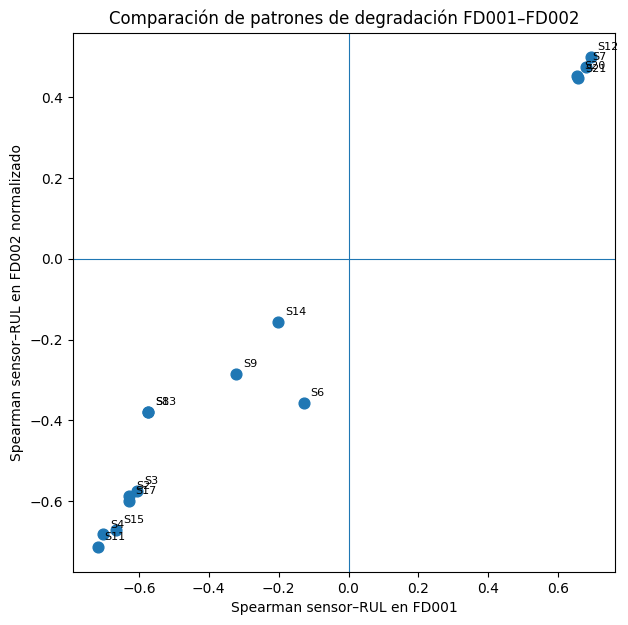

In [30]:
plt.figure(figsize=(7, 7))

plt.scatter(
    comparacion_correlaciones["Spearman FD001"],
    comparacion_correlaciones["Spearman FD002 normalizado"],
    s=60
)

for _, row in comparacion_correlaciones.iterrows():
    plt.annotate(
        row["Sensor"].replace("sensor_", "S"),
        (
            row["Spearman FD001"],
            row["Spearman FD002 normalizado"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Spearman sensor–RUL en FD001")
plt.ylabel("Spearman sensor–RUL en FD002 normalizado")
plt.title("Comparación de patrones de degradación FD001–FD002")

plt.show()

Los resultados muestran una elevada coherencia entre los patrones de degradación observados en FD001 y los obtenidos en FD002 después de controlar el efecto de las condiciones operativas.

Todos los sensores analizados mantienen el mismo signo de correlación entre ambos conjuntos. Esto indica que las variables que aumentan o disminuyen conforme se aproxima el final de vida en FD001 conservan ese mismo comportamiento general en FD002.

La similitud es especialmente elevada en `sensor_11`, `sensor_4`, `sensor_15`, `sensor_17`, `sensor_2` y `sensor_3`. En estos casos, las diferencias entre las correlaciones obtenidas en FD001 y FD002 normalizado son inferiores a 0,05.

Los sensores `sensor_12`, `sensor_7`, `sensor_20` y `sensor_21` mantienen también el mismo sentido de relación con la RUL, aunque la magnitud de la correlación es menor en FD002. Un comportamiento similar aparece en `sensor_8` y `sensor_13`.

Por su parte, `sensor_9` y `sensor_14` presentan relaciones más débiles con la RUL en ambos escenarios, aunque mantienen un comportamiento consistente.

La representación conjunta de las correlaciones muestra que los sensores se distribuyen siguiendo un patrón similar en ambos conjuntos, con los sensores de correlación positiva y negativa claramente situados en los mismos cuadrantes.

`Sensor_6` constituye el principal caso diferencial. Aunque presenta una relación débil con la RUL en FD001, su correlación aumenta en FD002 después de controlar las condiciones operativas. Este resultado sugiere que podría contener información adicional en el escenario de múltiples regímenes, aunque no resulta suficiente por sí solo para justificar su incorporación definitiva.

En conjunto, estos resultados respaldan la hipótesis de que las diferencias iniciales entre FD001 y FD002 se deben principalmente a las condiciones operativas y no a un cambio completo en los patrones de degradación representados por los sensores.

In [31]:
similitud_patrones = comparacion_correlaciones[
    ["Spearman FD001", "Spearman FD002 normalizado"]
].corr(method="pearson").iloc[0, 1]

print(
    "Correlación entre los patrones FD001 y FD002:",
    round(similitud_patrones, 4)
)

Correlación entre los patrones FD001 y FD002: 0.9835


Además, la correlación de Pearson entre los patrones de correlación sensor-RUL obtenidos en FD001 y FD002 normalizado alcanza un valor de 0,9835. Este resultado refuerza cuantitativamente la elevada similitud observada en la representación gráfica y muestra que, una vez reducido el efecto de las condiciones operativas, ambos subconjuntos presentan patrones de degradación muy similares.

### 6.4. Selección de sensores para FD002

A partir de los análisis realizados se decide mantener como conjunto principal de variables los mismos 14 sensores seleccionados previamente para FD001:

`sensor_2`, `sensor_3`, `sensor_4`, `sensor_7`, `sensor_8`, `sensor_9`, `sensor_11`, `sensor_12`, `sensor_13`, `sensor_14`, `sensor_15`, `sensor_17`, `sensor_20` y `sensor_21`.

Esta decisión se fundamenta en que estas variables mantienen variabilidad dentro de los regímenes operativos y conservan relaciones con la RUL consistentes con las observadas en FD001 una vez reducido el efecto de las condiciones de funcionamiento.

El uso del mismo conjunto de sensores proporciona además una base homogénea para comparar posteriormente el comportamiento de los modelos desarrollados sobre FD001 y FD002.

Aunque `sensor_6` presenta una relación con la RUL más clara en FD002 que en FD001, su incorporación no se considera necesaria en esta etapa. Se mantendrá como posible variable candidata y podrá evaluarse posteriormente de forma experimental si se considera necesario comprobar si aporta una mejora real en las métricas predictivas.

“Por otro lado, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` y `sensor_19` se mantienen fuera del conjunto predictivo. `sensor_1`, `sensor_5`, `sensor_18` y `sensor_19` permanecen constantes dentro de cada régimen y su variabilidad global está asociada a los cambios de condición operativa. `sensor_16` presenta una variabilidad interna muy limitada, mientras que `sensor_10` muestra relaciones débiles e inconsistentes con la RUL entre regímenes. Estos resultados no justifican su incorporación como variables predictoras de degradación.

Por tanto, el preprocesamiento de FD002 se basará en los 14 sensores seleccionados, aplicando una transformación condicionada por el régimen operativo antes de utilizarlos como entrada de los modelos.

## 7. Definición de la variable objetivo RUL en FD002

Una vez establecido el conjunto de variables y el tratamiento de las condiciones operativas, se analiza la definición de la variable objetivo utilizada para los modelos de prognosis.

Al igual que en FD001, la RUL lineal puede calcularse a partir del último ciclo disponible de cada motor. Sin embargo, durante las primeras etapas de funcionamiento los sensores pueden presentar un comportamiento relativamente estable, por lo que una representación lineal de la RUL puede asignar diferencias importantes entre observaciones que todavía no muestran señales claras de degradación.

En FD001 se utilizó una aproximación *piecewise* limitando la RUL máxima a 120 ciclos. Antes de trasladar este valor a FD002 se comprobará si el inicio observable de la degradación presenta un comportamiento comparable después de controlar el efecto de los distintos regímenes operativos.

### 7.1. Evolución de la desviación sensorial respecto al estado inicial

Para analizar cuándo comienzan a aparecer señales observables de degradación en FD002, se estudia la evolución conjunta de los sensores a medida que disminuye la RUL.

Debido a la presencia de múltiples condiciones operativas, este análisis se realiza sobre los sensores previamente normalizados por régimen. De esta forma, las diferencias provocadas por los cambios de condición de funcionamiento tienen una influencia reducida sobre la comparación.

Como referencia aproximada del comportamiento inicial de cada motor se utiliza el primer 10 % de su trayectoria, siguiendo el mismo criterio empleado anteriormente en el análisis de anomalías. A partir de estas observaciones se calcula, para cada sensor y motor, su valor medio inicial.

Posteriormente se mide la desviación absoluta de cada observación respecto a esta referencia. Finalmente, las desviaciones de los 14 sensores seleccionados se combinan en un índice medio de degradación.

El objetivo no es utilizar este índice como variable del modelo, sino estudiar de forma exploratoria en qué intervalo de RUL comienzan a separarse progresivamente las mediciones respecto al comportamiento inicial.

In [32]:
sensores_fd002 = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

sensores_fd002_norm = [
    f"{sensor}_norm"
    for sensor in sensores_fd002
]

train_fd002_degradacion = train_fd002_norm.copy()

In [33]:
n_ciclos_motor = (
    train_fd002_degradacion
    .groupby("unit")["cycle"]
    .transform("max")
)

limite_referencia = np.ceil(
    n_ciclos_motor * 0.10
)

mascara_referencia = (
    train_fd002_degradacion["cycle"]
    <= limite_referencia
)

print(
    "Observaciones de referencia:",
    mascara_referencia.sum()
)

print(
    "Porcentaje del conjunto:",
    round(mascara_referencia.mean() * 100, 2),
    "%"
)

Observaciones de referencia: 5491
Porcentaje del conjunto: 10.21 %


In [34]:
referencia_inicial = (
    train_fd002_degradacion[
        mascara_referencia
    ]
    .groupby("unit")[sensores_fd002_norm]
    .mean()
)

referencia_inicial.columns = [
    f"{col}_ref"
    for col in referencia_inicial.columns
]

train_fd002_degradacion = (
    train_fd002_degradacion
    .merge(
        referencia_inicial,
        on="unit",
        how="left"
    )
)

In [35]:
columnas_desviacion = []

for sensor_norm in sensores_fd002_norm:

    col_ref = f"{sensor_norm}_ref"
    col_dev = f"{sensor_norm}_dev"

    train_fd002_degradacion[col_dev] = (
        train_fd002_degradacion[sensor_norm]
        - train_fd002_degradacion[col_ref]
    ).abs()

    columnas_desviacion.append(col_dev)

train_fd002_degradacion[
    "indice_degradacion"
] = train_fd002_degradacion[
    columnas_desviacion
].mean(axis=1)

train_fd002_degradacion[
    ["unit", "cycle", "RUL", "indice_degradacion"]
].head()

,unit,cycle,RUL,indice_degradacion
0,1,1,148,0.590008
1,1,2,147,0.431823
2,1,3,146,0.671026
3,1,4,145,0.464857
4,1,5,144,0.539884


Los resultados muestran que el primer 10 % de las trayectorias representa aproximadamente el 10,21 % del conjunto total, por lo que el criterio de referencia inicial se aplica de forma coherente sobre los distintos motores.

A partir de estas observaciones iniciales se ha calculado, para cada motor, un comportamiento de referencia de los 14 sensores seleccionados. La desviación media respecto a dicha referencia permite resumir en un único índice cuánto se aleja cada observación del comportamiento inicial esperado.

Los primeros valores obtenidos muestran que incluso en las etapas iniciales existe cierta variabilidad alrededor del estado de referencia. Por este motivo, el valor absoluto del índice no debe interpretarse directamente como presencia de degradación, sino que resulta más informativo analizar cómo evoluciona de forma agregada conforme disminuye la RUL.

### 7.2. Evolución del índice de degradación según la RUL

Una vez calculada la desviación media respecto al comportamiento inicial de cada motor, se analiza su evolución en función de la RUL.

Para reducir la variabilidad ciclo a ciclo, se calcula primero el valor medio del índice para cada nivel de RUL y posteriormente se aplica un suavizado mediante una media móvil. De esta forma resulta más sencillo identificar posibles cambios progresivos en el comportamiento de los sensores.

In [36]:
indice_por_rul = (
    train_fd002_degradacion
    .groupby("RUL")["indice_degradacion"]
    .mean()
    .sort_index()
    .reset_index()
)

indice_por_rul["indice_suavizado"] = (
    indice_por_rul["indice_degradacion"]
    .rolling(
        window=15,
        center=True,
        min_periods=1
    )
    .mean()
)

display(indice_por_rul.head())

,RUL,indice_degradacion,indice_suavizado
0,0,2.399782,2.217665
1,1,2.342925,2.192104
2,2,2.280904,2.170779
3,3,2.241976,2.148541
4,4,2.174509,2.126934


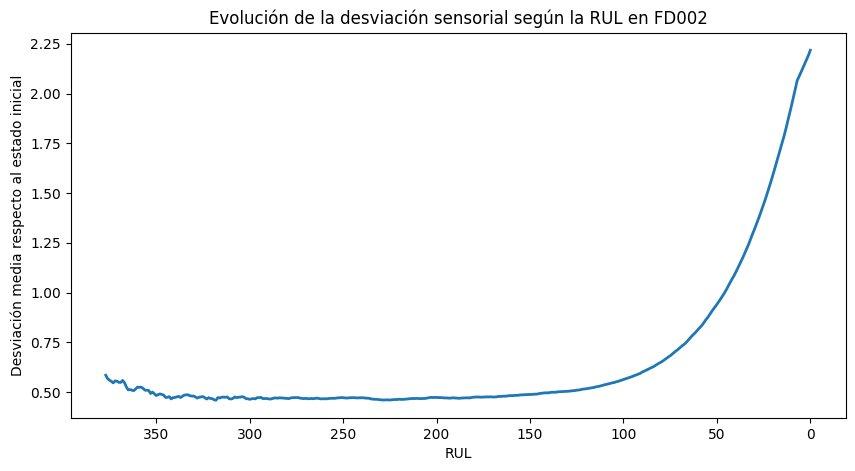

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    indice_por_rul["RUL"],
    indice_por_rul["indice_suavizado"],
    linewidth=2
)

plt.xlabel("RUL")
plt.ylabel("Desviación media respecto al estado inicial")
plt.title(
    "Evolución de la desviación sensorial según la RUL en FD002"
)

plt.gca().invert_xaxis()

plt.show()

La evolución del índice de degradación muestra un comportamiento claramente diferenciado a lo largo de la vida útil de los motores.

Para valores elevados de RUL, aproximadamente por encima de 130-150 ciclos, el índice suavizado se mantiene relativamente estable, con valores cercanos a 0,46-0,50. Esto indica que, durante esta etapa, las mediciones de los sensores permanecen próximas al comportamiento inicial de referencia y no muestran todavía una desviación progresiva marcada.

A medida que la RUL disminuye, la curva comienza a incrementarse gradualmente. Este cambio empieza a hacerse visible aproximadamente entre 120 y 100 ciclos de RUL, aunque todavía de forma moderada.

En las etapas más próximas al final de vida, especialmente por debajo de unos 60-50 ciclos, el crecimiento del índice se acelera de manera notable. La desviación respecto al estado inicial aumenta con rapidez y alcanza sus valores máximos cuando la RUL se aproxima a cero.

Este comportamiento es coherente con la existencia de una fase inicial relativamente estable seguida de una etapa de degradación progresiva. Además, la zona en la que comienza a apreciarse el incremento de la desviación se encuentra próxima al límite de 120 ciclos utilizado previamente en FD001.

No obstante, la inspección visual de la curva no permite establecer por sí sola un punto exacto de transición. Por este motivo, en el siguiente apartado se cuantificará de forma más objetiva cuándo comienza a separarse el índice respecto a su nivel estable.

### 7.3. Localización aproximada de la zona de transición

La inspección visual de la curva anterior sugiere que existe una región intermedia de RUL elevada en la que el índice de degradación permanece aproximadamente estable, seguida de un incremento progresivo al aproximarse al final de vida.

Los valores extremos de RUL alta se excluyen de la estimación del nivel de referencia, ya que únicamente las trayectorias de mayor duración alcanzan estos valores y, por tanto, el número de observaciones disponibles es menor. Además, se observa una ligera elevación del índice en esta zona que no corresponde al patrón progresivo de degradación de interés.

Por este motivo, el nivel base se estima utilizando la región comprendida entre 180 y 300 ciclos de RUL, donde la curva presenta un comportamiento estable. A continuación, se estudia desde RUL = 180 hacia el final de vida el momento en el que el índice suavizado supera distintos incrementos relativos respecto a dicho nivel.

Este análisis no pretende identificar un instante físico exacto de inicio de degradación, sino proporcionar una referencia cuantitativa para seleccionar un valor razonable de `RUL_MAX`.

In [38]:
# Se utiliza una zona intermedia de RUL alta como referencia estable, evitando los valores extremos donde existen menos observaciones
zona_estable = indice_por_rul[
    (indice_por_rul["RUL"] >= 180)
    & (indice_por_rul["RUL"] <= 300)
].copy()

nivel_base = zona_estable["indice_suavizado"].mean()

print("Nivel base de referencia:", round(nivel_base, 4))

Nivel base de referencia: 0.4687


In [39]:
factores_incremento = [1.05, 1.10, 1.20, 1.30, 1.50]

# La búsqueda de la transición se realiza desde RUL = 180 hacia el final de vida
zona_transicion = indice_por_rul[
    indice_por_rul["RUL"] <= 180
].copy()

resultados_transicion = []

for factor in factores_incremento:
    umbral = nivel_base * factor

    rul_supera = zona_transicion.loc[
        zona_transicion["indice_suavizado"] >= umbral,
        "RUL"
    ]

    rul_inicio = (
        rul_supera.max()
        if not rul_supera.empty
        else np.nan
    )

    resultados_transicion.append({
        "Incremento relativo": f"+{round((factor - 1) * 100)}%",
        "Umbral índice": round(umbral, 4),
        "RUL aproximada de inicio": rul_inicio
    })

transicion_df = pd.DataFrame(resultados_transicion)

display(transicion_df)

,Incremento relativo,Umbral índice,RUL aproximada de inicio
0,+5%,0.4922,145
1,+10%,0.5156,121
2,+20%,0.5625,100
3,+30%,0.6094,87
4,+50%,0.7031,72


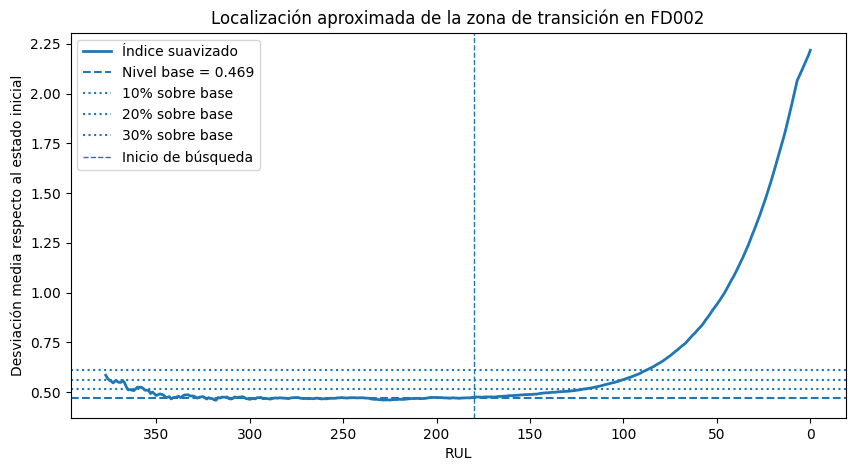

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    indice_por_rul["RUL"],
    indice_por_rul["indice_suavizado"],
    label="Índice suavizado",
    linewidth=2
)

plt.axhline(
    nivel_base,
    linestyle="--",
    label=f"Nivel base = {nivel_base:.3f}"
)

for factor in [1.10, 1.20, 1.30]:
    umbral = nivel_base * factor

    plt.axhline(
        umbral,
        linestyle=":",
        label=f"{round((factor - 1) * 100)}% sobre base"
    )

plt.axvline(
    180,
    linestyle="--",
    linewidth=1,
    label="Inicio de búsqueda"
)

plt.xlabel("RUL")
plt.ylabel("Desviación media respecto al estado inicial")
plt.title("Localización aproximada de la zona de transición en FD002")

plt.gca().invert_xaxis()
plt.legend()

plt.show()

Los resultados muestran una transición progresiva entre la región estable y la etapa de degradación, en lugar de un cambio abrupto en un único valor de RUL.

Tomando como referencia el nivel medio de la zona estable, aproximadamente 0,469, el índice suavizado supera en un 5 % dicho nivel alrededor de los 145 ciclos de RUL. Este primer incremento es todavía reducido y puede interpretarse como una desviación inicial respecto al comportamiento estable.

El incremento alcanza aproximadamente un 10 % en torno a 121 ciclos de RUL. A partir de este punto, el crecimiento de la desviación se vuelve progresivamente más evidente: se alcanza un incremento del 20 % alrededor de 100 ciclos, del 30 % en torno a 87 ciclos y del 50 % aproximadamente a los 72 ciclos de RUL.

Por tanto, los resultados no identifican un instante exacto de inicio de degradación, sino una región de transición que comienza de forma suave y se intensifica al aproximarse al final de vida.

Resulta especialmente relevante que el incremento del 10 % respecto al nivel estable aparezca aproximadamente en RUL = 121, un valor prácticamente coincidente con el límite `RUL_MAX = 120` utilizado previamente en FD001. Este resultado proporciona evidencia adicional para considerar dicho valor como candidato también en FD002.

### 7.4. Evaluación de candidatos para el límite `RUL_MAX`

Una vez analizada la evolución del índice de degradación, se comparan distintos valores candidatos para el límite superior de la RUL por tramos.

El objetivo es estudiar qué proporción de observaciones quedaría agrupada en la región inicial para cada valor y valorar las implicaciones de cada límite sobre la distribución de la variable objetivo y comprobar si el valor de 120 ciclos resulta coherente con el comportamiento observado en los sensores.

Este análisis permite complementar la interpretación visual de la curva anterior con una visión más descriptiva del efecto que tendría cada valor candidato.

In [41]:
candidatos_rul_max = [90, 100, 120, 140, 150]

resumen_caps = []

for cap in candidatos_rul_max:
    n_region_constante = (train_fd002_norm["RUL"] >= cap).sum()
    n_region_lineal = (train_fd002_norm["RUL"] < cap).sum()
    pct_region_constante = (
        n_region_constante / len(train_fd002_norm) * 100
    )

    resumen_caps.append({
        "RUL_MAX candidata": cap,
        "Observaciones en región constante": n_region_constante,
        "Observaciones en región lineal": n_region_lineal,
        "% observaciones en región constante": round(
            pct_region_constante,
            2
        )
    })

resumen_caps_df = pd.DataFrame(resumen_caps)
resumen_caps_df

,RUL_MAX candidata,Observaciones en región constante,Observaciones en región lineal,% observaciones en región constante
0,90,30359,23400,56.47
1,100,27759,26000,51.64
2,120,22559,31200,41.96
3,140,17398,36361,32.36
4,150,14903,38856,27.72


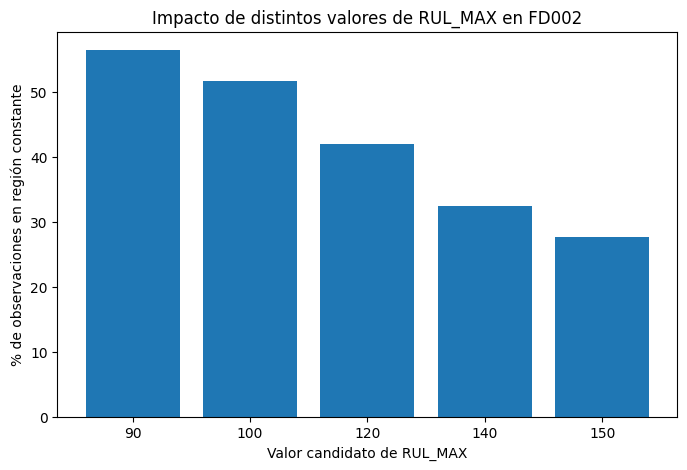

In [42]:
plt.figure(figsize=(8, 5))

plt.bar(
    resumen_caps_df["RUL_MAX candidata"].astype(str),
    resumen_caps_df["% observaciones en región constante"]
)

plt.xlabel("Valor candidato de RUL_MAX")
plt.ylabel("% de observaciones en región constante")
plt.title("Impacto de distintos valores de RUL_MAX en FD002")

plt.show()

Los resultados muestran que la elección de `RUL_MAX` modifica de forma considerable la proporción de observaciones que quedan agrupadas en la región inicial de RUL constante.

Con `RUL_MAX = 90`, el 56,47 % de las observaciones quedarían situadas en la región constante, mientras que con `RUL_MAX = 100` esta proporción sería del 51,64 %. Estos valores desplazarían el inicio de la región predictiva hacia etapas relativamente avanzadas de la degradación.

Por el contrario, valores superiores como 140 y 150 ciclos reducirían la proporción de observaciones situadas en la región constante al 32,36 % y 27,72 %, respectivamente. Esto implicaría comenzar a distinguir valores de RUL en una zona donde el análisis anterior todavía muestra desviaciones relativamente pequeñas respecto al comportamiento estable.

El valor `RUL_MAX = 120` mantiene aproximadamente el 41,96 % de las observaciones en la región constante y deja el 58,04 % restante con su valor lineal de RUL. Este valor representa, por tanto, una solución intermedia entre los candidatos analizados.

Además, su posición resulta coherente con el análisis de la transición sensorial, donde el índice de degradación supera aproximadamente en un 10 % su nivel estable alrededor de RUL = 121. Por ello, el límite de 120 ciclos presenta una justificación tanto desde el comportamiento de los sensores como desde la distribución de la variable objetivo.

### 7.5. Selección del límite `RUL_MAX`

A partir de los análisis realizados se establece `RUL_MAX = 120` para la definición de la RUL por tramos en FD002.

La evolución de la desviación sensorial muestra que el comportamiento de los motores permanece relativamente estable durante la región de RUL elevada y comienza a separarse progresivamente del estado inicial al aproximarse al final de vida. El índice de degradación supera aproximadamente en un 10 % su nivel de referencia alrededor de RUL = 121, mientras que incrementos del 20 %, 30 % y 50 % aparecen aproximadamente en RUL = 100, 87 y 72, respectivamente.

Estos resultados sitúan los 120 ciclos en una zona razonable de transición entre el comportamiento inicial relativamente estable y la aparición progresiva de señales de degradación.

Desde el punto de vista de la distribución de la variable objetivo, este límite mantiene el 41,96 % de las observaciones en la región constante, evitando tanto diferenciar excesivamente estados iniciales con escasa evidencia de degradación como retrasar el modelado hasta etapas demasiado próximas al final de vida.

El valor seleccionado coincide con el utilizado previamente en FD001, lo que facilita la comparación posterior entre ambos escenarios. No obstante, esta coincidencia no se adopta de forma automática, sino que queda respaldada de manera independiente por el análisis realizado sobre FD002.

Por tanto, la variable objetivo se define como:

$$
RUL_{piecewise} = \min(RUL, 120)
$$

In [43]:
RUL_MAX = 120

train_fd002_norm["RUL_piecewise"] = np.minimum(
    train_fd002_norm["RUL"],
    RUL_MAX
)

train_fd002_norm[
    ["unit", "cycle", "RUL", "RUL_piecewise"]
].head()

,unit,cycle,RUL,RUL_piecewise
0,1,1,148,120
1,1,2,147,120
2,1,3,146,120
3,1,4,145,120
4,1,5,144,120


## 8. Preparación de los datos para el modelado

Una vez definidas las variables predictoras, el tratamiento de las condiciones operativas y la variable objetivo, se prepara el conjunto de datos que se utilizará posteriormente para desarrollar los modelos de detección de anomalías y prognosis.

Hasta este punto, la normalización por régimen se ha calculado utilizando el conjunto completo de entrenamiento únicamente con finalidad exploratoria. Estas variables normalizadas no se utilizarán directamente para el entrenamiento o validación de los modelos.

Para el modelado, la división entre desarrollo y validación se realizará antes de estimar cualquier parámetro de transformación. Las medias y desviaciones estándar asociadas a cada régimen se calcularán exclusivamente utilizando los motores del subconjunto de desarrollo y posteriormente se aplicarán, sin reajuste, sobre los motores de validación.

Este procedimiento evita que información estadística procedente de los motores de validación intervenga en el ajuste del preprocesamiento utilizado durante el modelado.

### 8.1. División de los motores en desarrollo y validación

La división se realiza utilizando identificadores completos de motor y no observaciones individuales. Este criterio evita que diferentes ciclos de una misma trayectoria aparezcan simultáneamente en desarrollo y validación, lo que produciría una fuga de información entre ambos conjuntos.

Se utiliza una proporción 80/20 y una semilla fija para garantizar la reproducibilidad del experimento.

In [44]:
motores_fd002 = np.sort(
    train_fd002_reg["unit"].unique()
)

motores_dev, motores_val = train_test_split(
    motores_fd002,
    test_size=0.20,
    random_state=42
)

print("Motores totales:", len(motores_fd002))
print("Motores desarrollo:", len(motores_dev))
print("Motores validación:", len(motores_val))

print(
    "Solapamiento:",
    len(set(motores_dev) & set(motores_val))
)

Motores totales: 260
Motores desarrollo: 208
Motores validación: 52
Solapamiento: 0


In [45]:
fd002_dev = train_fd002_reg[
    train_fd002_reg["unit"].isin(motores_dev)
].copy()

fd002_val = train_fd002_reg[
    train_fd002_reg["unit"].isin(motores_val)
].copy()

RUL_MAX = 120

fd002_dev["RUL_piecewise"] = np.minimum(
    fd002_dev["RUL"],
    RUL_MAX
)

fd002_val["RUL_piecewise"] = np.minimum(
    fd002_val["RUL"],
    RUL_MAX
)

print("Desarrollo:")
print("Observaciones:", len(fd002_dev))
print("Motores:", fd002_dev["unit"].nunique())

print("\nValidación:")
print("Observaciones:", len(fd002_val))
print("Motores:", fd002_val["unit"].nunique())

Desarrollo:
Observaciones: 43464
Motores: 208

Validación:
Observaciones: 10295
Motores: 52


La división genera 208 motores para el subconjunto de desarrollo y 52 motores para validación, correspondientes exactamente al 80 % y 20 % de los 260 motores disponibles.

No existe ningún solapamiento entre los identificadores de ambos subconjuntos, por lo que todas las observaciones pertenecientes a una misma trayectoria permanecen agrupadas en una única partición.

El subconjunto de desarrollo contiene 43.464 observaciones y el de validación 10.295. La proporción de observaciones no coincide exactamente con el 80/20 debido a que las trayectorias de los motores presentan diferentes longitudes. Esta diferencia es esperable, ya que la partición se ha realizado correctamente a nivel de motor y no a nivel de observación.

A partir de este punto, cualquier parámetro de preprocesamiento utilizado durante el desarrollo de los modelos deberá estimarse exclusivamente a partir del subconjunto de desarrollo.

### 8.2. Distribución de los regímenes operativos

Antes de ajustar la normalización de los sensores, se comprueba que los seis regímenes operativos se encuentran representados tanto en el subconjunto de desarrollo como en el de validación.

Una distribución similar entre ambas particiones permitirá evaluar posteriormente los modelos sobre condiciones de funcionamiento comparables a las utilizadas durante su desarrollo.

In [46]:
distribucion_regimenes = pd.DataFrame({
    "Desarrollo": (
        fd002_dev["operating_regime"]
        .value_counts()
        .sort_index()
    ),
    "Validación": (
        fd002_val["operating_regime"]
        .value_counts()
        .sort_index()
    )
})

distribucion_regimenes["% Desarrollo"] = (
    distribucion_regimenes["Desarrollo"]
    / len(fd002_dev)
    * 100
)

distribucion_regimenes["% Validación"] = (
    distribucion_regimenes["Validación"]
    / len(fd002_val)
    * 100
)

display(
    distribucion_regimenes.round({
        "% Desarrollo": 2,
        "% Validación": 2
    })
)

,Desarrollo,Validación,% Desarrollo,% Validación
operating_regime,,,,
1,6507,1537,14.97,14.93
2,6572,1524,15.12,14.80
3,6535,1587,15.04,15.42
4,6450,1552,14.84,15.08
5,6543,1494,15.05,14.51
6,10857,2601,24.98,25.26


In [47]:
motores_por_regimen = pd.DataFrame({
    "Motores desarrollo": (
        fd002_dev
        .groupby("operating_regime")["unit"]
        .nunique()
    ),
    "Motores validación": (
        fd002_val
        .groupby("operating_regime")["unit"]
        .nunique()
    )
})

display(motores_por_regimen)

,Motores desarrollo,Motores validación
operating_regime,,
1,208,52
2,208,52
3,208,52
4,208,52
5,208,52
6,208,52


Los seis regímenes operativos se encuentran representados en ambos subconjuntos con distribuciones muy similares.

Los regímenes 1 a 5 representan aproximadamente un 15 % de las observaciones tanto en desarrollo como en validación, mientras que el régimen 6 presenta una frecuencia superior, cercana al 25 % en ambos casos.

Además, todos los motores de cada partición contienen observaciones correspondientes a los seis regímenes: los 208 motores de desarrollo y los 52 motores de validación aparecen en cada una de las condiciones operativas.

Por tanto, la división mantiene adecuadamente la estructura operacional de FD002 y permite continuar con el ajuste de la normalización utilizando exclusivamente el subconjunto de desarrollo.

### 8.3. Ajuste de la normalización por régimen

Una vez realizada la separación entre desarrollo y validación, se ajusta de nuevo la transformación utilizada para reducir el efecto de las condiciones operativas.

Las medias y desviaciones estándar de cada sensor se calculan exclusivamente a partir de los 208 motores del subconjunto de desarrollo. Estas estadísticas se utilizan posteriormente para transformar tanto las observaciones de desarrollo como las de validación.

De esta forma, los motores utilizados para validación no intervienen en la estimación de ningún parámetro de preprocesamiento, evitando así la fuga de información.

Se mantienen como variables predictoras los 14 sensores seleccionados anteriormente. Las variables operativas se utilizan para identificar el régimen y aplicar la transformación correspondiente, pero no se incorporan directamente como entradas de los modelos en esta fase.

In [48]:
sensores_modelo = [
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_17",
    "sensor_20",
    "sensor_21"
]

In [49]:
estadisticas_regimen_dev = (
    fd002_dev
    .groupby("operating_regime")[sensores_modelo]
    .agg(["mean", "std"])
)

display(estadisticas_regimen_dev)

sensor_2               sensor_3               sensor_4  \
                        mean       std         mean       std         mean   
operating_regime                                                             
1                 642.683223  0.496885  1590.485643  6.002485  1408.925302   
2                 604.920569  0.473058  1502.049285  5.787360  1311.332585   
3                 607.568317  0.461034  1485.594323  5.765890  1253.194144   
4                 536.865617  0.357006  1262.734571  5.296928  1050.367819   
5                 555.801453  0.438378  1366.757630  5.581425  1131.596308   
6                 549.707857  0.430923  1354.505945  5.598566  1127.882649   

                              sensor_7               sensor_8            ...  \
                       std        mean       std         mean       std  ...   
operating_regime                                                         ...   
1                 8.910578  553.347503  0.868359  2388.101675  0.070619  ...   
2                 8.455925  394.313620  0.668231  2318.959595  0.094026  ...   
3                 7.808457  334.492660  0.602229  2324.019299  0.120456  ...   
4                 6.796328  175.424293  0.447935  1915.409132  0.249720  ...   
5                 7.364069  194.437443  0.477298  2223.033902  0.261932  ...   
6                 7.642977  138.626759  0.440879  2211.963441  0.283564  ...   

                    sensor_14             sensor_15             sensor_17  \
                         mean        std       mean       std        mean   
operating_regime                                                            
1                 8141.227264  15.540537   8.442605  0.036939  393.214999   
2                 8134.785029  15.278925   8.664983  0.038083  369.716220   
3                 8065.466395  14.164059   9.232778  0.038958  365.384239   
4                 7878.149676  12.476066  10.914220  0.043186  307.349457   
5                 8071.806239  14.498543   9.332896  0.038218  334.244842   
6                 8089.023073  15.534684   9.375560  0.037540  331.071383   

                            sensor_20            sensor_21            
                       std       mean       std       mean       std  
operating_regime                                                      
1                 1.518824  38.815849  0.177152  23.288884  0.105387  
2                 1.485472  28.524207  0.142745  17.114007  0.085662  
3                 1.470357  24.452946  0.134718  14.671651  0.079872  
4                 1.293154  14.262561  0.111247   8.558524  0.066361  
5                 1.403895  14.830000  0.113278   8.897447  0.066914  
6                 1.402692  10.585396  0.108038   6.350693  0.064243  

[6 rows x 28 columns]

In [50]:
std_regimen_dev = estadisticas_regimen_dev.xs(
    "std",
    axis=1,
    level=1
)

std_cero = std_regimen_dev <= 0

print(
    "Combinaciones sensor-régimen con desviación estándar nula:",
    std_cero.sum().sum()
)

Combinaciones sensor-régimen con desviación estándar nula: 0


In [51]:
def normalizar_por_regimen(df, estadisticas, sensores):
    df_norm = df.copy()

    for sensor in sensores:
        medias = df_norm["operating_regime"].map(
            estadisticas[(sensor, "mean")]
        )

        stds = df_norm["operating_regime"].map(
            estadisticas[(sensor, "std")]
        )

        if medias.isna().any() or stds.isna().any():
            raise ValueError(
                f"No existen estadísticas para todos los regímenes de {sensor}"
            )

        if (stds <= 0).any():
            raise ValueError(
                f"Se ha encontrado una desviación estándar no válida en {sensor}"
            )

        df_norm[f"{sensor}_norm"] = (
            df_norm[sensor] - medias
        ) / stds

    return df_norm

In [52]:
fd002_dev_norm = normalizar_por_regimen(
    fd002_dev,
    estadisticas_regimen_dev,
    sensores_modelo
)

fd002_val_norm = normalizar_por_regimen(
    fd002_val,
    estadisticas_regimen_dev,
    sensores_modelo
)

features_modelo = [
    f"{sensor}_norm"
    for sensor in sensores_modelo
]

print("Variables de entrada:", len(features_modelo))
print(features_modelo)

Variables de entrada: 14
['sensor_2_norm', 'sensor_3_norm', 'sensor_4_norm', 'sensor_7_norm', 'sensor_8_norm', 'sensor_9_norm', 'sensor_11_norm', 'sensor_12_norm', 'sensor_13_norm', 'sensor_14_norm', 'sensor_15_norm', 'sensor_17_norm', 'sensor_20_norm', 'sensor_21_norm']


Las estadísticas calculadas sobre el subconjunto de desarrollo confirman que los 14 sensores seleccionados presentan variabilidad dentro de los seis regímenes operativos.

No se ha detectado ninguna combinación sensor-régimen con desviación estándar nula, por lo que la normalización puede aplicarse a todas las variables seleccionadas sin necesidad de introducir tratamientos adicionales.

A partir de estas estadísticas se generan 14 variables normalizadas, una por cada sensor utilizado como entrada de los modelos. Las medias y desviaciones utilizadas en la transformación proceden exclusivamente de los 208 motores de desarrollo.

Estas mismas estadísticas se aplican posteriormente, sin reajuste, sobre los 52 motores de validación. De esta forma, la transformación utilizada durante la evaluación reproduce el comportamiento que tendría el sistema ante motores no utilizados para estimar los parámetros de preprocesamiento.

### 8.4. Verificación de la transformación

Finalmente, se comprueba el comportamiento de los sensores después de aplicar la transformación.

En el subconjunto de desarrollo se esperan medias prácticamente iguales a cero y desviaciones estándar iguales a uno dentro de cada régimen, ya que sus propias estadísticas se han utilizado para ajustar la transformación.

En validación no se espera obtener exactamente estos valores, puesto que sus observaciones no han intervenido en el ajuste. Sin embargo, valores próximos a cero y uno indicarían que la distribución de los motores de validación es compatible con la observada durante el desarrollo.

In [53]:
verificacion_normalizacion = []

for regimen in sorted(
    fd002_dev_norm["operating_regime"].unique()
):
    dev_reg = fd002_dev_norm[
        fd002_dev_norm["operating_regime"] == regimen
    ]

    val_reg = fd002_val_norm[
        fd002_val_norm["operating_regime"] == regimen
    ]

    verificacion_normalizacion.append({
        "Régimen": regimen,

        "Máx |media| desarrollo":
            dev_reg[features_modelo]
            .mean()
            .abs()
            .max(),

        "Std media desarrollo":
            dev_reg[features_modelo]
            .std()
            .mean(),

        "Máx |media| validación":
            val_reg[features_modelo]
            .mean()
            .abs()
            .max(),

        "Std media validación":
            val_reg[features_modelo]
            .std()
            .mean()
    })

verificacion_normalizacion = pd.DataFrame(
    verificacion_normalizacion
)

display(
    verificacion_normalizacion.round(4)
)

,Régimen,Máx |media| desarrollo,Std media desarrollo,Máx |media| validación,Std media validación
0,1,0.0,1.0,0.1466,1.0456
1,2,0.0,1.0,0.1191,1.0424
2,3,0.0,1.0,0.1604,1.0804
3,4,0.0,1.0,0.1371,1.0643
4,5,0.0,1.0,0.1458,1.0909
5,6,0.0,1.0,0.1479,1.0791


Los resultados confirman que la transformación se ha aplicado correctamente.

En el subconjunto de desarrollo, las medias de las variables normalizadas son prácticamente iguales a cero y las desviaciones estándar iguales a uno dentro de los seis regímenes. Este comportamiento es el esperado, ya que las estadísticas utilizadas para la transformación se han estimado a partir de estas mismas observaciones.

En validación, las medias no son exactamente iguales a cero y las desviaciones estándar tampoco son exactamente uno, puesto que estos motores no han intervenido en el ajuste de la normalización. No obstante, las diferencias son reducidas.

El máximo valor absoluto de las medias se encuentra entre 0,119 y 0,160 según el régimen, mientras que las desviaciones estándar medias se sitúan aproximadamente entre 1,04 y 1,09.

Estos resultados indican que las distribuciones de los motores de validación son compatibles con las observadas durante el desarrollo y que las estadísticas calculadas exclusivamente sobre el subconjunto de desarrollo permiten transformar adecuadamente datos no utilizados durante su estimación.

Por tanto, se considera validado el procedimiento de normalización por régimen para su utilización en los modelos posteriores.

## 9. Detección de anomalías en FD002

Una vez definido y validado el preprocesamiento de FD002, se desarrolla el componente de detección de anomalías.

En FD001 se compararon diferentes técnicas de detección no supervisada y se seleccionó Isolation Forest como detector principal. En esta extensión no se repite nuevamente todo el proceso de selección de algoritmos, sino que se estudia si el método seleccionado puede adaptarse al escenario más complejo de FD002.

La principal diferencia respecto a FD001 es la existencia de seis condiciones operativas. Para evitar que los cambios entre regímenes sean interpretados como anomalías, el modelo utilizará los 14 sensores previamente normalizados mediante las estadísticas específicas de cada régimen.

Al igual que en FD001, las observaciones iniciales de cada trayectoria se utilizarán como aproximación al comportamiento de referencia del motor. El detector se ajustará exclusivamente utilizando observaciones procedentes de los motores del subconjunto de desarrollo.

### 9.1. Construcción del conjunto de referencia

Para entrenar el detector se utiliza como aproximación al comportamiento nominal el primer 10 % de la trayectoria de cada motor del subconjunto de desarrollo.

Este criterio reproduce la estrategia utilizada en FD001 y parte de la hipótesis de que las primeras etapas de funcionamiento representan, de forma aproximada, el comportamiento inicial antes de que la degradación sea claramente observable.

La selección se realiza únicamente sobre los motores de desarrollo. Las observaciones de validación no intervienen en el ajuste del detector.

In [54]:
max_cycle_dev = (
    fd002_dev_norm
    .groupby("unit")["cycle"]
    .transform("max")
)

limite_referencia_dev = np.ceil(
    max_cycle_dev * 0.10
)

mascara_ref_dev = (
    fd002_dev_norm["cycle"]
    <= limite_referencia_dev
)

referencia_dev = fd002_dev_norm[
    mascara_ref_dev
].copy()

print("Observaciones de referencia:", len(referencia_dev))
print(
    "Porcentaje de desarrollo:",
    round(len(referencia_dev) / len(fd002_dev_norm) * 100, 2),
    "%"
)
print(
    "Motores representados:",
    referencia_dev["unit"].nunique()
)

Observaciones de referencia: 4437
Porcentaje de desarrollo: 10.21 %
Motores representados: 208


In [55]:
distribucion_ref_regimen = (
    referencia_dev["operating_regime"]
    .value_counts()
    .sort_index()
    .to_frame("Observaciones")
)

distribucion_ref_regimen["%"] = (
    distribucion_ref_regimen["Observaciones"]
    / len(referencia_dev)
    * 100
)

display(distribucion_ref_regimen.round(2))

,Observaciones,%
operating_regime,,
1,692,15.60
2,679,15.30
3,680,15.33
4,648,14.60
5,653,14.72
6,1085,24.45


El conjunto de referencia contiene 4.437 observaciones, correspondientes aproximadamente al 10,21 % del subconjunto de desarrollo, y están representados los 208 motores utilizados en esta partición.

Además, los seis regímenes operativos aparecen en la referencia con una distribución muy similar a la observada en el conjunto completo de desarrollo. Los regímenes 1 a 5 representan aproximadamente entre el 14,6 % y el 15,6 % de las observaciones, mientras que el régimen 6 concentra alrededor del 24,45 %.

Esta distribución resulta especialmente relevante en FD002, ya que permite que el detector conozca desde su entrenamiento el comportamiento inicial de los motores bajo todas las condiciones operativas. De esta forma, una condición de funcionamiento concreta no debería ser considerada anómala únicamente por presentar niveles de sensores diferentes.

Por tanto, el conjunto de referencia se considera suficientemente representativo para ajustar el detector de anomalías.

### 9.2. Entrenamiento del modelo Isolation Forest

Se utiliza Isolation Forest como detector de anomalías principal, manteniendo la configuración seleccionada previamente en FD001 para facilitar la comparación entre ambos escenarios.

El modelo se entrena exclusivamente utilizando las observaciones iniciales de los 208 motores de desarrollo. Las variables de entrada corresponden a los 14 sensores normalizados según el régimen operativo.

El detector genera para cada observación una puntuación de anomalía a partir de `score_samples`. Para facilitar su interpretación, se invierte el signo de esta puntuación, de forma que valores más elevados representan comportamientos más anómalos.

In [56]:
isolation_forest_fd002 = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

X_reference_fd002 = referencia_dev[
    features_modelo
]

isolation_forest_fd002.fit(
    X_reference_fd002
)

print(
    "Observaciones utilizadas para entrenar:",
    len(X_reference_fd002)
)

print(
    "Variables utilizadas:",
    X_reference_fd002.shape[1]
)

Observaciones utilizadas para entrenar: 4437
Variables utilizadas: 14


### 9.3. Cálculo de las puntuaciones de anomalía

Una vez ajustado el detector, se calcula una puntuación de anomalía para las observaciones de referencia, desarrollo y validación.

La puntuación se define como el valor negativo de `score_samples`, de forma que una puntuación mayor indique una mayor separación respecto al comportamiento aprendido como referencia.

Las puntuaciones de validación se obtienen utilizando directamente el modelo entrenado sobre desarrollo, sin realizar ningún reajuste.

In [57]:
score_reference = -isolation_forest_fd002.score_samples(
    referencia_dev[features_modelo]
)

score_dev = -isolation_forest_fd002.score_samples(
    fd002_dev_norm[features_modelo]
)

score_val = -isolation_forest_fd002.score_samples(
    fd002_val_norm[features_modelo]
)

referencia_dev = referencia_dev.copy()
referencia_dev["anomaly_score_if"] = score_reference

fd002_dev_norm = fd002_dev_norm.copy()
fd002_dev_norm["anomaly_score_if"] = score_dev

fd002_val_norm = fd002_val_norm.copy()
fd002_val_norm["anomaly_score_if"] = score_val

In [58]:
resumen_scores = pd.DataFrame({
    "Referencia": referencia_dev["anomaly_score_if"].describe(),
    "Desarrollo": fd002_dev_norm["anomaly_score_if"].describe(),
    "Validación": fd002_val_norm["anomaly_score_if"].describe()
})

display(resumen_scores)

,Referencia,Desarrollo,Validación
count,4437.000000,43464.000000,10295.000000
mean,0.444990,0.499247,0.498352
std,0.033524,0.084585,0.083311
min,0.369457,0.369457,0.377433
25%,0.419463,0.434521,0.434396
50%,0.440466,0.471153,0.471343
75%,0.466101,0.548585,0.545789
max,0.568226,0.738117,0.732644


In [59]:
THRESHOLD_PERCENTILE = 97.5

threshold_if_fd002 = np.percentile(
    score_reference,
    THRESHOLD_PERCENTILE
)

print(
    f"Umbral P{THRESHOLD_PERCENTILE}:",
    threshold_if_fd002
)

print(
    "Referencia por encima del umbral:",
    round(
        (score_reference > threshold_if_fd002).mean() * 100,
        2
    ),
    "%"
)

Umbral P97.5: 0.5219367712684035
Referencia por encima del umbral: 2.5 %


Los resultados muestran una separación clara entre las observaciones utilizadas como referencia inicial y el conjunto completo de las trayectorias.

En la región de referencia, la puntuación media de anomalía es aproximadamente 0,445, mientras que al considerar todas las observaciones de desarrollo aumenta hasta 0,499. La distribución también se amplía considerablemente: la desviación estándar pasa de aproximadamente 0,034 en la referencia a 0,085 en el conjunto completo de desarrollo.

Este comportamiento es coherente con la aparición progresiva de estados más alejados del comportamiento inicial conforme avanza la vida de los motores.

El subconjunto de validación presenta una distribución prácticamente equivalente a la observada en desarrollo. Su puntuación media es 0,498, frente a 0,499 en desarrollo, y las desviaciones estándar son también muy similares, con valores de 0,083 y 0,085 respectivamente. Los cuartiles y valores máximos muestran igualmente comportamientos próximos.

Esta similitud indica que el detector entrenado exclusivamente sobre los motores de desarrollo mantiene un comportamiento estable cuando se aplica sobre motores no utilizados durante su ajuste.

A partir de la distribución de puntuaciones correspondiente exclusivamente a la región de referencia de desarrollo se establece como umbral de anomalía el percentil 97,5, obteniéndose un valor de aproximadamente 0,52194.

Por construcción, únicamente el 2,5 % de las observaciones utilizadas como referencia superan este límite. No obstante, una superación aislada del umbral no se considerará suficiente para generar una alerta, ya que puede estar provocada por variaciones puntuales de los sensores. Por este motivo, se incorporará a continuación un criterio de persistencia temporal.

### 9.4. Confirmación temporal de las anomalías

Una observación cuya puntuación supera el umbral se considera inicialmente anómala. Sin embargo, para reducir la sensibilidad frente a desviaciones puntuales se requiere que esta condición se mantenga durante tres ciclos consecutivos del mismo motor.

De esta forma, una alerta se confirma únicamente cuando las tres observaciones más recientes superan el umbral establecido.

Además, se genera una segunda variable que indica si el motor ha presentado alguna alerta confirmada hasta el ciclo considerado. Esta información permitirá distinguir entre el estado actual de la alerta y la existencia de anomalías detectadas previamente a lo largo de la trayectoria.

In [60]:
def aplicar_alertas_persistentes(df, threshold, n_consecutivos=3):
    df_alertas = df.sort_values(
        ["unit", "cycle"]
    ).copy()

    df_alertas["anomalia_umbral"] = (
        df_alertas["anomaly_score_if"] > threshold
    )

    df_alertas["alerta_confirmada"] = (
        df_alertas
        .groupby("unit")["anomalia_umbral"]
        .transform(
            lambda x: (
                x.rolling(
                    window=n_consecutivos,
                    min_periods=n_consecutivos
                )
                .sum()
                .eq(n_consecutivos)
            )
        )
    )

    df_alertas["ha_tenido_alerta"] = (
        df_alertas
        .groupby("unit")["alerta_confirmada"]
        .cummax()
    )

    return df_alertas

In [61]:
fd002_dev_alertas = aplicar_alertas_persistentes(
    fd002_dev_norm,
    threshold_if_fd002,
    n_consecutivos=3
)

fd002_val_alertas = aplicar_alertas_persistentes(
    fd002_val_norm,
    threshold_if_fd002,
    n_consecutivos=3
)

### 9.5. Análisis de las alertas en el subconjunto de validación

Una vez incorporado el criterio de persistencia temporal, se analiza el comportamiento de las alertas sobre los 52 motores de validación.

Dado que C-MAPSS no proporciona una etiqueta explícita de anomalía para cada ciclo, esta etapa no permite calcular métricas supervisadas convencionales como precisión o recall. En su lugar, se estudia en qué momento de la trayectoria comienzan a aparecer las alertas y su relación con la RUL.

In [62]:
primeras_alertas_val = (
    fd002_val_alertas[
        fd002_val_alertas["alerta_confirmada"]
    ]
    .groupby("unit")
    .first()[
        ["cycle", "RUL", "RUL_piecewise", "anomaly_score_if"]
    ]
    .reset_index()
)

print(
    "Motores de validación:",
    fd002_val_alertas["unit"].nunique()
)

print(
    "Motores con al menos una alerta:",
    primeras_alertas_val["unit"].nunique()
)

print(
    "Porcentaje de motores alertados:",
    round(
        primeras_alertas_val["unit"].nunique()
        / fd002_val_alertas["unit"].nunique()
        * 100,
        2
    ),
    "%"
)

display(
    primeras_alertas_val[
        ["RUL", "cycle", "anomaly_score_if"]
    ].describe()
)

Motores de validación: 52
Motores con al menos una alerta: 52
Porcentaje de motores alertados: 100.0 %


,RUL,cycle,anomaly_score_if
count,52.000000,52.000000,52.000000
mean,56.269231,141.711538,0.553975
std,28.141181,32.031441,0.027081
min,18.000000,71.000000,0.522330
25%,37.000000,119.500000,0.534929
50%,45.500000,135.000000,0.547567
75%,68.000000,163.500000,0.563313
max,162.000000,229.000000,0.649267


In [63]:
ultimo_ciclo_val = (
    fd002_val_alertas
    .sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
)

print(
    "Motores con alerta activa en el último ciclo:",
    ultimo_ciclo_val["alerta_confirmada"].sum()
)

print(
    "Motores que han tenido alguna alerta:",
    ultimo_ciclo_val["ha_tenido_alerta"].sum()
)

Motores con alerta activa en el último ciclo: 52
Motores que han tenido alguna alerta: 52


In [64]:
if len(primeras_alertas_val) > 0:
    print(
        "Primera alerta con RUL > 120:",
        (primeras_alertas_val["RUL"] > 120).sum()
    )

    print(
        "Primera alerta con RUL <= 120:",
        (primeras_alertas_val["RUL"] <= 120).sum()
    )

    print(
        "RUL mediana en primera alerta:",
        primeras_alertas_val["RUL"].median()
    )

Primera alerta con RUL > 120: 2
Primera alerta con RUL <= 120: 50
RUL mediana en primera alerta: 45.5


Los resultados muestran que los 52 motores del subconjunto de validación presentan al menos una alerta confirmada a lo largo de su trayectoria.

Este resultado debe interpretarse teniendo en cuenta que las trayectorias utilizadas proceden del conjunto de entrenamiento de C-MAPSS y alcanzan el final de vida. Por tanto, es esperable que los motores terminen alejándose progresivamente del comportamiento inicial utilizado como referencia por el detector.

La primera alerta aparece, en promedio, cuando quedan aproximadamente 56 ciclos de vida útil, mientras que la mediana se sitúa en 45,5 ciclos. El 50 % central de las primeras alertas se concentra aproximadamente entre 37 y 68 ciclos de RUL.

De los 52 motores analizados, 50 generan su primera alerta con una RUL igual o inferior a 120 ciclos. Esto representa aproximadamente el 96,15 % de los motores de validación y muestra que las alertas se concentran principalmente en la región donde el análisis previo había identificado una degradación sensorial progresivamente observable.

Únicamente dos motores presentan su primera alerta cuando todavía quedan más de 120 ciclos de RUL. Estos casos requieren una revisión individual para comprobar si corresponden a desviaciones tempranas sostenidas o a comportamientos particulares de determinadas trayectorias.

Además, los 52 motores mantienen una alerta activa en su último ciclo registrado. Este comportamiento resulta coherente con el carácter run-to-failure del conjunto de entrenamiento, ya que las últimas observaciones corresponden a los estados más próximos al final de vida.

En conjunto, los resultados indican que la normalización por régimen permite utilizar Isolation Forest sin que los cambios de condición operativa provoquen una activación generalizada de alertas en las primeras etapas de funcionamiento. La mayoría de las primeras detecciones se concentra en fases avanzadas de degradación.

### 9.6. Revisión de las alertas tempranas

Aunque la mayoría de los motores genera su primera alerta dentro de la región de degradación definida anteriormente, dos trayectorias presentan una alerta confirmada con una RUL superior a 120 ciclos.

Estos casos se analizan individualmente para determinar si corresponden a superaciones aisladas que han conseguido mantenerse durante tres ciclos consecutivos, a desviaciones tempranas persistentes o a comportamientos particulares de determinados motores.

In [65]:
alertas_tempranas = primeras_alertas_val[
    primeras_alertas_val["RUL"] > 120
].copy()

display(alertas_tempranas)

,unit,cycle,RUL,RUL_piecewise,anomaly_score_if
20,105,141,162,120,0.531271
50,243,100,130,120,0.522429


In [66]:
for _, alerta in alertas_tempranas.iterrows():
    motor = int(alerta["unit"])
    ciclo_alerta = int(alerta["cycle"])

    print(f"\nMotor {motor} - primera alerta en ciclo {ciclo_alerta}")
    print("-" * 55)

    display(
        fd002_val_alertas[
            (fd002_val_alertas["unit"] == motor)
            & (
                fd002_val_alertas["cycle"]
                .between(ciclo_alerta - 5, ciclo_alerta + 5)
            )
        ][
            [
                "unit",
                "cycle",
                "RUL",
                "operating_regime",
                "anomaly_score_if",
                "anomalia_umbral",
                "alerta_confirmada"
            ]
        ]
    )


Motor 105 - primera alerta en ciclo 141
-------------------------------------------------------


,unit,cycle,RUL,operating_regime,anomaly_score_if,anomalia_umbral,alerta_confirmada
21228,105,136,167,5,0.556679,True,False
21229,105,137,166,1,0.491440,False,False
21230,105,138,165,2,0.464294,False,False
21231,105,139,164,6,0.537410,True,False
21232,105,140,163,6,0.539551,True,False
21233,105,141,162,6,0.531271,True,True
21234,105,142,161,1,0.438373,False,False
21235,105,143,160,3,0.474443,False,False
21236,105,144,159,1,0.476439,False,False
21237,105,145,158,6,0.549737,True,False



Motor 243 - primera alerta en ciclo 100
-------------------------------------------------------


,unit,cycle,RUL,operating_regime,anomaly_score_if,anomalia_umbral,alerta_confirmada
49945,243,95,135,1,0.490068,False,False
49946,243,96,134,2,0.490672,False,False
49947,243,97,133,2,0.455415,False,False
49948,243,98,132,5,0.544632,True,False
49949,243,99,131,5,0.526040,True,False
49950,243,100,130,5,0.522429,True,True
49951,243,101,129,2,0.472345,False,False
49952,243,102,128,4,0.486492,False,False
49953,243,103,127,1,0.515886,False,False
49954,243,104,126,3,0.534201,True,False


In [67]:
resumen_zonas_alerta = pd.DataFrame({
    "Zona": ["RUL > 120", "RUL <= 120"],
    "Observaciones": [
        (fd002_val_alertas["RUL"] > 120).sum(),
        (fd002_val_alertas["RUL"] <= 120).sum()
    ],
    "Sobre umbral": [
        (
            (fd002_val_alertas["RUL"] > 120)
            & fd002_val_alertas["anomalia_umbral"]
        ).sum(),
        (
            (fd002_val_alertas["RUL"] <= 120)
            & fd002_val_alertas["anomalia_umbral"]
        ).sum()
    ],
    "Alerta confirmada": [
        (
            (fd002_val_alertas["RUL"] > 120)
            & fd002_val_alertas["alerta_confirmada"]
        ).sum(),
        (
            (fd002_val_alertas["RUL"] <= 120)
            & fd002_val_alertas["alerta_confirmada"]
        ).sum()
    ]
})

resumen_zonas_alerta["% sobre umbral"] = (
    resumen_zonas_alerta["Sobre umbral"]
    / resumen_zonas_alerta["Observaciones"]
    * 100
)

resumen_zonas_alerta["% alerta confirmada"] = (
    resumen_zonas_alerta["Alerta confirmada"]
    / resumen_zonas_alerta["Observaciones"]
    * 100
)

display(resumen_zonas_alerta.round(2))

,Zona,Observaciones,Sobre umbral,Alerta confirmada,% sobre umbral,% alerta confirmada
0,RUL > 120,4003,115,4,2.87,0.1
1,RUL <= 120,6292,3014,2309,47.90,36.7


Los resultados muestran una diferencia muy marcada entre la región inicial y la región asociada a la degradación.

Para valores de `RUL > 120`, únicamente el 2,87 % de las observaciones supera el umbral de anomalía y solo el 0,10 % corresponde a una alerta confirmada mediante el criterio de tres ciclos consecutivos.

En cambio, cuando `RUL <= 120`, el 47,90 % de las observaciones supera el umbral y el 36,70 % presenta una alerta confirmada. Por tanto, la frecuencia de detecciones aumenta considerablemente al entrar en la región donde previamente se habían identificado señales progresivas de degradación.

Las dos trayectorias cuya primera alerta aparece antes de alcanzar los 120 ciclos de RUL corresponden a los motores 105 y 243. En ambos casos, la alerta se produce tras tres observaciones consecutivas pertenecientes al mismo régimen operativo: régimen 6 en el motor 105 y régimen 5 en el motor 243.

Además, las alertas desaparecen inmediatamente después cuando cambia la condición operativa, por lo que estos casos podrían corresponder tanto a desviaciones tempranas reales como a pequeñas diferencias residuales en la distribución de las puntuaciones de anomalía entre regímenes.

En conjunto, el criterio temporal reduce de forma considerable las detecciones aisladas en la región inicial. No obstante, antes de cerrar el detector se comprobará si el régimen operativo continúa influyendo de forma sistemática sobre la distribución de las puntuaciones generadas por Isolation Forest.

### 9.7. Comprobación del efecto del régimen sobre la puntuación de anomalía

Aunque los sensores han sido normalizados de forma independiente para cada condición operativa, esta transformación iguala principalmente sus medias y dispersiones individuales. No garantiza que la distribución multivariante de los 14 sensores sea exactamente equivalente entre regímenes.

Por este motivo, se analiza la distribución de las puntuaciones de Isolation Forest dentro de cada condición operativa.

El objetivo es comprobar si el umbral global definido a partir del percentil 97,5 de la referencia produce una tasa aproximadamente homogénea de superación entre los seis regímenes.

In [68]:
resumen_score_regimen_ref = (
    referencia_dev
    .groupby("operating_regime")["anomaly_score_if"]
    .agg(
        Observaciones="count",
        Media="mean",
        Std="std",
        Mediana="median",
        Max="max"
    )
)

pct_supera_ref = (
    referencia_dev
    .assign(
        supera_umbral=(
            referencia_dev["anomaly_score_if"]
            > threshold_if_fd002
        )
    )
    .groupby("operating_regime")["supera_umbral"]
    .mean()
    * 100
)

resumen_score_regimen_ref[
    "% sobre umbral global"
] = pct_supera_ref

display(
    resumen_score_regimen_ref.round(4)
)

,Observaciones,Media,Std,Mediana,Max,% sobre umbral global
operating_regime,,,,,,
1,692,0.4424,0.0361,0.4374,0.5664,2.4566
2,679,0.4453,0.0348,0.4395,0.5590,3.3873
3,680,0.4368,0.0287,0.4321,0.5501,0.8824
4,648,0.4485,0.0323,0.4443,0.5682,2.1605
5,653,0.4449,0.0320,0.4426,0.5628,2.4502
6,1085,0.4495,0.0344,0.4462,0.5526,3.2258


In [69]:
umbrales_por_regimen = (
    referencia_dev
    .groupby("operating_regime")["anomaly_score_if"]
    .quantile(0.975)
    .rename("Umbral P97.5 por régimen")
    .to_frame()
)

umbrales_por_regimen[
    "Umbral global"
] = threshold_if_fd002

umbrales_por_regimen[
    "Diferencia"
] = (
    umbrales_por_regimen["Umbral P97.5 por régimen"]
    - threshold_if_fd002
)

display(
    umbrales_por_regimen.round(6)
)

,Umbral P97.5 por régimen,Umbral global,Diferencia
operating_regime,,,
1,0.520931,0.521937,-0.001006
2,0.527109,0.521937,0.005173
3,0.503269,0.521937,-0.018668
4,0.517255,0.521937,-0.004681
5,0.521694,0.521937,-0.000242
6,0.524643,0.521937,0.002707


In [70]:
val_temprano = fd002_val_alertas[
    fd002_val_alertas["RUL"] > 120
].copy()

alertas_tempranas_por_regimen = (
    val_temprano
    .groupby("operating_regime")
    .agg(
        Observaciones=("anomaly_score_if", "size"),
        Score_medio=("anomaly_score_if", "mean"),
        Sobre_umbral=("anomalia_umbral", "sum"),
        Alertas_confirmadas=("alerta_confirmada", "sum")
    )
)

alertas_tempranas_por_regimen[
    "% sobre umbral"
] = (
    alertas_tempranas_por_regimen["Sobre_umbral"]
    / alertas_tempranas_por_regimen["Observaciones"]
    * 100
)

alertas_tempranas_por_regimen[
    "% alerta confirmada"
] = (
    alertas_tempranas_por_regimen["Alertas_confirmadas"]
    / alertas_tempranas_por_regimen["Observaciones"]
    * 100
)

display(
    alertas_tempranas_por_regimen.round(2)
)

,Observaciones,Score_medio,Sobre_umbral,Alertas_confirmadas,% sobre umbral,% alerta confirmada
operating_regime,,,,,,
1,579,0.45,15,0,2.59,0.00
2,615,0.45,11,0,1.79,0.00
3,616,0.44,8,0,1.30,0.00
4,583,0.45,21,0,3.60,0.00
5,583,0.45,20,2,3.43,0.34
6,1027,0.45,40,2,3.89,0.19


Las puntuaciones obtenidas sobre el conjunto de referencia muestran distribuciones similares entre los seis regímenes operativos.

Las puntuaciones medias se encuentran aproximadamente entre 0,437 y 0,450, mientras que las medianas presentan igualmente diferencias reducidas. Esto indica que, después de la normalización por régimen, Isolation Forest no asigna sistemáticamente puntuaciones muy diferentes a las distintas condiciones de funcionamiento.

Al aplicar el umbral global de 0,52194 sobre las observaciones de referencia, el porcentaje de superaciones oscila entre el 0,88 % del régimen 3 y el 3,39 % del régimen 2. Aunque no se obtiene exactamente el 2,5 % en cada condición por separado, las diferencias son moderadas y no muestran un sesgo generalizado hacia un régimen concreto.

Los percentiles 97,5 calculados individualmente para cada régimen se encuentran además próximos al umbral global. Las diferencias son inferiores a 0,006 en cinco de los seis regímenes. El régimen 3 presenta la mayor diferencia, con un umbral específico de aproximadamente 0,503 frente al valor global de 0,522, lo que hace que el criterio global sea algo más conservador en esta condición.

La comprobación sobre la región temprana de validación (`RUL > 120`) refuerza esta conclusión. Las tasas de observaciones por encima del umbral se sitúan entre el 1,30 % y el 3,89 % según el régimen, mientras que las alertas confirmadas son prácticamente inexistentes.

Los regímenes 1, 2, 3 y 4 no presentan ninguna alerta confirmada en esta región. Los únicos casos aparecen en los regímenes 5 y 6, con tasas del 0,34 % y 0,19 %, respectivamente, correspondientes a los dos motores analizados anteriormente.

Por tanto, no existe evidencia suficiente de que estos dos casos sean consecuencia de un sesgo sistemático del detector hacia determinadas condiciones operativas. Se interpretan como comportamientos particulares de las trayectorias y no justifican aumentar la complejidad mediante el entrenamiento de detectores independientes o el uso de umbrales específicos para cada régimen.

En consecuencia, se mantiene un único Isolation Forest junto con el umbral global correspondiente al percentil 97,5 de la región de referencia y el criterio de tres ciclos consecutivos para confirmar una alerta.

### 9.8. Configuración seleccionada del detector de anomalías

A partir de los resultados obtenidos durante la fase de desarrollo y validación se selecciona la siguiente configuración para el detector de anomalías de FD002:

- utilización de los 14 sensores seleccionados y normalizados según el régimen operativo;
- entrenamiento de un único modelo Isolation Forest sobre el primer 10 % de las trayectorias de los motores de desarrollo;
- utilización del percentil 97,5 de las puntuaciones de referencia como umbral global de anomalía;
- confirmación de una alerta únicamente después de tres ciclos consecutivos por encima del umbral.

El umbral obtenido durante esta fase de desarrollo y validación interna es aproximadamente `0,52194`. Este valor se ha estimado exclusivamente a partir de la región de referencia de los motores de desarrollo y será recalculado posteriormente al reentrenar el detector definitivo utilizando los 260 motores disponibles en `train_FD002`.

La evaluación sobre los 52 motores de validación muestra que las alertas se concentran principalmente en las etapas avanzadas de degradación. El 96,15 % de los motores presenta su primera alerta con una RUL igual o inferior a 120 ciclos y la mediana de la primera detección se sitúa en 45,5 ciclos de RUL.

En la región anterior a este límite únicamente el 0,10 % de las observaciones corresponde a alertas confirmadas, frente al 36,70 % observado cuando `RUL <= 120`.

Además, el análisis por régimen no muestra una influencia sistemática de las condiciones operativas sobre la activación de las alertas que justifique utilizar detectores o umbrales independientes.

Por tanto, los resultados de validación interna respaldan la adaptación del detector Isolation Forest al escenario de múltiples condiciones operativas de FD002.

## 10. Prognosis de la vida útil restante en FD002

Una vez adaptado el sistema de detección de anomalías al escenario de múltiples condiciones operativas, se desarrolla el componente de prognosis encargado de estimar la vida útil restante de los motores.

En FD001 se compararon diferentes modelos predictivos y se seleccionó una arquitectura LSTM como modelo principal de prognosis. En esta extensión no se repite todo el proceso de selección de algoritmos, sino que se estudia si la arquitectura seleccionada mantiene un comportamiento adecuado en FD002 después de incorporar el tratamiento específico de las condiciones operativas.

Se mantienen los 14 sensores utilizados anteriormente, normalizados según el régimen operativo mediante estadísticas calculadas exclusivamente sobre el subconjunto de desarrollo.

La variable objetivo corresponde a `RUL_piecewise`, limitada a un máximo de 120 ciclos, y se mantiene una ventana temporal de 30 observaciones para conservar la comparabilidad con el modelo desarrollado sobre FD001.

Los 208 motores del subconjunto de desarrollo se utilizarán para desarrollar y entrenar el modelo, mientras que los 52 motores restantes se reservarán para su validación interna. El conjunto oficial de test FD002 continuará sin utilizarse hasta la evaluación externa final.

### 10.1. Construcción de las secuencias temporales

La LSTM recibe como entrada secuencias formadas por 30 ciclos consecutivos de los 14 sensores normalizados.

Cada ventana se construye de forma independiente dentro de la trayectoria de un único motor, evitando que una secuencia contenga observaciones pertenecientes a motores diferentes.

La variable objetivo asociada a cada ventana corresponde a la `RUL_piecewise` del último ciclo incluido en la secuencia. Por tanto, la primera predicción disponible para cada motor corresponde al ciclo 30.

No se aplica un escalado adicional a las variables de entrada, ya que los sensores han sido previamente normalizados utilizando las estadísticas por régimen calculadas exclusivamente sobre el subconjunto de desarrollo.

In [71]:
WINDOW_SIZE = 30

def crear_secuencias_rul(
    df,
    features,
    target="RUL_piecewise",
    window_size=30
):
    X = []
    y = []
    metadata = []

    for unit, grupo in df.groupby("unit"):
        grupo = grupo.sort_values("cycle").reset_index(drop=True)

        valores = grupo[features].to_numpy(dtype=np.float32)
        objetivos = grupo[target].to_numpy(dtype=np.float32)

        for end_idx in range(window_size - 1, len(grupo)):
            start_idx = end_idx - window_size + 1

            X.append(
                valores[start_idx:end_idx + 1]
            )

            y.append(
                objetivos[end_idx]
            )

            metadata.append({
                "unit": unit,
                "cycle": grupo.loc[end_idx, "cycle"],
                "RUL": grupo.loc[end_idx, "RUL"],
                "RUL_piecewise": grupo.loc[end_idx, target],
                "operating_regime": grupo.loc[
                    end_idx,
                    "operating_regime"
                ]
            })

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    metadata = pd.DataFrame(metadata)

    return X, y, metadata

In [72]:
X_dev, y_dev, meta_dev = crear_secuencias_rul(
    fd002_dev_norm,
    features_modelo,
    target="RUL_piecewise",
    window_size=WINDOW_SIZE
)

X_val, y_val, meta_val = crear_secuencias_rul(
    fd002_val_norm,
    features_modelo,
    target="RUL_piecewise",
    window_size=WINDOW_SIZE
)

print("DESARROLLO")
print("X:", X_dev.shape)
print("y:", y_dev.shape)
print("Motores:", meta_dev["unit"].nunique())

print("\nVALIDACIÓN")
print("X:", X_val.shape)
print("y:", y_val.shape)
print("Motores:", meta_val["unit"].nunique())

DESARROLLO
X: (37432, 30, 14)
y: (37432,)
Motores: 208

VALIDACIÓN
X: (8787, 30, 14)
y: (8787,)
Motores: 52


Las secuencias generadas presentan las dimensiones esperadas. El subconjunto de desarrollo contiene 37.432 ventanas temporales y el de validación 8.787, manteniendo respectivamente los 208 y 52 motores definidos anteriormente.

Cada secuencia está formada por 30 ciclos consecutivos y 14 variables, por lo que la entrada de la LSTM tendrá dimensiones `(30, 14)`.

La diferencia entre el número de observaciones originales y el número de secuencias se debe a que los primeros 29 ciclos de cada motor no disponen todavía de una ventana temporal completa de 30 observaciones. Por tanto, la primera predicción disponible para cada trayectoria corresponde al ciclo 30.

### 10.2. Verificación de las secuencias generadas

Antes de entrenar el modelo se comprueba que las secuencias presentan las dimensiones esperadas, que no contienen valores ausentes o infinitos y que la variable objetivo conserva el límite máximo de 120 ciclos definido anteriormente.

También se verifica que los motores de desarrollo y validación continúan completamente separados después de construir las ventanas temporales.

In [73]:
print("NaN en X_dev:", np.isnan(X_dev).sum())
print("NaN en X_val:", np.isnan(X_val).sum())

print("Inf en X_dev:", np.isinf(X_dev).sum())
print("Inf en X_val:", np.isinf(X_val).sum())

print("\nRango objetivo desarrollo:")
print("Mínimo:", y_dev.min())
print("Máximo:", y_dev.max())

print("\nRango objetivo validación:")
print("Mínimo:", y_val.min())
print("Máximo:", y_val.max())

print(
    "\nSolapamiento de motores:",
    len(
        set(meta_dev["unit"])
        & set(meta_val["unit"])
    )
)

NaN en X_dev: 0
NaN en X_val: 0
Inf en X_dev: 0
Inf en X_val: 0

Rango objetivo desarrollo:
Mínimo: 0.0
Máximo: 120.0

Rango objetivo validación:
Mínimo: 0.0
Máximo: 120.0

Solapamiento de motores: 0


In [74]:
distribucion_objetivo = pd.DataFrame({
    "Desarrollo": pd.Series(y_dev).describe(),
    "Validación": pd.Series(y_val).describe()
})

display(distribucion_objetivo)

,Desarrollo,Validación
count,37432.000000,8787.000000
mean,79.673462,77.072723
std,40.183147,40.105522
min,0.000000,0.000000
25%,44.000000,42.000000
50%,89.000000,84.000000
75%,120.000000,120.000000
max,120.000000,120.000000


Las comprobaciones realizadas confirman que los datos están correctamente preparados para el entrenamiento del modelo.

No se detectan valores ausentes ni infinitos en las secuencias de desarrollo o validación. La variable objetivo se encuentra comprendida entre 0 y 120 ciclos en ambos subconjuntos, respetando la definición de `RUL_piecewise` establecida anteriormente.

Además, no existe ningún solapamiento entre los motores utilizados para desarrollo y validación.

La distribución de la variable objetivo es también similar entre ambas particiones. La RUL media es aproximadamente 79,67 ciclos en desarrollo y 77,07 en validación, mientras que las medianas son 89 y 84 ciclos, respectivamente. En ambos conjuntos el tercer cuartil y el valor máximo se sitúan en 120 ciclos debido al límite aplicado sobre la RUL.

En conjunto, los resultados muestran que las dos particiones presentan distribuciones comparables y pueden utilizarse para entrenar y evaluar el modelo de prognosis.

### 10.3. Arquitectura del modelo LSTM

Para la prognosis de FD002 se mantiene la arquitectura LSTM seleccionada previamente en FD001.

El objetivo no es realizar una nueva búsqueda completa de arquitecturas, sino comprobar si el modelo seleccionado anteriormente puede adaptarse al escenario de múltiples condiciones operativas después de incorporar la normalización específica por régimen.

La red recibe ventanas de 30 ciclos y 14 sensores como entrada. La arquitectura está formada por una capa LSTM de 64 unidades, una capa Dropout con tasa 0,2 para reducir el sobreajuste, una capa densa de 32 neuronas con activación ReLU y una neurona de salida lineal encargada de estimar la RUL.

In [75]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_fd002 = Sequential([
    Input(shape=(WINDOW_SIZE, len(features_modelo))),
    LSTM(64),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1, activation="linear")
])

model_fd002.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model_fd002.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,337 (87.25 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

La arquitectura construida contiene 22.337 parámetros entrenables y mantiene exactamente la misma estructura utilizada previamente en FD001.

La capa LSTM concentra 20.224 parámetros, seguida de una capa densa de 32 neuronas con 2.080 parámetros y una neurona de salida con 33 parámetros. La capa Dropout no introduce parámetros adicionales.

Por tanto, las diferencias que puedan observarse posteriormente entre FD001 y FD002 no estarán provocadas por un cambio en la arquitectura de la red, sino principalmente por la mayor complejidad operacional de FD002 y por el tratamiento específico aplicado a sus seis regímenes.

### 10.4. Selección del número de épocas y entrenamiento definitivo

Para evitar que los 52 motores reservados para validación intervengan en la selección de los parámetros de entrenamiento, el subconjunto de desarrollo se divide temporalmente en dos grupos de motores.

De los 208 motores disponibles para desarrollo, 166 se utilizan para el entrenamiento interno y 42 para seleccionar el número adecuado de épocas. La división se realiza a nivel de motor, sin solapamiento entre ambas particiones.

Durante esta fase, las estadísticas de normalización por régimen se calculan exclusivamente a partir de los 166 motores de entrenamiento interno y se aplican sin reajuste a los 42 motores utilizados para la selección de épocas.

El modelo preliminar se entrena utilizando EarlyStopping sobre la pérdida de validación, con una paciencia de cinco épocas y restauración de los mejores pesos. El entrenamiento se detiene después de 19 épocas, alcanzándose el menor valor de pérdida de validación en la época 14.

En dicha época se obtiene un MSE de validación de aproximadamente 228,58 y un MAE de 11,08 ciclos. A partir de este punto, la pérdida del conjunto de entrenamiento continúa disminuyendo, mientras que la pérdida de validación deja de mejorar de forma sostenida, lo que indica que prolongar el entrenamiento no aporta una mejora adicional en la capacidad de generalización sobre los motores utilizados para esta selección.

Una vez determinado el número de épocas, el modelo preliminar se descarta y se crea una nueva red con la misma arquitectura. Este nuevo modelo se entrena desde cero utilizando los 208 motores completos del subconjunto de desarrollo durante exactamente 14 épocas.

Al finalizar el entrenamiento, el modelo obtiene sobre las secuencias de desarrollo un MSE de 158,58 y un MAE de 9,23 ciclos. Estas métricas corresponden únicamente al conjunto utilizado para el ajuste y no se consideran una medida de generalización.

Los 52 motores reservados para validación no han intervenido en la selección del número de épocas ni en el entrenamiento del modelo definitivo. Por tanto, pueden utilizarse a continuación para realizar la validación interna del modelo obtenido.

In [76]:
motores_desarrollo = np.sort(
    fd002_dev["unit"].unique()
)

motores_train_inner, motores_es_inner = train_test_split(
    motores_desarrollo,
    test_size=0.20,
    random_state=42
)

print("Motores desarrollo totales:", len(motores_desarrollo))
print("Entrenamiento interno:", len(motores_train_inner))
print("Validación interna para EarlyStopping:", len(motores_es_inner))

print(
    "Solapamiento:",
    len(
        set(motores_train_inner)
        & set(motores_es_inner)
    )
)

Motores desarrollo totales: 208
Entrenamiento interno: 166
Validación interna para EarlyStopping: 42
Solapamiento: 0


In [77]:
fd002_train_inner = fd002_dev[
    fd002_dev["unit"].isin(motores_train_inner)
].copy()

fd002_es_inner = fd002_dev[
    fd002_dev["unit"].isin(motores_es_inner)
].copy()

In [78]:
estadisticas_regimen_inner = (
    fd002_train_inner
    .groupby("operating_regime")[sensores_modelo]
    .agg(["mean", "std"])
)

fd002_train_inner_norm = normalizar_por_regimen(
    fd002_train_inner,
    estadisticas_regimen_inner,
    sensores_modelo
)

fd002_es_inner_norm = normalizar_por_regimen(
    fd002_es_inner,
    estadisticas_regimen_inner,
    sensores_modelo
)

In [79]:
X_train_inner, y_train_inner, meta_train_inner = crear_secuencias_rul(
    fd002_train_inner_norm,
    features_modelo,
    target="RUL_piecewise",
    window_size=WINDOW_SIZE
)

X_es_inner, y_es_inner, meta_es_inner = crear_secuencias_rul(
    fd002_es_inner_norm,
    features_modelo,
    target="RUL_piecewise",
    window_size=WINDOW_SIZE
)

print("ENTRENAMIENTO INTERNO")
print("X:", X_train_inner.shape)
print("Motores:", meta_train_inner["unit"].nunique())

print("\nVALIDACIÓN INTERNA")
print("X:", X_es_inner.shape)
print("Motores:", meta_es_inner["unit"].nunique())

ENTRENAMIENTO INTERNO
X: (29891, 30, 14)
Motores: 166

VALIDACIÓN INTERNA
X: (7541, 30, 14)
Motores: 42


In [80]:
def crear_modelo_lstm_fd002():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(WINDOW_SIZE, len(features_modelo))),
        LSTM(64),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1, activation="linear")
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    return model

In [81]:
model_seleccion_fd002 = crear_modelo_lstm_fd002()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_seleccion_fd002 = model_seleccion_fd002.fit(
    X_train_inner,
    y_train_inner,
    validation_data=(X_es_inner, y_es_inner),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - loss: 1567.0289 - mae: 28.7208 - val_loss: 379.8703 - val_mae: 15.7431
Epoch 2/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - loss: 287.7515 - mae: 12.9815 - val_loss: 295.1865 - val_mae: 13.4215
Epoch 3/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 251.0436 - mae: 11.9976 - val_loss: 256.8793 - val_mae: 12.4593
Epoch 4/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 234.6412 - mae: 11.4658 - val_loss: 248.6816 - val_mae: 12.0259
Epoch 5/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 225.5503 - mae: 11.1988 - val_loss: 238.9429 - val_mae: 11.6800
Epoch 6/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 217.0619 - mae: 10.9445 - val_loss: 236.5443 - val_mae: 11.4909
Epoch 7/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - loss: 214.6846 - mae: 10.8424 - val_loss: 241.6317 - val_mae: 11.7030
Epoch 8/50
468/468 ━━━━━━━━━━━━━━━━━━━━ 18s 18ms/step - loss: 211.2337 - mae: 10.7354 - val_loss: 237.8257 - val_mae: 11

In [82]:
mejor_epoca = (
    np.argmin(
        history_seleccion_fd002.history["val_loss"]
    )
    + 1
)

print(
    "Épocas ejecutadas:",
    len(history_seleccion_fd002.history["loss"])
)

print(
    "Mejor época:",
    mejor_epoca
)

print(
    "Mejor val_loss:",
    history_seleccion_fd002.history["val_loss"][
        mejor_epoca - 1
    ]
)

print(
    "MAE en la mejor época:",
    history_seleccion_fd002.history["val_mae"][
        mejor_epoca - 1
    ]
)

Épocas ejecutadas: 19
Mejor época: 14
Mejor val_loss: 228.58067321777344
MAE en la mejor época: 11.076056480407715


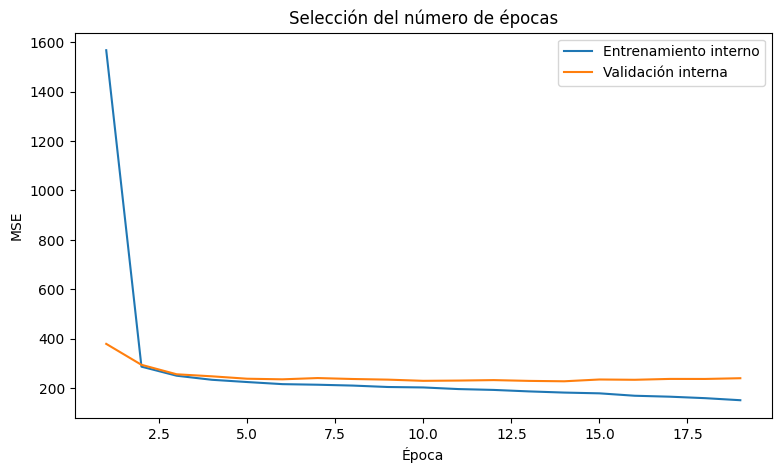

In [83]:
epocas = range(
    1,
    len(history_seleccion_fd002.history["loss"]) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epocas,
    history_seleccion_fd002.history["loss"],
    label="Entrenamiento interno"
)

plt.plot(
    epocas,
    history_seleccion_fd002.history["val_loss"],
    label="Validación interna"
)

plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Selección del número de épocas")
plt.legend()

plt.show()

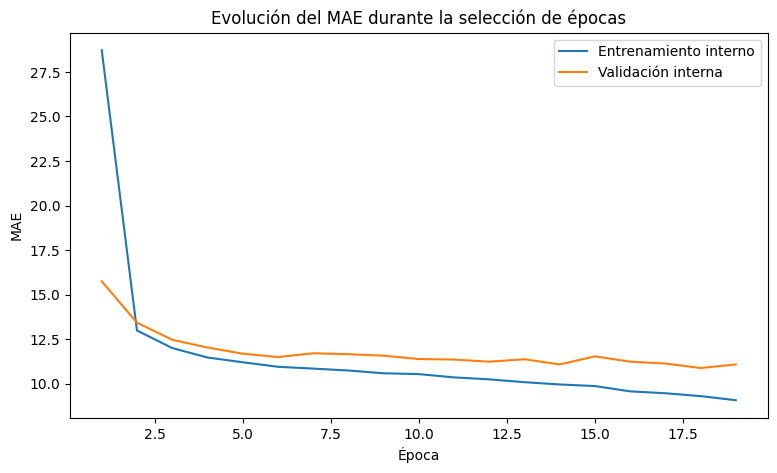

In [84]:
plt.figure(figsize=(9, 5))

plt.plot(
    epocas,
    history_seleccion_fd002.history["mae"],
    label="Entrenamiento interno"
)

plt.plot(
    epocas,
    history_seleccion_fd002.history["val_mae"],
    label="Validación interna"
)

plt.xlabel("Época")
plt.ylabel("MAE")
plt.title("Evolución del MAE durante la selección de épocas")
plt.legend()

plt.show()

In [85]:
model_fd002 = crear_modelo_lstm_fd002()

history_fd002_final = model_fd002.fit(
    X_dev,
    y_dev,
    epochs=mejor_epoca,
    batch_size=64,
    verbose=1
)

Epoch 1/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - loss: 1251.5216 - mae: 24.6557
Epoch 2/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - loss: 259.9539 - mae: 12.1634
Epoch 3/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 236.2188 - mae: 11.4521
Epoch 4/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - loss: 225.8298 - mae: 11.1253
Epoch 5/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - loss: 217.3976 - mae: 10.9094
Epoch 6/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 213.5082 - mae: 10.7578
Epoch 7/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - loss: 207.7052 - mae: 10.6108
Epoch 8/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - loss: 201.2652 - mae: 10.4306
Epoch 9/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - loss: 196.6931 - mae: 10.2889
Epoch 10/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - loss: 189.7746 - mae: 10.1174
Epoch 11/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 182.4469 - mae: 9.8779
Epoch 12/14
585/585 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/ste

Para seleccionar el número de épocas sin utilizar los 52 motores reservados para la validación posterior, los 208 motores del subconjunto de desarrollo se dividieron temporalmente en 166 motores para entrenamiento interno y 42 motores para validación interna.
La división se realizó a nivel de motor y no se produjo ningún solapamiento entre ambas particiones. Tras aplicar la normalización por régimen utilizando exclusivamente estadísticas calculadas sobre los 166 motores de entrenamiento interno, se generaron 29.891 secuencias para entrenamiento y 7.541 para validación interna.
El modelo preliminar se entrenó utilizando `EarlyStopping` sobre la pérdida de validación, con una paciencia de cinco épocas y restauración de los mejores pesos. El entrenamiento se detuvo después de 19 épocas, alcanzándose el menor valor de pérdida de validación en la época 14, con un MSE de aproximadamente 228,58 y un MAE de 11,08 ciclos.
A partir de la época 14, la pérdida de entrenamiento continuó disminuyendo mientras que la pérdida de validación dejó de mejorar de forma sostenida, lo que indica que prolongar el ajuste no aportaba una mejora adicional sobre los motores utilizados para la selección de épocas.
Una vez determinado el número de épocas, el modelo preliminar se descartó y se creó una nueva red con la misma arquitectura. Este modelo se entrenó desde cero utilizando los 208 motores completos del subconjunto de desarrollo durante exactamente 14 épocas.
Al finalizar este entrenamiento, el modelo obtuvo sobre las secuencias de desarrollo un MSE de aproximadamente 158,58 y un MAE de 9,23 ciclos. Estas métricas corresponden exclusivamente al conjunto utilizado para el ajuste y no se consideran una medida de generalización.
Los 52 motores reservados para validación no han intervenido ni en el ajuste de la normalización utilizada por el modelo definitivo, ni en la selección del número de épocas, ni en el entrenamiento de la red. Por tanto, pueden utilizarse a continuación para realizar una validación interna independiente del modelo obtenido.

### 10.5. Evaluación del modelo sobre el subconjunto de validación

Una vez finalizado el entrenamiento, se evalúa el modelo utilizando todas las secuencias correspondientes a los 52 motores de validación.

Se utilizan como métricas el error absoluto medio (MAE), la raíz del error cuadrático medio (RMSE) y el coeficiente de determinación ($R^2$). Estas métricas permiten cuantificar respectivamente el error medio de las estimaciones, penalizar en mayor medida los errores elevados y medir la proporción de variabilidad de la RUL explicada por el modelo.

Las predicciones se mantienen en su valor original y no se limitan artificialmente al intervalo de la variable objetivo. De esta forma, la evaluación refleja directamente el comportamiento de la salida lineal de la red.

In [86]:
y_pred_val = model_fd002.predict(
    X_val,
    verbose=0
).ravel()

mae_val = mean_absolute_error(
    y_val,
    y_pred_val
)

rmse_val = np.sqrt(
    mean_squared_error(
        y_val,
        y_pred_val
    )
)

r2_val = r2_score(
    y_val,
    y_pred_val
)

print(f"MAE validación:  {mae_val:.4f}")
print(f"RMSE validación: {rmse_val:.4f}")
print(f"R² validación:   {r2_val:.4f}")

print(
    "\nRango de predicciones:",
    f"{y_pred_val.min():.2f}",
    "-",
    f"{y_pred_val.max():.2f}"
)

MAE validación:  10.9165
RMSE validación: 15.5940
R² validación:   0.8488

Rango de predicciones: 1.60 - 121.48


In [87]:
evaluacion_val = meta_val.copy()

evaluacion_val["RUL_pred"] = y_pred_val

evaluacion_val["error"] = (
    evaluacion_val["RUL_pred"]
    - evaluacion_val["RUL_piecewise"]
)

evaluacion_val["error_abs"] = (
    evaluacion_val["error"].abs()
)

display(
    evaluacion_val.head()
)

,unit,cycle,RUL,RUL_piecewise,operating_regime,RUL_pred,error,error_abs
0,7,30,144,120,4,105.234840,-14.765160,14.765160
1,7,31,143,120,3,108.599434,-11.400566,11.400566
2,7,32,142,120,4,113.052773,-6.947227,6.947227
3,7,33,141,120,1,117.265366,-2.734634,2.734634
4,7,34,140,120,3,116.622147,-3.377853,3.377853


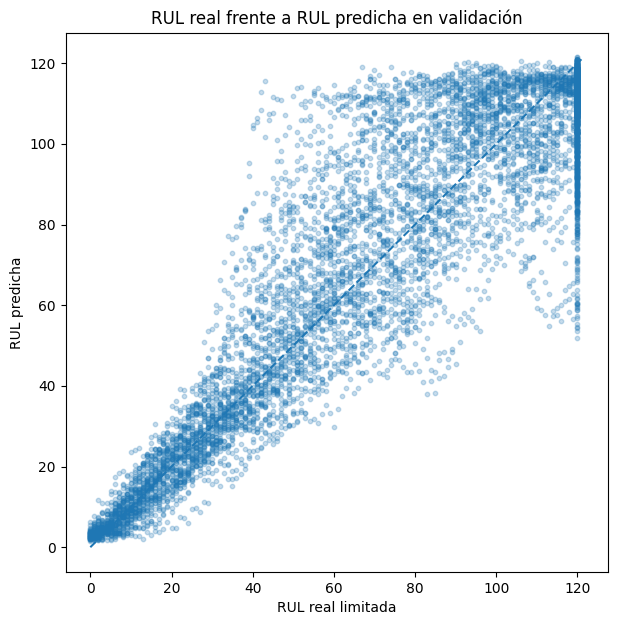

In [88]:
plt.figure(figsize=(7, 7))

plt.scatter(
    evaluacion_val["RUL_piecewise"],
    evaluacion_val["RUL_pred"],
    s=10,
    alpha=0.25
)

limite_min = min(
    evaluacion_val["RUL_piecewise"].min(),
    evaluacion_val["RUL_pred"].min()
)

limite_max = max(
    evaluacion_val["RUL_piecewise"].max(),
    evaluacion_val["RUL_pred"].max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("RUL real limitada")
plt.ylabel("RUL predicha")
plt.title("RUL real frente a RUL predicha en validación")

plt.show()

Los resultados obtenidos sobre el subconjunto de validación muestran un comportamiento adecuado del modelo sobre motores no utilizados durante el ajuste ni la selección del modelo definitivo.

El error absoluto medio es de aproximadamente 10,92 ciclos, mientras que el RMSE alcanza 15,59 ciclos. La diferencia entre ambas métricas indica la existencia de algunas predicciones con errores superiores a la media, que reciben una mayor penalización en el cálculo del RMSE.

El coeficiente de determinación alcanza un valor de $R^2 = 0,849$, lo que indica que el modelo explica aproximadamente el 84,9 % de la variabilidad de la RUL limitada presente en el subconjunto de validación.

Las predicciones se encuentran entre 1,60 y 121,48 ciclos. A pesar de utilizar una neurona de salida lineal y no aplicar ningún recorte posterior, los valores generados permanecen muy próximos al intervalo definido para la variable objetivo.

La representación de la RUL real frente a la predicha muestra una relación clara alrededor de la diagonal de referencia, especialmente en las etapas más próximas al final de vida. A medida que aumenta la RUL se observa una mayor dispersión de las predicciones, principalmente en los valores intermedios y elevados.

También se observa una concentración vertical de observaciones en `RUL = 120`, consecuencia directa de la definición por tramos de la variable objetivo. Estas observaciones corresponden a ciclos cuya RUL lineal real es igual o superior a 120, pero que se agrupan bajo el mismo valor objetivo durante el entrenamiento. Dentro de esta región, el modelo presenta una mayor dispersión, lo que resulta coherente con la menor diferenciación impuesta entre los estados iniciales mediante la definición piecewise.

En conjunto, los resultados indican que la arquitectura LSTM seleccionada previamente puede adaptarse al escenario de múltiples condiciones operativas de FD002 cuando los sensores se normalizan teniendo en cuenta el régimen de funcionamiento.

### 10.6. Análisis del error según la etapa de degradación

Las métricas globales permiten resumir el comportamiento general del modelo, pero no permiten conocer si la precisión es homogénea a lo largo de toda la trayectoria.

Desde el punto de vista del mantenimiento predictivo, resulta especialmente relevante conocer el rendimiento en las etapas próximas al final de vida, donde una estimación incorrecta de la RUL puede tener una mayor importancia operativa.

Por este motivo, las predicciones de validación se agrupan según diferentes intervalos de `RUL_piecewise` y se calculan de forma independiente el MAE, RMSE y sesgo medio en cada región.

In [89]:
def asignar_zona_rul(rul):
    if rul <= 30:
        return "0-30"
    elif rul <= 60:
        return "31-60"
    elif rul <= 90:
        return "61-90"
    elif rul < 120:
        return "91-119"
    else:
        return "120"

evaluacion_val["zona_RUL"] = (
    evaluacion_val["RUL_piecewise"]
    .apply(asignar_zona_rul)
)

orden_zonas = [
    "0-30",
    "31-60",
    "61-90",
    "91-119",
    "120"
]

resultados_por_zona = []

for zona in orden_zonas:
    datos = evaluacion_val[
        evaluacion_val["zona_RUL"] == zona
    ]

    mae = mean_absolute_error(
        datos["RUL_piecewise"],
        datos["RUL_pred"]
    )

    rmse = np.sqrt(
        mean_squared_error(
            datos["RUL_piecewise"],
            datos["RUL_pred"]
        )
    )

    sesgo = datos["error"].mean()

    resultados_por_zona.append({
        "Zona RUL": zona,
        "Observaciones": len(datos),
        "MAE": mae,
        "RMSE": rmse,
        "Sesgo medio": sesgo
    })

resultados_por_zona = pd.DataFrame(
    resultados_por_zona
)

display(
    resultados_por_zona.round(2)
)

,Zona RUL,Observaciones,MAE,RMSE,Sesgo medio
0,0-30,1612,3.94,5.21,0.92
1,31-60,1560,13.26,18.91,7.51
2,61-90,1560,17.25,21.09,7.83
3,91-119,1467,11.74,15.40,-2.05
4,120,2588,9.56,13.81,-9.55


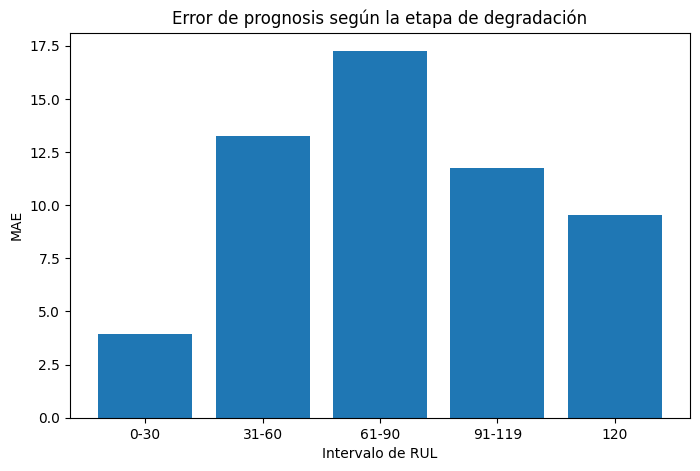

In [90]:
plt.figure(figsize=(8, 5))

plt.bar(
    resultados_por_zona["Zona RUL"],
    resultados_por_zona["MAE"]
)

plt.xlabel("Intervalo de RUL")
plt.ylabel("MAE")
plt.title("Error de prognosis según la etapa de degradación")

plt.show()

Los resultados muestran que el error del modelo no se distribuye de forma homogénea a lo largo de toda la vida útil del motor.

La mayor precisión se obtiene en la etapa más próxima al final de vida, correspondiente a `RUL <= 30`, donde el MAE se reduce hasta aproximadamente 3,94 ciclos y el RMSE hasta 5,21 ciclos. El sesgo medio es de únicamente +0,92 ciclos, por lo que las predicciones se mantienen además relativamente equilibradas en esta región. Este resultado resulta especialmente relevante desde el punto de vista del mantenimiento predictivo, ya que corresponde a los estados de degradación más avanzados.

En los intervalos intermedios el error aumenta. Para RUL entre 31 y 60 ciclos el MAE alcanza 13,26 ciclos, mientras que entre 61 y 90 ciclos aumenta hasta 17,25 ciclos, siendo esta última la región con mayor error.

El análisis del sesgo muestra además que en estas dos zonas el modelo tiende a sobreestimar la vida útil restante, con errores medios de +7,51 y +7,83 ciclos, respectivamente. Por tanto, durante estas etapas la red tiende a predecir una RUL superior a la real.

En cambio, para valores comprendidos entre 91 y 119 ciclos aparece un sesgo negativo de aproximadamente -2,05 ciclos. Esta tendencia se intensifica en la región limitada a `RUL = 120`, donde el sesgo medio alcanza -9,55 ciclos y el MAE se sitúa en 9,56 ciclos. En esta última región todas las observaciones comparten el mismo valor objetivo debido a la definición piecewise, por lo que el modelo tiende a generar estimaciones inferiores al límite máximo.

En conjunto, se observa una tendencia de la red a aproximar las predicciones hacia valores intermedios de RUL: subestima parcialmente la región inicial limitada a 120 ciclos y sobreestima determinadas etapas intermedias de degradación.

No obstante, el rendimiento mejora considerablemente al aproximarse al final de vida. En la región de mayor interés operativo, correspondiente a `RUL <= 30`, el modelo presenta tanto el menor error como un sesgo reducido.

### 10.7. Error de prognosis según el régimen operativo

Dado que FD002 contiene seis condiciones de funcionamiento, se comprueba si el error de prognosis depende sistemáticamente del régimen operativo correspondiente al último ciclo de cada ventana.

El objetivo es verificar que la normalización aplicada permite al modelo mantener un rendimiento comparable entre condiciones y que ningún régimen concentra errores claramente superiores al resto.

In [91]:
resultados_por_regimen = []

for regimen in sorted(
    evaluacion_val["operating_regime"].unique()
):
    datos = evaluacion_val[
        evaluacion_val["operating_regime"] == regimen
    ]

    resultados_por_regimen.append({
        "Régimen": regimen,
        "Observaciones": len(datos),

        "MAE": mean_absolute_error(
            datos["RUL_piecewise"],
            datos["RUL_pred"]
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                datos["RUL_piecewise"],
                datos["RUL_pred"]
            )
        ),

        "Sesgo medio": datos["error"].mean()
    })

resultados_por_regimen = pd.DataFrame(
    resultados_por_regimen
)

display(resultados_por_regimen.round(2))

,Régimen,Observaciones,MAE,RMSE,Sesgo medio
0,1,1316,10.66,15.44,0.15
1,2,1286,10.71,15.31,-0.61
2,3,1349,11.04,15.91,0.50
3,4,1351,10.92,15.49,-0.50
4,5,1289,11.31,15.93,-0.57
5,6,2196,10.88,15.52,-0.44


Los resultados muestran un comportamiento muy homogéneo entre los seis regímenes operativos.

El MAE se encuentra en un intervalo reducido, desde 10,66 ciclos en el régimen 1 hasta 11,31 ciclos en el régimen 5. De forma similar, el RMSE se mantiene aproximadamente entre 15,31 y 15,93 ciclos en todas las condiciones.

Los sesgos medios son también muy reducidos, con valores comprendidos entre -0,61 y +0,50 ciclos. Por tanto, no se observa una tendencia sistemática relevante hacia la sobreestimación o subestimación de la RUL asociada a ninguna condición operativa concreta.

El régimen 6, a pesar de contener un número considerablemente mayor de observaciones, presenta un MAE de 10,88 ciclos y un RMSE de 15,52 ciclos, valores completamente comparables a los obtenidos en los demás regímenes.

Estos resultados indican que el rendimiento de la LSTM no presenta diferencias relevantes asociadas al régimen operativo correspondiente al último ciclo de cada ventana.

Por tanto, los resultados respaldan que la normalización específica por régimen reduce adecuadamente las diferencias de nivel existentes entre las seis condiciones y proporciona a la red una representación suficientemente homogénea para realizar la prognosis mediante un único modelo.

### 10.8. Evaluación en el último ciclo de cada motor

Las métricas anteriores consideran todas las ventanas temporales disponibles en los motores de validación. Sin embargo, en el problema de prognosis de C-MAPSS resulta especialmente relevante la estimación realizada en el último ciclo observado de cada trayectoria.

Por este motivo, se selecciona para cada uno de los 52 motores de validación la última predicción disponible y se evalúa de forma independiente.

Este análisis permite aproximar el escenario utilizado posteriormente con el conjunto oficial de test, donde el objetivo consiste en estimar la vida útil restante a partir del final de cada trayectoria parcial observada.

In [92]:
ultimo_ciclo_val = (
    evaluacion_val
    .sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
    .copy()
)

print("Motores evaluados:", ultimo_ciclo_val["unit"].nunique())

mae_terminal_val = mean_absolute_error(
    ultimo_ciclo_val["RUL_piecewise"],
    ultimo_ciclo_val["RUL_pred"]
)

rmse_terminal_val = np.sqrt(
    mean_squared_error(
        ultimo_ciclo_val["RUL_piecewise"],
        ultimo_ciclo_val["RUL_pred"]
    )
)

print(f"MAE último ciclo:  {mae_terminal_val:.4f}")
print(f"RMSE último ciclo: {rmse_terminal_val:.4f}")

Motores evaluados: 52
MAE último ciclo:  3.1557
RMSE último ciclo: 3.2900


In [93]:
display(
    ultimo_ciclo_val[
        [
            "unit",
            "cycle",
            "RUL_piecewise",
            "RUL_pred",
            "error",
            "error_abs"
        ]
    ].head(10)
)

,unit,cycle,RUL_piecewise,RUL_pred,error,error_abs
144,7,174,0,4.364385,4.364385,4.364385
299,10,184,0,6.358599,6.358599,6.358599
541,11,271,0,3.363427,3.363427,3.363427
666,16,154,0,3.091432,3.091432,3.091432
800,19,163,0,3.366612,3.366612,3.366612
925,20,154,0,2.880774,2.880774,2.880774
1101,25,205,0,3.095888,3.095888,3.095888
1259,26,187,0,3.187546,3.187546,3.187546
1573,31,343,0,1.945528,1.945528,1.945528
1749,34,205,0,2.381581,2.381581,2.381581


In [94]:
print(ultimo_ciclo_val["RUL_pred"].describe())

count    52.000000
mean      3.155690
std       0.939652
min       1.598262
25%       2.447741
50%       3.093660
75%       3.641183
max       6.358599
Name: RUL_pred, dtype: float64


La evaluación sobre el último ciclo de los 52 motores de validación muestra que la LSTM genera estimaciones próximas al final de vida real.

El MAE terminal es de aproximadamente 3,16 ciclos y el RMSE de 3,29 ciclos. Las predicciones realizadas en el último ciclo se encuentran entre aproximadamente 1,60 y 6,36 ciclos, con una media de 3,16 y una mediana de 3,09 ciclos.

Por tanto, aunque la red no predice exactamente cero cuando los motores alcanzan el final de vida, sus estimaciones se mantienen próximas a este valor y presentan una dispersión reducida entre trayectorias.

El valor de $R^2$ no resulta interpretable en esta evaluación. Todos los motores presentan `RUL = 0` en su último ciclo y, por tanto, la variable objetivo no contiene variabilidad. En consecuencia, el análisis terminal se basa únicamente en MAE, RMSE y en la distribución de las predicciones.

Estos resultados deben interpretarse como una comprobación adicional del comportamiento del modelo en estados de degradación extrema y no como una estimación definitiva de su rendimiento sobre el problema de test. La evaluación principal se realizará posteriormente sobre el conjunto oficial `test_FD002`, cuyas trayectorias finalizan antes del fallo y presentan diferentes valores reales de vida útil restante.

## 11. Entrenamiento final y evaluación sobre el test oficial FD002

Una vez definida y validada la metodología sobre la partición interna de desarrollo y validación, se entrena el modelo definitivo utilizando los 260 motores disponibles en `train_FD002`.

En esta fase se recalculan las estadísticas de normalización por régimen utilizando exclusivamente el conjunto oficial de entrenamiento completo. Estas estadísticas quedan posteriormente fijadas y se aplican sin reajuste sobre `test_FD002`.

La arquitectura, las variables de entrada, el tamaño de ventana y los demás parámetros del modelo se mantienen sin modificaciones respecto a los seleccionados durante la fase de validación.

Dado que la mejor pérdida de validación se obtuvo en la época 14 durante la fase de selección interna, el modelo definitivo se entrena durante 14 épocas sobre el conjunto completo de entrenamiento.

El conjunto oficial `test_FD002` se utiliza únicamente después de haber cerrado estas decisiones metodológicas.

### 11.1. Carga del conjunto oficial de test y RUL real

In [95]:
test_fd002 = pd.read_csv(
    f"{RAW_DATA_PATH}/test_FD002.txt",
    sep=r"\s+",
    header=None,
    names=column_names
)

rul_fd002 = pd.read_csv(
    f"{RAW_DATA_PATH}/RUL_FD002.txt",
    sep=r"\s+",
    header=None,
    names=["RUL_last"]
)

rul_fd002["unit"] = np.arange(
    1,
    len(rul_fd002) + 1
)

print("TEST FD002")
print("Dimensiones:", test_fd002.shape)
print("Motores:", test_fd002["unit"].nunique())

print("\nRUL FD002")
print("Motores:", len(rul_fd002))

display(rul_fd002.head())

TEST FD002
Dimensiones: (33991, 26)
Motores: 259

RUL FD002
Motores: 259


,RUL_last,unit
0,18,1
1,79,2
2,106,3
3,110,4
4,15,5


El conjunto oficial `test_FD002` contiene 33.991 observaciones correspondientes a 259 motores.

El archivo `RUL_FD002.txt` proporciona igualmente 259 valores de vida útil restante, uno para cada motor del conjunto de test. Estos valores representan la RUL real existente después del último ciclo observado de cada trayectoria y se utilizarán exclusivamente durante la evaluación final del modelo.

A diferencia del conjunto de entrenamiento, las trayectorias de test no alcanzan necesariamente el final de vida. Por tanto, el objetivo de la prognosis consiste en estimar la RUL restante a partir de la última información disponible de cada motor.

### 11.2. Asignación de los regímenes operativos en test

Las observaciones de `test_FD002` se asignan a los seis regímenes identificados previamente sobre el conjunto de entrenamiento.

No se realiza ningún nuevo proceso de agrupamiento sobre el conjunto de test. Se utilizan directamente las combinaciones nominales establecidas durante el análisis de entrenamiento.

In [96]:
test_fd002_reg = test_fd002.copy()

test_fd002_reg["op1_nominal"] = (
    test_fd002_reg["op_setting_1"].round(0)
)

test_fd002_reg["op2_nominal"] = (
    test_fd002_reg["op_setting_2"].round(2)
)

test_fd002_reg["op3_nominal"] = (
    test_fd002_reg["op_setting_3"].round(0)
)

test_fd002_reg["operating_regime"] = [
    regime_mapping.get((op1, op2, op3), np.nan)
    for op1, op2, op3 in zip(
        test_fd002_reg["op1_nominal"],
        test_fd002_reg["op2_nominal"],
        test_fd002_reg["op3_nominal"]
    )
]

print(
    "Observaciones sin régimen asignado:",
    test_fd002_reg["operating_regime"].isna().sum()
)

print("\nDistribución de regímenes:")
print(
    test_fd002_reg["operating_regime"]
    .value_counts()
    .sort_index()
)

Observaciones sin régimen asignado: 0

Distribución de regímenes:
operating_regime
1    5148
2    5107
3    5063
4    5042
5    5148
6    8483
Name: count, dtype: int64


Todas las observaciones del conjunto oficial de test han podido asignarse a uno de los seis regímenes operativos definidos previamente sobre los datos de entrenamiento. No se detecta ninguna observación sin una condición de funcionamiento reconocida.

Los seis regímenes se encuentran representados en el conjunto de test. Los cinco primeros presentan alrededor de 5.000 observaciones cada uno, mientras que el régimen 6 vuelve a mostrar una frecuencia superior, con 8.483 observaciones.

Esta distribución mantiene el comportamiento observado previamente en el conjunto de entrenamiento, donde el régimen 6 también presentaba una mayor frecuencia.

La ausencia de regímenes desconocidos permite aplicar directamente al conjunto de test las estadísticas de normalización aprendidas exclusivamente sobre `train_FD002`, sin necesidad de introducir nuevas condiciones o reajustar el procedimiento utilizando información de test.

### 11.3. Ajuste definitivo de la normalización por régimen

Una vez finalizada la fase de selección y validación, las estadísticas definitivas de normalización se recalculan utilizando los 260 motores del conjunto oficial de entrenamiento.

Estas estadísticas constituyen los parámetros finales de preprocesamiento y se aplican posteriormente sobre `test_FD002` sin utilizar información procedente de este conjunto para su estimación.

In [97]:
estadisticas_regimen_final = (
    train_fd002_reg
    .groupby("operating_regime")[sensores_modelo]
    .agg(["mean", "std"])
)

train_fd002_final = normalizar_por_regimen(
    train_fd002_reg,
    estadisticas_regimen_final,
    sensores_modelo
)

test_fd002_final = normalizar_por_regimen(
    test_fd002_reg,
    estadisticas_regimen_final,
    sensores_modelo
)

train_fd002_final["RUL_piecewise"] = np.minimum(
    train_fd002_final["RUL"],
    RUL_MAX
)

Una vez cerrada la fase de desarrollo y validación, las estadísticas de normalización se recalculan utilizando los 260 motores disponibles en `train_FD002`.

De esta forma se aprovecha toda la información del conjunto oficial de entrenamiento para estimar los parámetros finales de preprocesamiento. Estas estadísticas quedan fijadas antes de realizar la evaluación y se aplican directamente sobre `test_FD002`, sin calcular medias o desviaciones utilizando las observaciones de test.

La variable objetivo del conjunto de entrenamiento se mantiene limitada a `RUL_MAX = 120`, conservando la definición seleccionada durante la fase experimental.

Este procedimiento garantiza que el modelo definitivo utiliza toda la información disponible para entrenamiento sin introducir información procedente del conjunto reservado para evaluación.

### 11.4. Construcción de las secuencias definitivas

Una vez aplicada la normalización definitiva por régimen, se construyen las secuencias temporales que se utilizarán para el entrenamiento final y la evaluación sobre el conjunto oficial de test.

En el conjunto de entrenamiento se generan ventanas de 30 ciclos consecutivos asociadas a la variable objetivo `RUL_piecewise`. En el conjunto de test se construyen las mismas ventanas utilizando exclusivamente las variables predictoras, ya que la RUL real se proporciona de forma independiente mediante `RUL_FD002.txt`.

Las secuencias se generan de forma independiente para cada motor, evitando mezclar observaciones pertenecientes a trayectorias diferentes y manteniendo el mismo tamaño de ventana utilizado durante la fase de desarrollo y validación.

In [98]:
X_train_final, y_train_final, meta_train_final = crear_secuencias_rul(
    train_fd002_final,
    features_modelo,
    target="RUL_piecewise",
    window_size=WINDOW_SIZE
)

print("X_train_final:", X_train_final.shape)
print("y_train_final:", y_train_final.shape)
print(
    "Motores:",
    meta_train_final["unit"].nunique()
)

X_train_final: (46219, 30, 14)
y_train_final: (46219,)
Motores: 260


In [99]:
def crear_secuencias_test(
    df,
    features,
    window_size=30
):
    X = []
    metadata = []

    for unit, grupo in df.groupby("unit"):
        grupo = grupo.sort_values("cycle").reset_index(drop=True)

        valores = grupo[features].to_numpy(dtype=np.float32)

        for end_idx in range(window_size - 1, len(grupo)):
            start_idx = end_idx - window_size + 1

            X.append(
                valores[start_idx:end_idx + 1]
            )

            metadata.append({
                "unit": unit,
                "cycle": grupo.loc[end_idx, "cycle"],
                "operating_regime": grupo.loc[
                    end_idx,
                    "operating_regime"
                ]
            })

    return (
        np.asarray(X, dtype=np.float32),
        pd.DataFrame(metadata)
    )

In [100]:
X_test_final, meta_test_final = crear_secuencias_test(
    test_fd002_final,
    features_modelo,
    window_size=WINDOW_SIZE
)

print("X_test_final:", X_test_final.shape)
print(
    "Motores:",
    meta_test_final["unit"].nunique()
)

X_test_final: (26505, 30, 14)
Motores: 253


La construcción de las secuencias definitivas genera 46.219 ventanas de entrenamiento, cada una formada por 30 ciclos consecutivos y los 14 sensores seleccionados. Las secuencias incluyen los 260 motores disponibles en `train_FD002`.

La reducción respecto a las 53.759 observaciones originales se debe a que los primeros 29 ciclos de cada trayectoria no disponen de un histórico completo de 30 observaciones y, por tanto, no pueden utilizarse como entrada de la LSTM.

En el conjunto oficial de test se generan 26.505 ventanas temporales. Sin embargo, estas secuencias corresponden únicamente a 253 de los 259 motores disponibles.

Esta diferencia indica que existen trayectorias de test que no alcanzan el número mínimo de 30 ciclos requerido por la arquitectura. Por este motivo, antes de realizar la evaluación final es necesario analizar la cobertura del modelo y las características de los motores que no pueden generar una ventana completa.

### 11.5. Cobertura del conjunto oficial de test

La construcción de las secuencias temporales muestra que no todos los motores del conjunto oficial de test disponen del histórico mínimo necesario para generar una ventana completa de 30 ciclos.

Por este motivo, se comprueba la longitud de las trayectorias que no han podido incorporarse a `X_test_final` antes de continuar con el entrenamiento y la evaluación definitiva del modelo.

In [101]:
ciclos_test_fd002 = (
    test_fd002_reg
    .groupby("unit")["cycle"]
    .max()
    .sort_values()
)

motores_test_cortos = ciclos_test_fd002[
    ciclos_test_fd002 < WINDOW_SIZE
]

print(
    "Motores con menos de 30 ciclos:",
    len(motores_test_cortos)
)

display(
    motores_test_cortos.to_frame(
        "Número de ciclos"
    )
)

Motores con menos de 30 ciclos: 6


,Número de ciclos
unit,
83,21
59,22
28,23
201,25
223,29
122,29


In [102]:
revision_motores_cortos = (
    motores_test_cortos
    .rename("Número de ciclos")
    .reset_index()
    .merge(
        rul_fd002,
        on="unit",
        how="left"
    )
)

display(revision_motores_cortos)

,unit,Número de ciclos,RUL_last
0,83,21,146
1,59,22,178
2,28,23,138
3,201,25,111
4,223,29,151
5,122,29,145


In [103]:
cobertura_test = (
    meta_test_final["unit"].nunique()
    / test_fd002["unit"].nunique()
    * 100
)

print(
    f"Cobertura del test: {cobertura_test:.2f} %"
)

Cobertura del test: 97.68 %


La comprobación de la longitud de las trayectorias muestra que 6 de los 259 motores de `test_FD002` no alcanzan los 30 ciclos necesarios para construir una ventana completa de entrada.

Concretamente, los motores 83, 59, 28, 201, 223 y 122 presentan entre 21 y 29 ciclos observados. Como consecuencia, el modelo puede generar predicciones para 253 motores, lo que representa una cobertura del 97,68 % del conjunto oficial de test.

No se introduce un procedimiento de relleno artificial (*padding*) únicamente para estas trayectorias, ya que la LSTM ha sido desarrollada y validada utilizando exclusivamente ventanas completas de 30 ciclos. Del mismo modo, no se modifica el tamaño de ventana después de analizar el conjunto de test, puesto que esta decisión metodológica fue fijada previamente durante la fase de desarrollo.

En consecuencia, la evaluación final se realizará sobre los 253 motores que cumplen el requisito mínimo de histórico. La exclusión responde exclusivamente a una limitación de entrada de la arquitectura y no al rendimiento obtenido por el modelo.

Esta reducción de cobertura se reportará explícitamente al presentar las métricas finales, que corresponderán a los motores elegibles del conjunto oficial de test y no a la totalidad de los 259 motores.

### 11.6. Entrenamiento definitivo de la LSTM

Una vez completada la fase de desarrollo y fijados los hiperparámetros del modelo, se construye una nueva instancia de la LSTM para realizar el entrenamiento definitivo.

El modelo mantiene exactamente la misma arquitectura utilizada durante la validación: una capa LSTM de 64 unidades, una capa `Dropout` con tasa 0,2, una capa densa de 32 neuronas y una salida lineal para la estimación de la RUL.

En esta fase se utilizan conjuntamente los 260 motores de `train_FD002`, generando 46.219 secuencias temporales de entrenamiento.

El número de épocas se fija en 14, correspondiente a la época que obtuvo la menor pérdida de validación durante la fase de selección interna. De esta forma, la duración del entrenamiento se determina antes de utilizar el conjunto oficial de test.

No se emplea `test_FD002` para ajustar el modelo, seleccionar hiperparámetros o determinar el número de épocas.

In [104]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model_fd002_final = Sequential([
    Input(
        shape=(
            WINDOW_SIZE,
            len(features_modelo)
        )
    ),

    LSTM(64),

    Dropout(0.2),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        1,
        activation="linear"
    )
])

model_fd002_final.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model_fd002_final.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,337 (87.25 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

In [105]:
history_fd002_final = model_fd002_final.fit(
    X_train_final,
    y_train_final,
    epochs=14,
    batch_size=64,
    verbose=1
)

Epoch 1/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 25s 33ms/step - loss: 1106.1483 - mae: 23.1727
Epoch 2/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 30s 18ms/step - loss: 268.0116 - mae: 12.3942
Epoch 3/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - loss: 242.2733 - mae: 11.6612
Epoch 4/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - loss: 233.1624 - mae: 11.3805
Epoch 5/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - loss: 226.2230 - mae: 11.1504
Epoch 6/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 220.9035 - mae: 10.9668
Epoch 7/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - loss: 214.7610 - mae: 10.8027
Epoch 8/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 208.5018 - mae: 10.6304
Epoch 9/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - loss: 201.7278 - mae: 10.4389
Epoch 10/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - loss: 197.8052 - mae: 10.3299
Epoch 11/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 190.7289 - mae: 10.1326
Epoch 12/14
723/723 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/s

In [106]:
for i in range(
    len(history_fd002_final.history["loss"])
):
    print(
        f"Época {i + 1}: "
        f"loss = "
        f"{history_fd002_final.history['loss'][i]:.4f} | "
        f"MAE = "
        f"{history_fd002_final.history['mae'][i]:.4f}"
    )

Época 1: loss = 1106.1483 | MAE = 23.1727
Época 2: loss = 268.0116 | MAE = 12.3942
Época 3: loss = 242.2733 | MAE = 11.6612
Época 4: loss = 233.1624 | MAE = 11.3805
Época 5: loss = 226.2230 | MAE = 11.1504
Época 6: loss = 220.9035 | MAE = 10.9668
Época 7: loss = 214.7610 | MAE = 10.8027
Época 8: loss = 208.5018 | MAE = 10.6304
Época 9: loss = 201.7278 | MAE = 10.4389
Época 10: loss = 197.8052 | MAE = 10.3299
Época 11: loss = 190.7289 | MAE = 10.1326
Época 12: loss = 185.4142 | MAE = 9.9735
Época 13: loss = 177.6863 | MAE = 9.7487
Época 14: loss = 170.2811 | MAE = 9.5570


El modelo definitivo mantiene exactamente la arquitectura seleccionada durante la fase de desarrollo, con un total de 22.337 parámetros entrenables.

Durante las 14 épocas de entrenamiento se observa una reducción progresiva del error. El MSE disminuye desde 1.106,15 en la primera época hasta 170,28 en la última, mientras que el MAE pasa de 23,17 a 9,56 ciclos.

La mayor reducción del error se produce durante las primeras épocas, aunque posteriormente el modelo continúa mejorando de forma gradual hasta completar las 14 épocas fijadas previamente durante la fase de selección interna.

Estos valores corresponden exclusivamente al conjunto completo de entrenamiento y, por tanto, no deben interpretarse como una estimación de la capacidad de generalización del modelo. En esta fase no se utiliza un subconjunto de validación, ya que los 260 motores disponibles en `train_FD002` se emplean para ajustar el modelo definitivo.

La duración del entrenamiento se mantiene fijada en 14 épocas a partir del resultado obtenido previamente durante la selección interna, evitando utilizar el conjunto oficial de test para decidir cuándo detener el entrenamiento.

Una vez finalizado este ajuste, el modelo queda completamente definido y puede evaluarse sobre las trayectorias elegibles de `test_FD002`.

### 11.7. Evaluación definitiva sobre el conjunto oficial de test

Una vez entrenado el modelo definitivo, se realizan predicciones sobre las secuencias generadas a partir de `test_FD002`.

Para reproducir el escenario de prognosis planteado por C-MAPSS, se selecciona únicamente la predicción correspondiente al último ciclo observado de cada motor. Esta estimación se obtiene a partir de la ventana formada por los últimos 30 ciclos disponibles de cada trayectoria de test.

Las predicciones se comparan posteriormente con los valores proporcionados en `RUL_FD002.txt`, que representan la vida útil restante real después del último ciclo observado de cada motor.

Dado que el modelo ha sido entrenado utilizando una RUL limitada a `RUL_MAX = 120`, la evaluación principal utiliza igualmente como referencia `min(RUL_last, 120)`. De esta forma, la variable objetivo empleada durante la evaluación mantiene la misma definición que durante el entrenamiento.

La evaluación se realiza sobre los 253 motores que disponen de al menos 30 ciclos de histórico, correspondientes al 97,68 % de los 259 motores del conjunto oficial de test.

In [107]:
y_pred_test = model_fd002_final.predict(
    X_test_final,
    verbose=0
).ravel()

predicciones_test = meta_test_final.copy()

predicciones_test["RUL_pred"] = y_pred_test

print(
    "Predicciones generadas:",
    len(predicciones_test)
)

print(
    "Rango de predicciones:",
    f"{y_pred_test.min():.2f}",
    "-",
    f"{y_pred_test.max():.2f}"
)

Predicciones generadas: 26505
Rango de predicciones: 4.64 - 123.51


In [108]:
ultimo_ciclo_test = (
    predicciones_test
    .sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
    .copy()
)

print(
    "Motores con predicción terminal:",
    ultimo_ciclo_test["unit"].nunique()
)

display(
    ultimo_ciclo_test.head()
)

Motores con predicción terminal: 253


,unit,cycle,operating_regime,RUL_pred
228,1,258,2,15.469918
254,2,55,1,82.719551
390,3,165,5,99.755180
447,4,86,3,57.896111
566,5,148,6,16.562740


In [109]:
assert ultimo_ciclo_test["unit"].nunique() == 253
assert not ultimo_ciclo_test["unit"].duplicated().any()

print(
    "Rango de predicciones terminales:",
    f"{ultimo_ciclo_test['RUL_pred'].min():.2f}",
    "-",
    f"{ultimo_ciclo_test['RUL_pred'].max():.2f}"
)

Rango de predicciones terminales: 4.64 - 120.08


In [110]:
evaluacion_test = (
    ultimo_ciclo_test
    .merge(
        rul_fd002,
        on="unit",
        how="left"
    )
)

evaluacion_test["RUL_real_piecewise"] = np.minimum(
    evaluacion_test["RUL_last"],
    RUL_MAX
)

evaluacion_test["error"] = (
    evaluacion_test["RUL_pred"]
    - evaluacion_test["RUL_real_piecewise"]
)

evaluacion_test["error_abs"] = (
    evaluacion_test["error"].abs()
)

print(
    "Motores evaluados:",
    len(evaluacion_test)
)

print(
    "RUL reales ausentes:",
    evaluacion_test["RUL_last"].isna().sum()
)

display(
    evaluacion_test[
        [
            "unit",
            "cycle",
            "operating_regime",
            "RUL_last",
            "RUL_real_piecewise",
            "RUL_pred",
            "error",
            "error_abs"
        ]
    ].head(10)
)

Motores evaluados: 253
RUL reales ausentes: 0


,unit,cycle,operating_regime,RUL_last,RUL_real_piecewise,RUL_pred,error,error_abs
0,1,258,2,18,18,15.469918,-2.530082,2.530082
1,2,55,1,79,79,82.719551,3.719551,3.719551
2,3,165,5,106,106,99.755180,-6.244820,6.244820
3,4,86,3,110,110,57.896111,-52.103889,52.103889
4,5,148,6,15,15,16.562740,1.562740,1.562740
5,6,63,5,155,120,106.731049,-13.268951,13.268951
6,7,184,6,6,6,7.304071,1.304071,1.304071
7,8,173,1,90,90,74.837456,-15.162544,15.162544
8,9,161,1,11,11,9.711993,-1.288007,1.288007
9,10,84,3,79,79,101.881508,22.881508,22.881508


In [111]:
print(
    "Motores con RUL_last > 120:",
    (evaluacion_test["RUL_last"] > RUL_MAX).sum()
)

print(
    "Motores con RUL_last <= 120:",
    (evaluacion_test["RUL_last"] <= RUL_MAX).sum()
)

print(
    "Motores con RUL_last = 120:",
    (evaluacion_test["RUL_last"] == RUL_MAX).sum()
)

print(
    "Motores con RUL_real_piecewise = 120:",
    (evaluacion_test["RUL_real_piecewise"] == RUL_MAX).sum()
)

Motores con RUL_last > 120: 62
Motores con RUL_last <= 120: 191
Motores con RUL_last = 120: 2
Motores con RUL_real_piecewise = 120: 64


In [112]:
mae_test = mean_absolute_error(
    evaluacion_test["RUL_real_piecewise"],
    evaluacion_test["RUL_pred"]
)

rmse_test = np.sqrt(
    mean_squared_error(
        evaluacion_test["RUL_real_piecewise"],
        evaluacion_test["RUL_pred"]
    )
)

r2_test = r2_score(
    evaluacion_test["RUL_real_piecewise"],
    evaluacion_test["RUL_pred"]
)

sesgo_test = evaluacion_test["error"].mean()

print("RESULTADOS FINALES FD002")
print(f"MAE:          {mae_test:.4f}")
print(f"RMSE:         {rmse_test:.4f}")
print(f"R²:           {r2_test:.4f}")
print(f"Sesgo medio:  {sesgo_test:.4f}")

RESULTADOS FINALES FD002
MAE:          10.4405
RMSE:         14.4134
R²:           0.8791
Sesgo medio:  -0.3171


In [113]:
print(
    evaluacion_test["RUL_pred"].describe()
)

count    253.000000
mean      71.113777
std       39.427868
min        4.639108
25%       30.832060
50%       80.661804
75%      107.372047
max      120.075638
Name: RUL_pred, dtype: float64


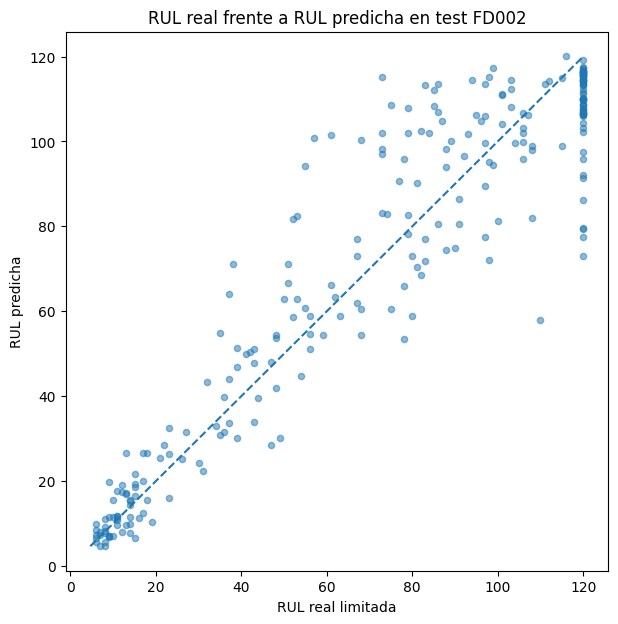

In [114]:
plt.figure(figsize=(7, 7))

plt.scatter(
    evaluacion_test["RUL_real_piecewise"],
    evaluacion_test["RUL_pred"],
    s=20,
    alpha=0.5
)

limite_min = min(
    evaluacion_test["RUL_real_piecewise"].min(),
    evaluacion_test["RUL_pred"].min()
)

limite_max = max(
    evaluacion_test["RUL_real_piecewise"].max(),
    evaluacion_test["RUL_pred"].max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("RUL real limitada")
plt.ylabel("RUL predicha")
plt.title(
    "RUL real frente a RUL predicha en test FD002"
)

plt.show()

Los resultados obtenidos sobre los 253 motores elegibles del conjunto oficial de test muestran un rendimiento consistente del modelo sobre datos no utilizados durante su desarrollo ni entrenamiento.

El error absoluto medio alcanza aproximadamente 10,44 ciclos y el RMSE se sitúa en 14,41 ciclos. La diferencia entre ambas métricas indica la presencia de algunas predicciones con errores superiores a la media, visibles también en la representación gráfica, aunque estos casos no dominan el comportamiento global del modelo.

El coeficiente de determinación alcanza un valor de $R^2 = 0,879$, lo que indica que el modelo explica aproximadamente el 87,9 % de la variabilidad de la RUL limitada presente en los motores evaluados.

El sesgo medio es de -0,32 ciclos, un valor muy próximo a cero. Por tanto, considerando conjuntamente los 253 motores evaluados, no se observa una tendencia global importante hacia la sobreestimación o la subestimación de la vida útil restante.

Las predicciones correspondientes al último ciclo observado de cada motor se encuentran entre aproximadamente 4,64 y 120,08 ciclos. A pesar de utilizar una salida lineal y no aplicar ningún recorte posterior, las estimaciones terminales permanecen prácticamente dentro del intervalo definido por la variable objetivo.

La representación de la RUL real frente a la RUL predicha muestra una relación clara alrededor de la diagonal de referencia. Las predicciones correspondientes a valores bajos de RUL presentan, en general, una mayor concentración, mientras que en determinadas regiones intermedias y elevadas se observa una mayor dispersión y algunos errores de mayor magnitud.

También se observa una acumulación de 64 motores en `RUL_real_piecewise = 120`. De ellos, 62 presentan una RUL real superior a 120 ciclos y los 2 restantes tienen exactamente 120 ciclos de vida útil restante. Esta concentración es consecuencia directa de la definición piecewise de la variable objetivo, mediante la cual todos los valores iguales o superiores a 120 se representan con el mismo valor máximo.

Los resultados son consistentes con los obtenidos durante la validación interna. El MAE pasa de 10,92 ciclos en validación a 10,44 ciclos en el conjunto oficial de test, mientras que el RMSE disminuye de 15,59 a 14,41 ciclos y el $R^2$ aumenta de 0,849 a 0,879. Por tanto, no se observa una pérdida de rendimiento al aplicar el modelo definitivo sobre los motores elegibles del conjunto oficial de test.

En conjunto, estos resultados respaldan la capacidad de la LSTM para realizar prognosis bajo las múltiples condiciones operativas presentes en FD002 cuando las señales se normalizan previamente en función del régimen de funcionamiento.

### 11.8. Análisis del error sobre el conjunto oficial de test

Aunque las métricas globales muestran un buen rendimiento, se analiza la distribución del error para comprobar si la precisión varía en función de la etapa de degradación o de la condición operativa.

Este análisis se realiza exclusivamente con las predicciones terminales de los 253 motores elegibles del conjunto oficial de test.

In [115]:
def asignar_zona_rul_test(rul):
    if rul <= 30:
        return "0-30"
    elif rul <= 60:
        return "31-60"
    elif rul <= 90:
        return "61-90"
    elif rul < 120:
        return "91-119"
    else:
        return "120"

evaluacion_test["zona_RUL"] = (
    evaluacion_test["RUL_real_piecewise"]
    .apply(asignar_zona_rul_test)
)

orden_zonas = [
    "0-30",
    "31-60",
    "61-90",
    "91-119",
    "120"
]

resultados_test_por_zona = []

for zona in orden_zonas:
    datos = evaluacion_test[
        evaluacion_test["zona_RUL"] == zona
    ]

    resultados_test_por_zona.append({
        "Zona RUL": zona,
        "Motores": len(datos),
        "MAE": mean_absolute_error(
            datos["RUL_real_piecewise"],
            datos["RUL_pred"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                datos["RUL_real_piecewise"],
                datos["RUL_pred"]
            )
        ),
        "Sesgo medio": datos["error"].mean()
    })

resultados_test_por_zona = pd.DataFrame(
    resultados_test_por_zona
)

display(
    resultados_test_por_zona.round(2)
)

,Zona RUL,Motores,MAE,RMSE,Sesgo medio
0,0-30,61,3.73,4.77,1.04
1,31-60,41,11.94,15.87,6.69
2,61-90,47,16.24,19.20,8.34
3,91-119,40,10.28,13.98,-1.51
4,120,64,11.72,15.66,-11.72


El análisis por etapas de degradación muestra que la precisión del modelo varía de forma clara en función de la vida útil restante del motor.

La mayor precisión se obtiene nuevamente en la región más próxima al final de vida. Para valores de `RUL <= 30`, el MAE es de 3,73 ciclos y el RMSE de 4,77 ciclos. El sesgo medio es además reducido, con un valor de +1,04 ciclos. Este resultado resulta especialmente relevante para el objetivo de mantenimiento predictivo, ya que corresponde a los motores que se encuentran en estados de degradación más avanzados.

El error aumenta en las etapas intermedias. Entre 31 y 60 ciclos el MAE alcanza 11,94 ciclos, mientras que el intervalo comprendido entre 61 y 90 ciclos presenta el mayor error, con un MAE de 16,24 ciclos y un RMSE de 19,20 ciclos.

El análisis del sesgo muestra que en estas dos regiones intermedias el modelo tiende a sobreestimar la vida útil restante, con valores medios de +6,69 y +8,34 ciclos, respectivamente.

Para valores comprendidos entre 91 y 119 ciclos, el error vuelve a reducirse, con un MAE de 10,28 ciclos y un sesgo medio de -1,51 ciclos.

Finalmente, los 64 motores asociados a `RUL_real_piecewise = 120` presentan un MAE de 11,72 ciclos y un sesgo de -11,72 ciclos. En esta región el modelo tiende sistemáticamente a generar estimaciones inferiores al límite máximo de la variable objetivo. Este comportamiento resulta coherente con la definición piecewise, ya que todos los motores con una RUL igual o superior a 120 ciclos comparten el mismo valor objetivo.

En conjunto, estos resultados reproducen el patrón observado durante la validación interna: el modelo presenta su mayor precisión en las etapas próximas al fallo, incrementa su error en regiones intermedias y tiende a generar estimaciones inferiores al límite máximo en la región inicial representada por `RUL = 120`.

In [116]:
resultados_test_por_regimen = []

for regimen in sorted(
    evaluacion_test["operating_regime"].unique()
):
    datos = evaluacion_test[
        evaluacion_test["operating_regime"] == regimen
    ]

    resultados_test_por_regimen.append({
        "Régimen": regimen,
        "Motores": len(datos),
        "MAE": mean_absolute_error(
            datos["RUL_real_piecewise"],
            datos["RUL_pred"]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                datos["RUL_real_piecewise"],
                datos["RUL_pred"]
            )
        ),
        "Sesgo medio": datos["error"].mean()
    })

resultados_test_por_regimen = pd.DataFrame(
    resultados_test_por_regimen
)

display(
    resultados_test_por_regimen.round(2)
)

,Régimen,Motores,MAE,RMSE,Sesgo medio
0,1,41,10.58,14.63,0.80
1,2,39,10.48,13.05,1.70
2,3,31,13.29,19.21,-2.42
3,4,40,7.86,11.17,-2.24
4,5,36,11.13,14.85,-1.38
5,6,66,10.18,13.91,0.53


El análisis según la condición operativa muestra diferencias moderadas entre los seis regímenes presentes en FD002, aunque todos mantienen un rendimiento del mismo orden de magnitud.

El MAE oscila entre 7,86 ciclos en el régimen 4 y 13,29 ciclos en el régimen 3. Los regímenes 1, 2, 5 y 6 presentan valores próximos al MAE global de 10,44 ciclos, mientras que el régimen 3 muestra un error algo superior y el régimen 4 un error inferior.

El RMSE presenta un comportamiento similar. El menor valor se obtiene en el régimen 4, con 11,17 ciclos, mientras que el régimen 3 alcanza 19,21 ciclos, mostrando una mayor dispersión de los errores en esta condición operativa.

A pesar de estas diferencias, los sesgos medios permanecen relativamente próximos a cero. Sus valores se encuentran entre -2,42 ciclos en el régimen 3 y +1,70 ciclos en el régimen 2, por lo que no se observa una tendencia sistemática fuerte hacia la sobreestimación o la subestimación asociada a ninguna condición concreta.

El régimen 6, que contiene el mayor número de motores evaluados, presenta un MAE de 10,18 ciclos y un RMSE de 13,91 ciclos, valores próximos al rendimiento global del modelo.

Estos resultados respaldan la utilidad de la normalización específica por régimen para permitir que una única LSTM trabaje con las seis condiciones operativas de FD002. No obstante, permanecen algunas diferencias de rendimiento entre regímenes, especialmente entre los regímenes 3 y 4.

En comparación con el análisis por etapa de degradación, la variación del error entre regímenes es menor. El MAE por condición operativa se encuentra entre 7,86 y 13,29 ciclos, mientras que por etapa de degradación varía entre 3,73 y 16,24 ciclos. Además, los sesgos asociados a la etapa de degradación alcanzan magnitudes considerablemente mayores que los observados entre regímenes.

Por tanto, los resultados sugieren que las diferencias en el error están más relacionadas con la etapa de degradación del motor que con la condición operativa correspondiente al último ciclo observado.

## 12. Comparación de los resultados de prognosis entre FD001 y FD002

Una vez completada la evaluación independiente de ambos subconjuntos, se comparan los resultados obtenidos en FD001 y FD002.

Ambos experimentos utilizan la misma arquitectura LSTM, el mismo tamaño de ventana de 30 ciclos, los mismos 14 sensores y una definición piecewise de la RUL limitada a 120 ciclos.

La principal diferencia entre ambos escenarios reside en las condiciones de funcionamiento. FD001 contiene una única condición operativa, mientras que FD002 incorpora seis regímenes diferentes que afectan de forma significativa al nivel de las señales de los sensores.

Para gestionar esta mayor complejidad, en FD002 se incorpora una normalización específica por régimen antes de proporcionar las secuencias a la LSTM.

In [117]:
comparacion_prognosis = pd.DataFrame({
    "Dataset": [
        "FD001",
        "FD002"
    ],
    "Condiciones operativas": [
        1,
        6
    ],
    "MAE": [
        8.7094,
        mae_test
    ],
    "RMSE": [
        12.1846,
        rmse_test
    ],
    "R²": [
        0.9041,
        r2_test
    ],
    "Cobertura test (%)": [
        100.0,
        cobertura_test
    ]
})

display(
    comparacion_prognosis.round(4)
)

,Dataset,Condiciones operativas,MAE,RMSE,R²,Cobertura test (%)
0,FD001,1,8.7094,12.1846,0.9041,100.0000
1,FD002,6,10.4405,14.4134,0.8791,97.6834


Los resultados muestran que FD001 obtiene el mejor rendimiento global, con un MAE de 8,71 ciclos, un RMSE de 12,18 ciclos y un coeficiente de determinación de $R^2 = 0,904$.

En FD002, el MAE aumenta hasta 10,44 ciclos y el RMSE hasta 14,41 ciclos, mientras que el $R^2$ disminuye hasta 0,879. En términos relativos, el MAE aumenta aproximadamente un 19,9 % y el RMSE un 18,3 % respecto a FD001.

Esta diferencia de rendimiento es consistente con la mayor complejidad operativa de FD002. Mientras que FD001 representa una única condición de funcionamiento, FD002 incorpora seis regímenes diferentes que producen variaciones importantes en los niveles de las señales de los sensores.

A pesar de esta dificultad adicional, el deterioro de las métricas es moderado. El modelo aplicado a FD002 continúa explicando aproximadamente el 87,9 % de la variabilidad de la RUL limitada y mantiene un error absoluto medio cercano a diez ciclos.

El análisis realizado por régimen operativo muestra además que, aunque existen algunas diferencias de rendimiento entre las seis condiciones, estas son menores que las observadas entre las distintas etapas de degradación. Esto respalda la utilidad de la normalización específica por régimen para reducir una parte importante de la variabilidad asociada a las condiciones de funcionamiento y permitir el uso de una única LSTM en los seis escenarios.

En conjunto, los resultados muestran que la metodología desarrollada inicialmente sobre FD001 puede extenderse a un escenario operacional más complejo como FD002 sin modificar la arquitectura predictiva, siempre que el preprocesamiento tenga en cuenta las diferentes condiciones de funcionamiento.

La principal limitación específica de FD002 se encuentra en la cobertura del conjunto oficial de test. Debido al requisito de disponer de una ventana mínima de 30 ciclos, el modelo puede evaluar 253 de los 259 motores, lo que supone una cobertura del 97,68 %. Esta limitación debe considerarse junto con las métricas de rendimiento al interpretar los resultados del modelo.

## 13. Guardado de los artefactos definitivos de FD002

Una vez finalizado el entrenamiento y la evaluación de los modelos, se almacenan los artefactos necesarios para reproducir el pipeline de mantenimiento predictivo sobre nuevas observaciones compatibles con FD002.

Además de la LSTM de prognosis y el detector de anomalías, es necesario conservar la configuración utilizada durante el preprocesamiento, especialmente la selección de sensores, el tamaño de ventana, el límite aplicado a la RUL y las estadísticas de normalización específicas de cada régimen operativo.

De esta forma, nuevas observaciones pueden procesarse utilizando exactamente las mismas transformaciones y parámetros empleados durante el entrenamiento, sin necesidad de recalcularlos a partir de los datos de entrada.

### 13.1. Reentrenamiento definitivo del detector de anomalías

Durante la fase experimental, el detector de anomalías se ajustó utilizando únicamente los motores pertenecientes al subconjunto de desarrollo, reservando el resto para validación.

Una vez finalizada la selección metodológica, se vuelve a entrenar el detector utilizando los 260 motores disponibles en `train_FD002`.

Se mantiene la misma estrategia definida previamente: la referencia nominal está formada por el 10 % inicial de la trayectoria de cada motor, las señales utilizadas son los 14 sensores normalizados según el régimen operativo y el detector corresponde a un `IsolationForest` con 200 estimadores.

El umbral de anomalía se recalcula a partir de la distribución de puntuaciones obtenida sobre esta nueva referencia definitiva, utilizando nuevamente el percentil 97,5. De esta forma, tanto el modelo como el umbral quedan ajustados exclusivamente con el conjunto oficial de entrenamiento completo.

In [118]:
referencia_final_fd002 = pd.concat(
    [
        grupo
        .sort_values("cycle")
        .head(
            max(
                1,
                int(np.ceil(len(grupo) * 0.10))
            )
        )
        for _, grupo in train_fd002_final.groupby("unit")
    ],
    ignore_index=True
)

print(
    "Observaciones de referencia:",
    len(referencia_final_fd002)
)

print(
    "Porcentaje del train:",
    f"{len(referencia_final_fd002) / len(train_fd002_final) * 100:.2f} %"
)

print(
    "Motores representados:",
    referencia_final_fd002["unit"].nunique()
)

Observaciones de referencia: 5491
Porcentaje del train: 10.21 %
Motores representados: 260


In [119]:
isolation_forest_fd002_final = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_forest_fd002_final.fit(
    referencia_final_fd002[features_modelo]
)

IsolationForest(n_estimators=200, n_jobs=-1, random_state=42)

In [120]:
score_referencia_final = (
    -isolation_forest_fd002_final.score_samples(
        referencia_final_fd002[features_modelo]
    )
)

print(
    pd.Series(
        score_referencia_final,
        name="anomaly_score"
    ).describe()
)

count    5491.000000
mean        0.445207
std         0.033124
min         0.370524
25%         0.420295
50%         0.440694
75%         0.466012
max         0.570921
Name: anomaly_score, dtype: float64


In [121]:
UMBRAL_ANOMALIA_FD002 = np.percentile(
    score_referencia_final,
    97.5
)

print(
    "Umbral definitivo P97.5:",
    UMBRAL_ANOMALIA_FD002
)

print(
    "Porcentaje de referencia por encima:",
    f"{(score_referencia_final > UMBRAL_ANOMALIA_FD002).mean() * 100:.2f} %"
)

Umbral definitivo P97.5: 0.5187083761404263
Porcentaje de referencia por encima: 2.51 %


In [122]:
distribucion_regimen_referencia = (
    referencia_final_fd002[
        "operating_regime"
    ]
    .value_counts()
    .sort_index()
)

porcentaje_regimen_referencia = (
    distribucion_regimen_referencia
    / len(referencia_final_fd002)
    * 100
)

resumen_regimen_referencia = pd.DataFrame({
    "Observaciones": distribucion_regimen_referencia,
    "Porcentaje": porcentaje_regimen_referencia
})

display(
    resumen_regimen_referencia.round(2)
)

,Observaciones,Porcentaje
operating_regime,,
1,848,15.44
2,846,15.41
3,848,15.44
4,792,14.42
5,788,14.35
6,1369,24.93


La referencia definitiva está formada por 5.491 observaciones, correspondientes aproximadamente al 10,21 % del conjunto completo de entrenamiento. Los 260 motores están representados en esta referencia.

La distribución entre condiciones operativas es similar a la observada en el conjunto completo de entrenamiento: los cinco primeros regímenes representan aproximadamente entre el 14 % y el 15 % de las observaciones, mientras que el régimen 6 presenta una frecuencia superior, cercana al 25 %.

El `IsolationForest` definitivo genera sobre la referencia una puntuación media de anomalía de aproximadamente 0,445, con valores comprendidos entre 0,371 y 0,571.

A partir del percentil 97,5 de esta distribución se obtiene un umbral definitivo de `0,51871`. Como comprobación, aproximadamente el 2,51 % de las observaciones de referencia quedan por encima de dicho valor, de acuerdo con el criterio establecido.

El nuevo umbral se encuentra próximo al obtenido durante la fase de desarrollo (`0,52194`). Por tanto, la incorporación de los 52 motores previamente reservados para validación no modifica sustancialmente la distribución de las puntuaciones ni el criterio de detección seleccionado.

Con este reajuste, tanto la normalización por régimen como el detector de anomalías y su umbral quedan definidos utilizando la totalidad de `train_FD002`, sin utilizar información procedente del conjunto oficial de test.

### 13.2. Guardado definitivo de los artefactos

Para poder reproducir posteriormente el pipeline sobre nuevas observaciones, se almacenan los parámetros y modelos obtenidos durante el entrenamiento definitivo.

El preprocesamiento conserva la definición de los seis regímenes, las estadísticas de normalización calculadas con los 260 motores de entrenamiento y la selección de variables utilizada por los modelos.

El detector de anomalías se almacena junto con su umbral definitivo y la regla de persistencia de tres ciclos consecutivos.

Finalmente, se guarda la configuración necesaria para reproducir las entradas de la LSTM de prognosis, incluyendo el tamaño de ventana, el límite de RUL y las variables utilizadas.

In [123]:
MODELS_PATH = f"{PROJECT_PATH}/models/FD002"

os.makedirs(
    MODELS_PATH,
    exist_ok=True
)

In [124]:
model_fd002_final.save(
    f"{MODELS_PATH}/lstm_RUL_FD002.keras"
)

In [125]:
print(
    f"Modelo guardado en: "
    f"{MODELS_PATH}/lstm_RUL_FD002.keras"
)

Modelo guardado en: /content/drive/MyDrive/TFM/models/FD002/lstm_RUL_FD002.keras


In [126]:
preprocessing_fd002 = {
    "sensores_modelo": sensores_modelo,
    "features_modelo": features_modelo,
    "regime_mapping": regime_mapping,
    "regime_rounding": {
        "op_setting_1": 0,
        "op_setting_2": 2,
        "op_setting_3": 0
    },
    "normalization": "zscore_by_regime",
    "estadisticas_regimen": estadisticas_regimen_final
}

with open(
    f"{MODELS_PATH}/preprocessing_FD002.pkl",
    "wb"
) as f:
    pickle.dump(
        preprocessing_fd002,
        f
    )

In [127]:
anomaly_detection_fd002 = {
    "model": isolation_forest_fd002_final,
    "threshold": float(UMBRAL_ANOMALIA_FD002),
    "threshold_percentile": 97.5,
    "reference_fraction": 0.10,
    "persistence_cycles": 3,
    "score_definition": "-score_samples",
    "threshold_operator": ">",
    "sensores_modelo": sensores_modelo,
    "features_modelo": features_modelo
}

with open(
    f"{MODELS_PATH}/anomaly_detection_FD002.pkl",
    "wb"
) as f:
    pickle.dump(
        anomaly_detection_fd002,
        f
    )

In [128]:
config_rul_fd002 = {
    "dataset": "FD002",
    "window_size": int(WINDOW_SIZE),
    "rul_max": int(RUL_MAX),
    "sensores_modelo": list(sensores_modelo),
    "features_modelo": list(features_modelo),

    "architecture": {
        "lstm_units": 64,
        "dropout": 0.2,
        "dense_units": 32,
        "output_activation": "linear"
    },

    "training": {
        "epochs": 14,
        "batch_size": 64
    },

    "test": {
        "total_engines": 259,
        "evaluated_engines": 253,
        "coverage_percent": float(cobertura_test),
        "mae": float(mae_test),
        "rmse": float(rmse_test),
        "r2": float(r2_test),
        "mean_bias": float(sesgo_test)
    }
}

with open(
    f"{MODELS_PATH}/config_RUL_FD002.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        config_rul_fd002,
        f,
        indent=4,
        ensure_ascii=False
    )

In [129]:
archivos_fd002 = [
    "lstm_RUL_FD002.keras",
    "preprocessing_FD002.pkl",
    "anomaly_detection_FD002.pkl",
    "config_RUL_FD002.json"
]

for archivo in archivos_fd002:
    ruta = f"{MODELS_PATH}/{archivo}"

    print(
        f"{archivo}:",
        "OK" if os.path.exists(ruta) else "NO ENCONTRADO"
    )

lstm_RUL_FD002.keras: OK
preprocessing_FD002.pkl: OK
anomaly_detection_FD002.pkl: OK
config_RUL_FD002.json: OK


### 13.3. Verificación de los artefactos guardados

Como comprobación final, se vuelven a cargar los artefactos almacenados para verificar que los archivos generados son válidos y contienen la configuración esperada.

Esta comprobación permite detectar posibles errores de serialización antes de utilizar los modelos en la aplicación.

In [130]:
from tensorflow.keras.models import load_model

modelo_rul_cargado = load_model(
    f"{MODELS_PATH}/lstm_RUL_FD002.keras"
)

with open(
    f"{MODELS_PATH}/preprocessing_FD002.pkl",
    "rb"
) as f:
    preprocessing_cargado = pickle.load(f)

with open(
    f"{MODELS_PATH}/anomaly_detection_FD002.pkl",
    "rb"
) as f:
    anomaly_cargado = pickle.load(f)

with open(
    f"{MODELS_PATH}/config_RUL_FD002.json",
    "r",
    encoding="utf-8"
) as f:
    config_cargada = json.load(f)

print(
    "LSTM:",
    modelo_rul_cargado.input_shape,
    "->",
    modelo_rul_cargado.output_shape
)

print(
    "Sensores:",
    len(preprocessing_cargado["sensores_modelo"])
)

print(
    "Regímenes:",
    len(preprocessing_cargado["regime_mapping"])
)

print(
    "Umbral anomalías:",
    anomaly_cargado["threshold"]
)

print(
    "Persistencia:",
    anomaly_cargado["persistence_cycles"]
)

print(
    "Ventana RUL:",
    config_cargada["window_size"]
)

print(
    "RUL_MAX:",
    config_cargada["rul_max"]
)

LSTM: (None, 30, 14) -> (None, 1)
Sensores: 14
Regímenes: 6
Umbral anomalías: 0.5187083761404263
Persistencia: 3
Ventana RUL: 30
RUL_MAX: 120


In [131]:
pred_original = model_fd002_final.predict(
    X_test_final[:100],
    verbose=0
).ravel()

pred_cargado = modelo_rul_cargado.predict(
    X_test_final[:100],
    verbose=0
).ravel()

diferencia_max = np.max(
    np.abs(pred_original - pred_cargado)
)

print(
    "Diferencia máxima tras recarga:",
    diferencia_max
)

Diferencia máxima tras recarga: 0.0


La verificación final confirma que todos los artefactos generados pueden cargarse correctamente y contienen la configuración esperada.

El modelo LSTM acepta secuencias de 30 ciclos con 14 variables de entrada y genera una única estimación de RUL. El preprocesamiento conserva los 14 sensores seleccionados y la definición de los seis regímenes operativos identificados en FD002.

El detector de anomalías mantiene el umbral definitivo de `0,51871` y la regla de persistencia de tres ciclos consecutivos para confirmar una alerta.

La configuración de prognosis conserva igualmente el tamaño de ventana de 30 ciclos y el límite `RUL_MAX = 120` utilizado durante el entrenamiento.

Por tanto, los artefactos almacenados contienen la información necesaria para reproducir de forma consistente el preprocesamiento, la detección de anomalías y la estimación de RUL sobre nuevas observaciones compatibles con FD002.

## 14. Conclusiones del análisis de FD002

El estudio de FD002 ha permitido extender la metodología desarrollada inicialmente sobre FD001 a un escenario con múltiples condiciones operativas.

El análisis exploratorio mostró que las seis condiciones de funcionamiento están fuertemente asociadas con los niveles de numerosos sensores. Por este motivo, se incorporó una normalización específica por régimen antes de aplicar los modelos predictivos.

Tras este tratamiento, los 14 sensores seleccionados previamente en FD001 mantuvieron relaciones coherentes con el proceso de degradación, permitiendo conservar una representación común entre ambos subconjuntos.

Para la detección de anomalías se mantuvo `IsolationForest` como método seleccionado. El detector definitivo fue entrenado utilizando los 260 motores de `train_FD002`, obteniendo un umbral de anomalía de aproximadamente `0,51871` a partir del percentil 97,5 de la referencia nominal. La utilización de tres detecciones consecutivas permite reducir la aparición de alertas aisladas durante las etapas iniciales de funcionamiento.

En prognosis se mantuvo la arquitectura LSTM desarrollada previamente, basada en ventanas de 30 ciclos y 14 sensores. Sobre los 253 motores elegibles del conjunto oficial de test, el modelo obtiene un MAE de 10,44 ciclos, un RMSE de 14,41 ciclos y un coeficiente de determinación de $R^2 = 0,879$.

El análisis por etapa de degradación muestra que el modelo alcanza su mayor precisión en los estados próximos al final de vida. Para valores de `RUL <= 30`, el MAE se reduce hasta 3,73 ciclos, mientras que los mayores errores se concentran en regiones intermedias de RUL.

El análisis según la condición operativa muestra diferencias moderadas entre los seis regímenes, aunque el rendimiento se mantiene dentro del mismo orden de magnitud. Estas diferencias son menores que las observadas entre las distintas etapas de degradación, lo que respalda la utilidad de la normalización específica por régimen para reducir la variabilidad asociada a las condiciones de funcionamiento.

En comparación con FD001, FD002 presenta una reducción moderada del rendimiento predictivo, coherente con la mayor complejidad operacional del segundo escenario. A pesar de ello, los resultados muestran que la metodología puede extenderse a un entorno con múltiples condiciones operativas sin modificar la arquitectura de prognosis, adaptando principalmente el preprocesamiento de las señales.

Una limitación específica de FD002 es la cobertura del conjunto oficial de test. Debido al requisito de disponer de al menos 30 ciclos para construir una ventana de entrada, el modelo puede generar una predicción terminal para 253 de los 259 motores, lo que supone una cobertura del 97,68 %.

Finalmente, los modelos y parámetros definitivos se almacenan como artefactos independientes, incluyendo la LSTM de prognosis, el detector de anomalías, las estadísticas de normalización por régimen y la configuración necesaria para reproducir el procesamiento de nuevas observaciones.